# 01. Explore the Data

**INSY 674 group project: hotel booking cancellations**
*Section owner: data exploration. Checklist reference: "Explore the Data" (Géron, Appendix B).*

**How to read this notebook.** Every code cell is followed by a short **Takeaway** that says what the output means and what we should do about it. The takeaways are numbered **F1, F2, ...** (findings) so teammates can reference them in the Prepare, Model and Slides sections. The last section collects everything in one place.

**Targets.** The team's *Frame the Problem* section has three tasks: (1) forecast rooms free per hotel per night, (2) classify `is_canceled`, and (3) predict how many days before arrival a cancellation happens. This notebook explores `is_canceled` (task 2) in depth. The data-quality findings apply to all three tasks.

| Checklist item | Where in this notebook |
|---|---|
| Copy of the data for exploration | Section 1 |
| Name, type, % missing, noise, distribution, usefulness of each attribute | Section 2 (data dictionary) and 3 (data quality) |
| Identify the target | Section 4 |
| Visualise the data | Sections 5 and 6 |
| Correlations | Section 7 |
| Promising transformations, extra data | Section 9 |
| Document what you learned | Sections 8 and 10 |

## 1. Setup and a working copy of the data

In [10]:
%pip install seaborn
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

# Locate the untouched data file in either the team repository or alongside this notebook.
DATA_CANDIDATES = [Path("../data/raw/hotel_bookings.csv"), Path("hotel_bookings.csv"),
                   Path("hotel_bookings(1)(1).csv"), Path("/mnt/data/hotel_bookings(1)(1).csv")]
RAW = next((path for path in DATA_CANDIDATES if path.is_file()), None)
if RAW is None:
    raise FileNotFoundError("Place hotel_bookings.csv in ../data/raw/ or beside this notebook.")
FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)

# Two colours that stay distinguishable for colour-blind readers.
BLUE, ORANGE, GREY = "#0072B2", "#D55E00", "#6b7280"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10})

def savefig(name):
    """Save into reports/figures (for the slides) and show it in the notebook."""
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

raw = pd.read_csv(RAW)      # note: pandas reads the text 'NULL' in this file as a missing value (NaN)
df = raw.copy()             # the working copy we explore. 'raw' stays as loaded.
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns, {raw.memory_usage(deep=True).sum()/1e6:.0f} MB in memory")
df.head(3)

119,390 rows x 32 columns, 98 MB in memory


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02


**Takeaway (F1).** The file has 119,390 rows and 32 columns and is small enough to explore in full, so **no sampling is needed**. The checklist asks for "a copy of the data for exploration": `df = raw.copy()` is that copy, and the original file in `data/raw/` is never modified.

In [11]:
# Exploration-only helper columns, built on the copy. These are NOT the final feature engineering;
# that belongs in the "Prepare the Data" section. We just need them to look at the data.
MONTH_NUM = {m: i + 1 for i, m in enumerate(["January","February","March","April","May","June","July",
             "August","September","October","November","December"])}
MONTH_ORDER = list(MONTH_NUM)

df["total_nights"]  = df.stays_in_weekend_nights + df.stays_in_week_nights
df["total_guests"]  = df.adults + df.children.fillna(0) + df.babies
df["arrival_date"]  = pd.to_datetime(dict(year=df.arrival_date_year,
                                          month=df.arrival_date_month.map(MONTH_NUM),
                                          day=df.arrival_date_day_of_month))
df["booking_date"]  = df.arrival_date - pd.to_timedelta(df.lead_time, unit="D")   # when the booking was made
df["room_mismatch"] = (df.reserved_room_type != df.assigned_room_type).astype(int)
df["lead_bin"] = pd.cut(df.lead_time, [-1, 7, 30, 90, 180, 365, 1000],
                        labels=["0-7", "8-30", "31-90", "91-180", "181-365", "366+"])

ORIGINAL_COLS = list(raw.columns)
OVERALL = df.is_canceled.mean()
print(f"Overall cancellation rate: {OVERALL:.1%}")

Overall cancellation rate: 37.0%


## 2. Data dictionary: what each attribute is and whether it is useful

The checklist asks us to study **each attribute** for: name, type, % missing, noise, distribution and usefulness. Part A is computed from the data (so it cannot go stale). Part B is our written judgement, based on the plots and tables further down.

In [12]:
# Part A: computed profile of every original column
rows = []
for c in ORIGINAL_COLS:
    s = df[c]
    num = pd.api.types.is_numeric_dtype(s)
    rows.append({
        "attribute": c,
        "dtype": str(s.dtype),
        "n_unique": s.nunique(),
        "% missing": round(s.isna().mean() * 100, 2),
        "min": s.min() if num else "",
        "median": s.median() if num else "",
        "max": s.max() if num else "",
        "skew": round(s.skew(), 2) if num else "",
        "most common value": f"{s.mode().iloc[0]} ({(s == s.mode().iloc[0]).mean():.0%})",
    })
profile = pd.DataFrame(rows).set_index("attribute")
from pathlib import Path

# Create the output folder if it doesn't exist
output_dir = Path("../docs")
output_dir.mkdir(parents=True, exist_ok=True)

# Save the CSV file
profile.to_csv(output_dir / "attribute_profile_computed.csv")

print("Attribute profile saved successfully!")
profile

Attribute profile saved successfully!


,dtype,n_unique,% missing,min,median,max,skew,most common value
attribute,,,,,,,,
hotel,object,2,0.00,,,,,City Hotel (66%)
is_canceled,int64,2,0.00,0,0.0,1,0.54,0 (63%)
lead_time,int64,479,0.00,0,69.0,737,1.35,0 (5%)
arrival_date_year,int64,3,0.00,2015,2016.0,2017,-0.23,2016 (47%)
arrival_date_month,object,12,0.00,,,,,August (12%)
arrival_date_week_number,int64,53,0.00,1,28.0,53,-0.01,33 (3%)
arrival_date_day_of_month,int64,31,0.00,1,16.0,31,-0.0,17 (4%)
stays_in_weekend_nights,int64,17,0.00,0,1.0,19,1.38,0 (44%)
stays_in_week_nights,int64,35,0.00,0,2.0,50,2.86,2 (28%)


**Part B: our written profile of each attribute** (also saved as `docs/data_dictionary.md`).

| Attribute | Type | Noise / data quality | Distribution | Usefulness for predicting cancellation |
|---|---|---|---|---|
| `hotel` | Categorical (2) | None | City 66%, Resort 34% | **Useful.** City cancels 41.7%, Resort 27.8%. Consider interaction with other features or one model per hotel. |
| `is_canceled` | Binary 0/1 | None | 37.0% canceled | **TARGET.** Mildly imbalanced, not severe. |
| `lead_time` | Integer, 0 to 737 days | Long right tail; 481 bookings > 500 days (plausible but rare) | Right-skewed (skew 1.3), spike at 0-1 | **Very useful.** Strongest numeric signal (corr +0.29). Cancel rate climbs from 10% (0-7 days) to 68% (> 1 year). |
| `arrival_date_year` | Integer, 2015-2017 | None | 3 values; data runs Jul 2015 to Aug 2017 | **Limited as a feature** (only 3 values, cannot generalise to a new year). **Valuable as a time index** for a time-based train/test split. |
| `arrival_date_month` | Categorical (ordinal), 12 names | None | Peak Jul/Aug; low Dec-Jan | **Moderate.** Cancel rate ranges 30.5% (Jan) to 41.5% (Jun). Must be ordered or converted to a number. |
| `arrival_date_week_number` | Integer, 1-53 | None | Roughly seasonal | **Redundant** with month. Pick one. |
| `arrival_date_day_of_month` | Integer, 1-31 | None | About uniform | **Low.** Correlation with target is about 0. Day-of-week (derived from the full date) is more meaningful. |
| `stays_in_weekend_nights` | Integer, 0-19 | Outliers (up to 19) | Right-skewed, most are 0-2 | **Low alone**; combine with week nights into `total_nights`. |
| `stays_in_week_nights` | Integer, 0-50 | Outliers (up to 50) | Right-skewed, most are 1-3 | **Low alone**; combine into `total_nights`. Stays > 14 nights cancel 55% (439 rows). |
| `adults` | Integer, 0-55 | Impossible values: 0 adults and up to 55 adults | At least half are exactly 2 | **Moderate.** Needs cleaning (0 adults and >10 are likely errors or group blocks). |
| `children` | Float (should be integer), 0-10 | 4 missing values | 93% are 0 | **Low.** Impute 0 for the 4 missing. |
| `babies` | Integer, 0-10 | Outliers (10 babies) | > 99% are 0 | **Low.** Turn into `has_babies` flag or merge into `total_guests`. |
| `meal` | Categorical (5) | `Undefined` and `SC` both mean 'no meal package' (9.9% combined) | BB 77%, HB 12%, SC 9%, FB 0.7%, Undefined 1% | **Low-moderate.** Merge `Undefined` into `SC`. FB looks high (60%) but only 798 rows. |
| `country` | Categorical (ISO-3 code), 177 values | 488 missing (0.4%) | Very top-heavy: PRT 41%, then GBR, FRA, ESP, DEU | **Useful but high-cardinality.** PRT cancels 56.6%, GBR/FRA/DEU 17-20%. Group rare countries into 'Other'. |
| `market_segment` | Categorical (8) | 2 'Undefined' rows | Online TA 47%, Offline TA/TO 20%, Groups 17% | **Very useful.** Groups cancel 61%, Direct 15%, Corporate 19%. |
| `distribution_channel` | Categorical (5) | 5 'Undefined' rows | TA/TO 82% | **Moderate, overlaps** with market_segment. Check redundancy before keeping both. |
| `is_repeated_guest` | Binary 0/1 | None | 3.2% are 1 | **Weak-moderate** (corr -0.08). Repeat guests cancel less. |
| `previous_cancellations` | Integer, 0-26 | Heavy tail | 94.6% are 0 | **Useful but odd.** Exactly 1 previous cancellation = 94% cancel; 2+ drops back to about 30%. See anomaly section. |
| `previous_bookings_not_canceled` | Integer, 0-72 | Heavy tail | 97% are 0 | **Weak.** Mostly zero. Candidate for a `has_history` flag. |
| `reserved_room_type` | Categorical (10 letters, anonymised) | None | A = 72%, D = 16% | **Weak-moderate.** Letters are anonymised so no ordering is known. |
| `assigned_room_type` | Categorical (12 letters) | None | Same as reserved | **Timing risk.** Real assignment happens at/after check-in. Differs from reserved on 12.5% of rows, and those cancel only 5.4% (vs 41.6%). |
| `booking_changes` | Integer, 0-21 | Heavy tail | Zero for most bookings | **Useful but timing risk.** 0 changes = 41% cancel, 1+ changes = 14-20%. Changes accumulate after booking. |
| `deposit_type` | Categorical (3) | Suspicious pattern, see anomaly section | No Deposit 88%, Non Refund 12%, Refundable 0.1% | **Very useful but suspicious.** Non Refund bookings cancel 99.4%, the opposite of what you would expect. |
| `agent` | Float ID (should be categorical), 333 IDs | 13.7% missing (means 'no agent', not unknown) | Long tail of agent IDs | **Moderate.** Treat as categorical with an explicit 'no agent' level. Group small agents. |
| `company` | Float ID (should be categorical), 352 IDs | 94.3% missing (means 'no company') | Almost always missing | **Low as an ID.** Convert to a `has_company` flag (66% of those bookings are Corporate). |
| `days_in_waiting_list` | Integer, 0-391 | Heavy tail | 97% are 0 | **Low-moderate.** Waitlisted bookings cancel 64% vs 36%. Also only known after booking. |
| `customer_type` | Categorical (4) | None | Transient 75%, Transient-Party 21% | **Moderate.** Group customers cancel 10%, Transient 41%. |
| `adr` | Float (average daily rate) | 1 negative, 1,959 zeros (1.6%), one extreme value of 5,400 | Right-skewed, median 94.6 | **Weak linearly** (corr +0.05). Zeros are mostly complimentary/free stays. Clip or cap the 5,400 outlier. |
| `required_car_parking_spaces` | Integer, 0-8 | None | 94% are 0 | **Timing risk / leakage-like.** Every booking with parking is a non-cancel (0% cancel rate). |
| `total_of_special_requests` | Integer, 0-5 | None | 59% are 0 | **Useful but timing risk.** 0 requests = 48% cancel, 1+ requests = 5-22%. Requests may be added after booking. |
| `reservation_status` | Categorical (Check-Out, Canceled, No-Show) | None | 63% Check-Out, 36% Canceled, 1% No-Show | **LEAKAGE. Drop.** It is the outcome written as text. Canceled + No-Show = is_canceled exactly. |
| `reservation_status_date` | Date | None | Jul 2015 to Sep 2017 | **LEAKAGE. Drop.** Date the final status was set. For 95% of canceled bookings it is the cancel date. |

**Takeaway (F2).** Only **four columns have missing values**: `company` (94.3%), `agent` (13.7%), `country` (0.4%) and `children` (4 rows). For `company` and `agent` the missing value is **not an error**: it means "no company / no agent", so it carries information and should be kept as its own category rather than imputed. Two columns (`reservation_status`, `reservation_status_date`) are **leakage** and must never be used as features (see Section 5).

## 3. Data quality: duplicates, impossible values, outliers

In [13]:
# 3a. Exact duplicate rows (all 32 columns identical)
n_dup = df[ORIGINAL_COLS].duplicated().sum()
dup_flag = df[ORIGINAL_COLS].duplicated(keep="first")
print(f"Duplicate rows: {n_dup:,} ({n_dup/len(df):.1%} of the data)")
print(f"Cancel rate among the duplicate rows : {df[dup_flag].is_canceled.mean():.1%}")
print(f"Cancel rate among all other rows     : {df[~dup_flag].is_canceled.mean():.1%}")
print(f"Share of duplicate rows that are 'Non Refund' deposits: {(df[dup_flag].deposit_type == 'Non Refund').mean():.1%}")

Duplicate rows: 31,994 (26.8% of the data)
Cancel rate among the duplicate rows : 63.1%
Cancel rate among all other rows     : 27.5%
Share of duplicate rows that are 'Non Refund' deposits: 42.3%


In [14]:
# 3b. Impossible or suspicious values
checks = {
    "0 guests in total (adults+children+babies = 0)": (df.total_guests == 0),
    "0 nights stayed": (df.total_nights == 0),
    "ADR < 0": (df.adr < 0),
    "ADR = 0": (df.adr == 0),
    "ADR > 1,000": (df.adr > 1000),
    "More than 10 adults": (df.adults > 10),
    "Stay longer than 14 nights": (df.total_nights > 14),
    "Lead time > 500 days": (df.lead_time > 500),
}
rows = [{"check": k, "rows": int(v.sum()), "% of data": round(v.mean()*100, 2),
         "cancel rate": round(df[v].is_canceled.mean()*100, 1) if v.sum() else np.nan} for k, v in checks.items()]
pd.DataFrame(rows).set_index("check")

,rows,% of data,cancel rate
check,,,
0 guests in total (adults+children+babies = 0),180,0.15,13.9
0 nights stayed,715,0.60,4.9
ADR < 0,1,0.00,0.0
ADR = 0,1959,1.64,10.9
"ADR > 1,000",1,0.00,100.0
More than 10 adults,12,0.01,100.0
Stay longer than 14 nights,439,0.37,55.4
Lead time > 500 days,481,0.40,85.7


**Takeaway (F3): duplicates are the biggest data quality issue.** **31,994 rows (26.8%) are exact copies** of an earlier row. There is **no booking ID**, so we cannot tell whether they are real separate bookings (e.g. five identical rooms booked by one group) or database repeats. Two reasons they matter:

1. **Leakage into the test set.** If the same row lands in both train and test after a random split, the model is graded on rows it has already memorised. This inflates the test score, which the rubric explicitly penalises ("data leakage").
2. **They distort the target rate.** The cancel rate is 37.0% with duplicates but **27.5% without**, because duplicates cancel at 63%. They are also where most of the odd `Non Refund` behaviour comes from (F11).

**Recommendation:** drop exact duplicates *before* splitting into train and test, and report results on the de-duplicated data. We should also run one experiment with them kept, so we can say what difference it makes.

**Caveat from the forecasting task:** the team also forecasts rooms free per night by counting bookings. If these rows are genuinely separate bookings (for example several identical rooms booked together), dropping them would undercount demand. With no booking ID we cannot tell, so the forecast should be run both ways.

**Takeaway (F4): small clean-up items.** 180 bookings have zero guests, 715 have zero nights, 1,959 have an ADR of 0 (mostly complimentary stays, the cancel rate is only 11%), 1 has a negative ADR, and 1 has an ADR of 5,400 (the next highest is 510). These are all tiny (<2%) so the simplest approach is to drop zero-guest rows and cap ADR; none of them is worth heavy effort.

## 4. The target: `is_canceled`

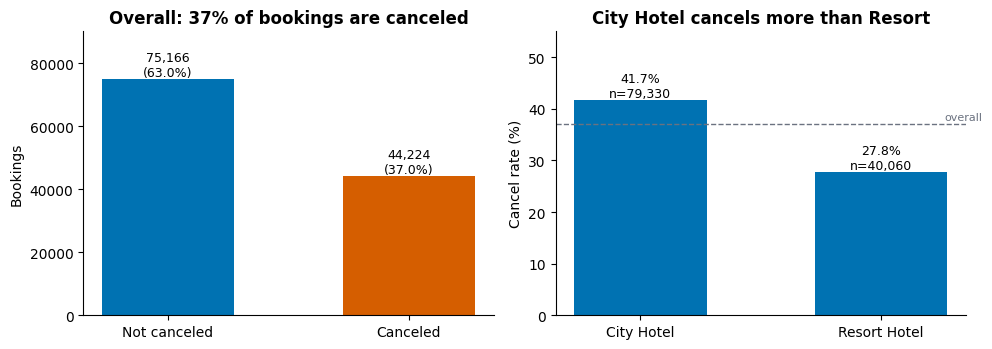

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

counts = df.is_canceled.value_counts().sort_index()
axes[0].bar(["Not canceled", "Canceled"], counts.values, color=[BLUE, ORANGE], width=0.55)
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}\n({v/len(df):.1%})", ha="center", va="bottom", fontsize=9)
axes[0].set_ylim(0, counts.max() * 1.2)
axes[0].set_title("Overall: 37% of bookings are canceled")
axes[0].set_ylabel("Bookings")

by_hotel = df.groupby("hotel").is_canceled.agg(["mean", "size"])
axes[1].bar(by_hotel.index, by_hotel["mean"] * 100, color=BLUE, width=0.55)
for i, (m, n) in enumerate(zip(by_hotel["mean"], by_hotel["size"])):
    axes[1].text(i, m * 100, f"{m:.1%}\nn={n:,}", ha="center", va="bottom", fontsize=9)
axes[1].axhline(OVERALL * 100, color=GREY, ls="--", lw=1); axes[1].text(1.42, OVERALL*100+0.8, "overall", color=GREY, fontsize=8, ha="right")
axes[1].set_ylim(0, 55); axes[1].set_ylabel("Cancel rate (%)")
axes[1].set_title("City Hotel cancels more than Resort")
savefig("01_target_balance")

**Takeaway (F5).** The target is **binary and mildly imbalanced: 37.0% canceled**. That is not extreme, so plain accuracy is not useless, but a model that predicts "never cancels" would already score 63%. Any model must beat that baseline, and we should report **precision, recall and F1 / PR-AUC** (not only accuracy). The two hotels differ a lot (**City 41.7% vs Resort 27.8%**), so `hotel` is an important feature.

## 5. Leakage check: which columns are not allowed to be features?

**Why this matters.** A model is only useful if it predicts using information that is available *at the moment we want the prediction*. If a column is only filled in *after* the booking is canceled or completed, the model is "cheating". Although it looks brilliant in testing, it is useless in real life because of the data leakage.

In [16]:
print("reservation_status vs is_canceled (row counts):")
display(pd.crosstab(df.reservation_status, df.is_canceled))

# When was the final status recorded relative to the arrival date?
status_date = pd.to_datetime(df.reservation_status_date)
canceled = df.is_canceled == 1
print(f"\nCanceled bookings whose status date is BEFORE arrival : {(status_date[canceled] < df.arrival_date[canceled]).mean():.1%}")
print(f"Checked-out bookings whose status date is ON/AFTER arrival: {(status_date[~canceled] >= df.arrival_date[~canceled]).mean():.1%}")

reservation_status vs is_canceled (row counts):


is_canceled,0,1
reservation_status,,
Canceled,0,43017
Check-Out,75166,0
No-Show,0,1207



Canceled bookings whose status date is BEFORE arrival : 95.3%
Checked-out bookings whose status date is ON/AFTER arrival: 100.0%


**Takeaway (F6).** `reservation_status` **is the target written in words** (Canceled and No-Show are always `is_canceled = 1`, Check-Out is always 0). `reservation_status_date` is the date that outcome was recorded (for canceled bookings it is the cancellation date, before arrival 95% of the time). **Both must be dropped as features.** (`reservation_status_date` is still useful for building the Task 3 target, the days between cancellation and arrival, but never as an input.) Including them would give a near-perfect score that means nothing. 

**Softer, timing-related risks.** Some other columns are not the outcome itself, but they get filled in *after* the booking is made, so their values depend on *when* we make the prediction:

| Column | When is it known? | Evidence in data | Risk |
|---|---|---|---|
| `required_car_parking_spaces` | At check-in | **0% of bookings with parking were canceled** (7,416 rows) | High: acts like a "did they show up" flag |
| `assigned_room_type` | At/after check-in | Mismatch with reserved room: 5.4% cancel vs 41.6% | High |
| `booking_changes` | Accumulates between booking and arrival | 0 changes: 41% cancel; 1+: 14-20% | Medium |
| `total_of_special_requests` | Can be added after booking | 0 requests: 48% cancel; 1+: 5-22% | Medium |
| `days_in_waiting_list` | After booking is processed | Waitlisted: 64% cancel vs 36% | Low-medium |
| All other columns | At booking time | | Low |

**Update after the team's *Frame the Problem* section:** the team will forecast at several lead times (30, 14, 7 and 1 days out). The file only stores each booking's *final* values, so we cannot know what `booking_changes` or `total_of_special_requests` looked like 30 days before arrival. Parking and assigned room should be excluded at every horizon. Booking changes and special requests should be excluded, or at least tested with and without, so that no forecast quietly uses information from the future.


## 6. Distributions: what does each attribute look like?

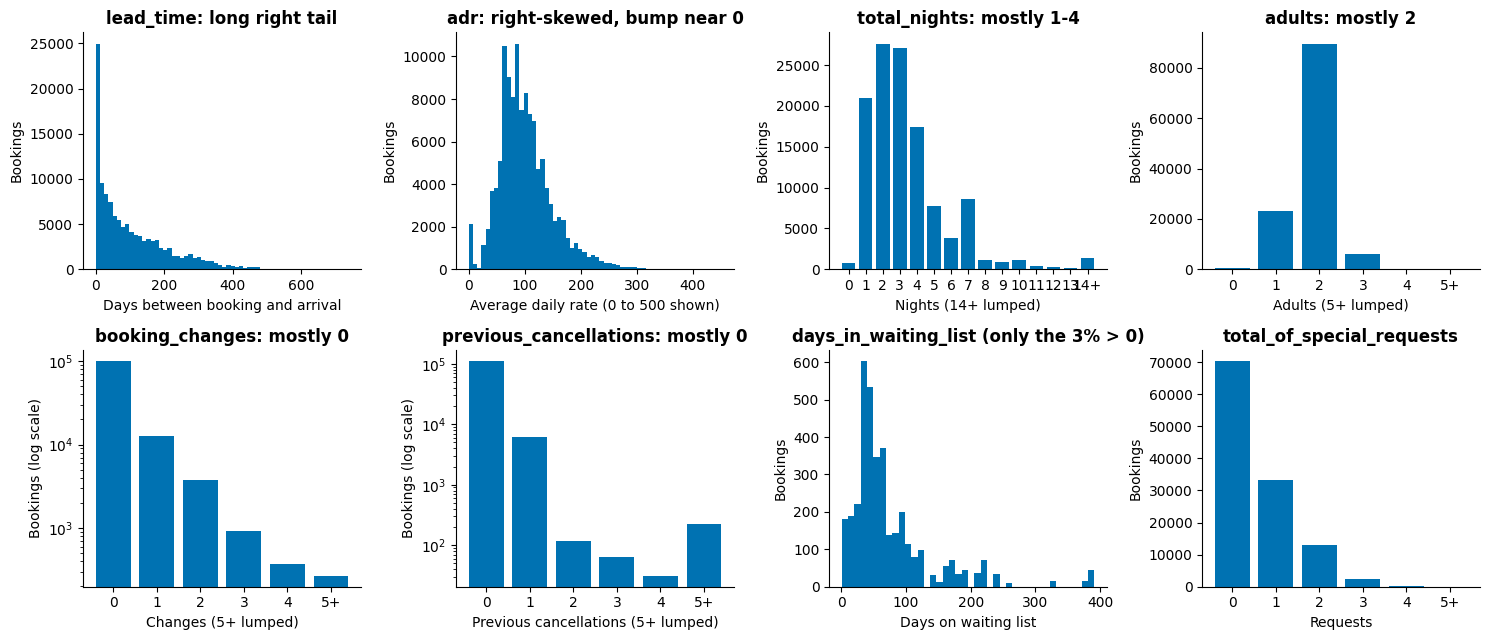

In [17]:
def discrete_bar(ax, s, cap, title, logy=False, xlabel=""):
    """Bar chart of an integer column, lumping everything >= cap into one 'cap+' bar."""
    s = s.clip(upper=cap)
    vc = s.value_counts().sort_index()
    labels = [str(int(i)) if i < cap else f"{int(cap)}+" for i in vc.index]
    ax.bar(labels, vc.values, color=BLUE)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel("Bookings")
    if logy: ax.set_yscale("log"); ax.set_ylabel("Bookings (log scale)")

fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
a = axes.ravel()
a[0].hist(df.lead_time, bins=60, color=BLUE); a[0].set_title("lead_time: long right tail"); a[0].set_xlabel("Days between booking and arrival"); a[0].set_ylabel("Bookings")
a[1].hist(df.adr[(df.adr >= 0) & (df.adr <= 500)], bins=60, color=BLUE); a[1].set_title("adr: right-skewed, bump near 0"); a[1].set_xlabel("Average daily rate (0 to 500 shown)"); a[1].set_ylabel("Bookings")
discrete_bar(a[2], df.total_nights, 14, "total_nights: mostly 1-4", xlabel="Nights (14+ lumped)")
discrete_bar(a[3], df.adults, 5, "adults: mostly 2", xlabel="Adults (5+ lumped)")
discrete_bar(a[4], df.booking_changes, 5, "booking_changes: mostly 0", logy=True, xlabel="Changes (5+ lumped)")
discrete_bar(a[5], df.previous_cancellations, 5, "previous_cancellations: mostly 0", logy=True, xlabel="Previous cancellations (5+ lumped)")
a[6].hist(df.days_in_waiting_list[df.days_in_waiting_list > 0], bins=40, color=BLUE); a[6].set_title("days_in_waiting_list (only the 3% > 0)"); a[6].set_xlabel("Days on waiting list"); a[6].set_ylabel("Bookings")
discrete_bar(a[7], df.total_of_special_requests, 5, "total_of_special_requests", xlabel="Requests")
savefig("02_numeric_distributions")

**Takeaway (F7).** Nearly every numeric column is **heavily right-skewed or "mostly zero"**:

- `lead_time`, `adr` and `total_nights` have long right tails. A **log or square-root transform** (or bucketing) will help linear / distance-based models; tree models do not care.
- `booking_changes`, `previous_cancellations`, `previous_bookings_not_canceled`, `days_in_waiting_list`, `babies` and `children` are 90-99% zeros. For these, a **yes/no flag** (`has_changes`, `has_history`, `was_waitlisted`) often carries all of the signal.
- Nothing is close to a bell curve, so we should avoid models that assume normally distributed inputs without transforming first.

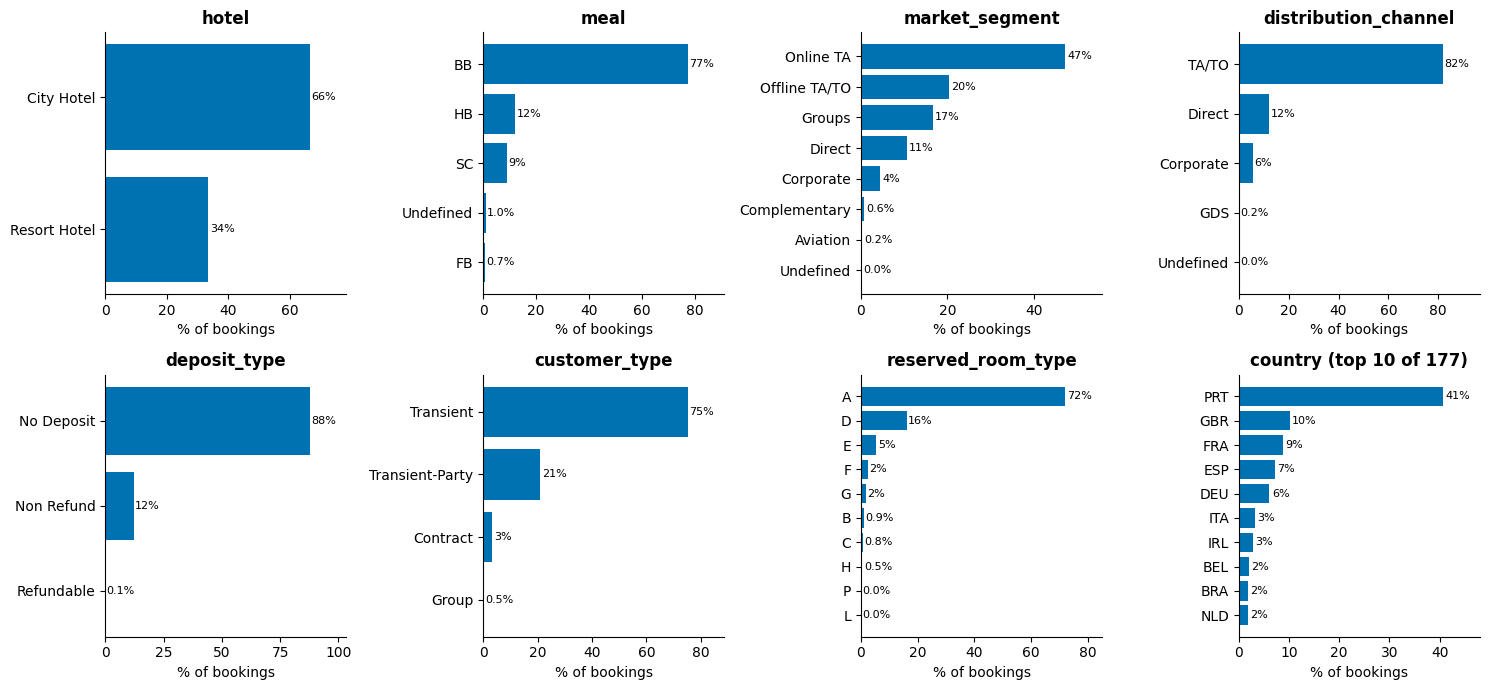

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
a = axes.ravel()
top_countries = df.country.value_counts().head(10)
panels = [("hotel", df.hotel.value_counts()), ("meal", df.meal.value_counts()),
          ("market_segment", df.market_segment.value_counts()), ("distribution_channel", df.distribution_channel.value_counts()),
          ("deposit_type", df.deposit_type.value_counts()), ("customer_type", df.customer_type.value_counts()),
          ("reserved_room_type", df.reserved_room_type.value_counts()), ("country (top 10 of 177)", top_countries)]
for ax, (name, vc) in zip(a, panels):
    pct = vc / len(df) * 100
    ax.barh(pct.index[::-1], pct.values[::-1], color=BLUE)
    for y, v in enumerate(pct.values[::-1]):
        ax.text(v + 0.5, y, f"{v:.0f}%" if v >= 1 else f"{v:.1f}%", va="center", fontsize=8)
    ax.set_title(name); ax.set_xlabel("% of bookings"); ax.set_xlim(0, pct.max() * 1.18)
savefig("03_categorical_distributions")

**Takeaway (F8).** The categorical columns are **dominated by one or two levels** (Online TA = 47% of bookings, TA/TO = 82% of channels, Transient = 75% of customers, room type A = 72%, Portugal = 41% of guests). Two practical consequences: (1) rare levels (e.g. `Refundable` deposit = 162 rows, `Undefined` segments = 2 rows) are too small to learn from and should be merged or ignored; (2) `country` has 177 values, so one-hot encoding would add 177 columns. **Group countries outside the top ~10 into "Other"**, or use target / frequency encoding inside the cross-validation pipeline.

## 7. What drives cancellation? Cancel rate by attribute

For each chart below, the bar height is the **cancel rate for that group** and the dashed line is the overall rate (37.0%). The small `n=` labels show how many bookings are in each group, because a high rate on a tiny group is not reliable.

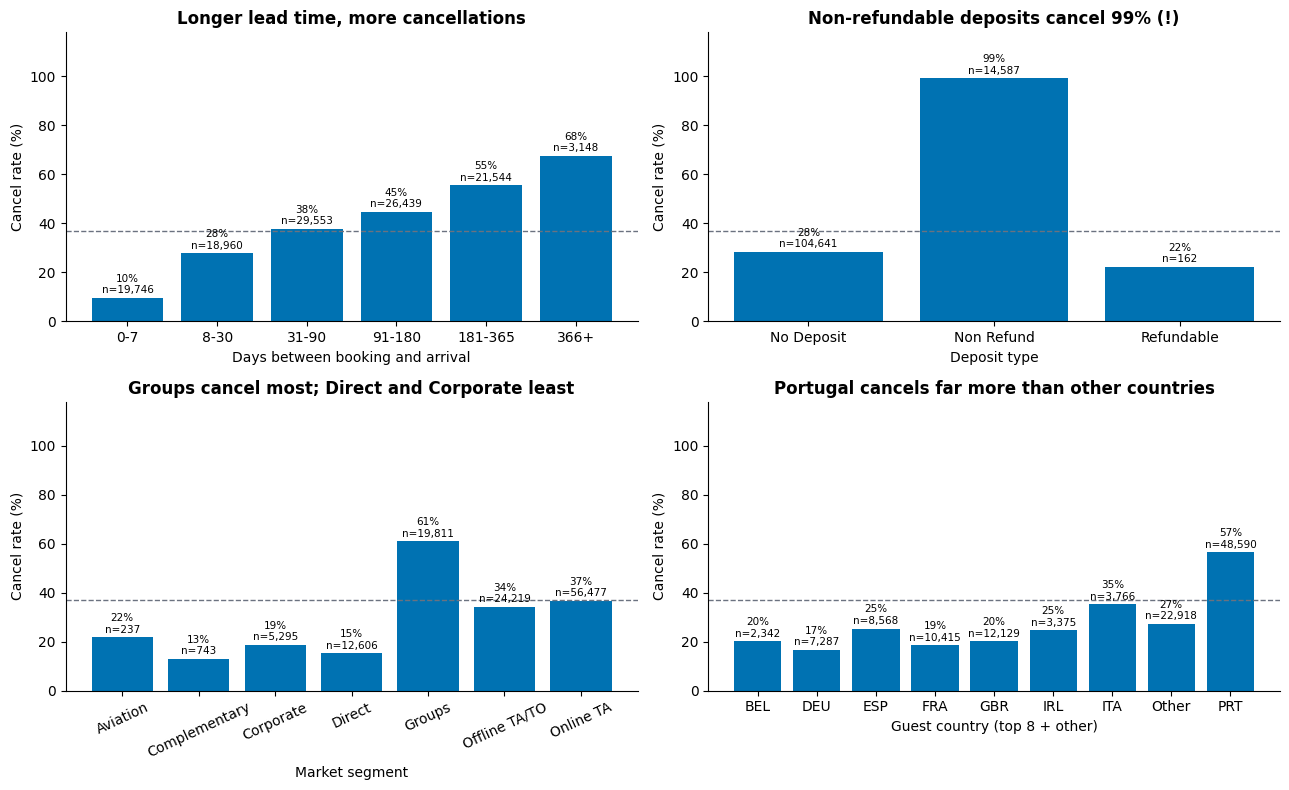

In [19]:
def cancel_rate(ax, col, title, xlabel="", order=None, min_n=0, rotate=0, data=None):
    d = df if data is None else data
    g = d.groupby(col, observed=True).is_canceled.agg(["mean", "size"])
    g = g[g["size"] >= min_n]
    if order is not None: g = g.reindex([o for o in order if o in g.index])
    ax.bar(g.index.astype(str), g["mean"] * 100, color=BLUE)
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(i, m * 100 + 1, f"{m*100:.0f}%\nn={n:,}", ha="center", va="bottom", fontsize=7.5)
    ax.axhline(d.is_canceled.mean() * 100, color=GREY, ls="--", lw=1)
    ax.set_ylim(0, 118); ax.set_ylabel("Cancel rate (%)"); ax.set_xlabel(xlabel); ax.set_title(title)
    ax.tick_params(axis="x", rotation=rotate)

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
cancel_rate(axes[0,0], "lead_bin", "Longer lead time, more cancellations", "Days between booking and arrival")
cancel_rate(axes[0,1], "deposit_type", "Non-refundable deposits cancel 99% (!)", "Deposit type")
cancel_rate(axes[1,0], "market_segment", "Groups cancel most; Direct and Corporate least", "Market segment", rotate=25, min_n=10)
cancel_rate(axes[1,1], df.country.where(df.country.isin(df.country.value_counts().head(8).index), "Other"),
            "Portugal cancels far more than other countries", "Guest country (top 8 + other)", rotate=0)
savefig("04_cancel_rate_main_drivers")

**Takeaway (F9): the strongest and most reliable drivers.**

- **Lead time:** cancel rate rises steadily from **10% (booked within a week)** to **68% (booked more than a year ahead)**. Intuitively, the further ahead you book, the more time life has to change your plans. This is a clean, explainable relationship and a good lead point for the slides.
- **Market segment:** **Groups cancel 61%**, Online TA 37%, Offline TA/TO 34%, versus **Direct 15% and Corporate 19%**.
- **Country:** **Portugal cancels 57%**, while the UK, France, Germany and Belgium are all 17-20%. (Both hotels are in Portugal, so these are mostly domestic bookings.)
- **Deposit type:** see the anomaly in F11 before trusting this one.

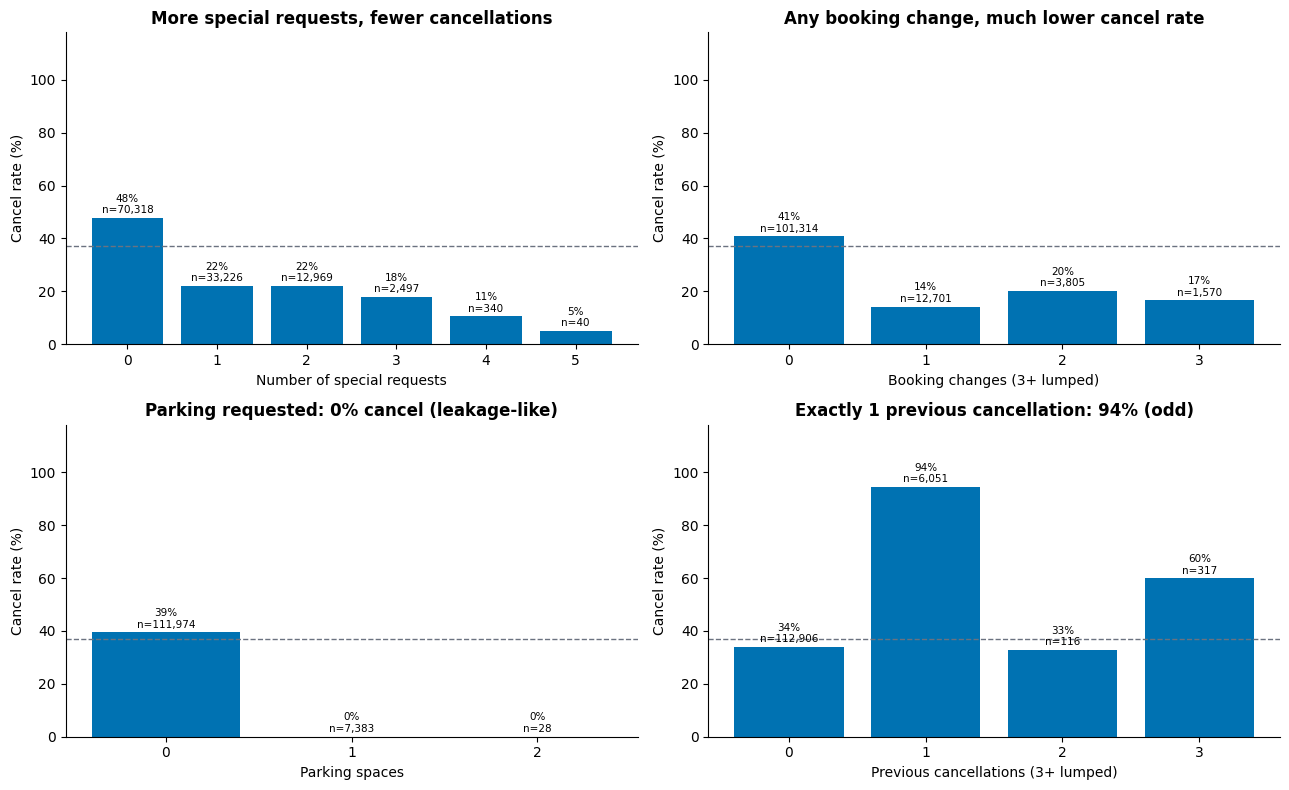

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
cancel_rate(axes[0,0], "total_of_special_requests", "More special requests, fewer cancellations", "Number of special requests")
cancel_rate(axes[0,1], df.booking_changes.clip(upper=3).rename("changes"), "Any booking change, much lower cancel rate", "Booking changes (3+ lumped)")
cancel_rate(axes[1,0], "required_car_parking_spaces", "Parking requested: 0% cancel (leakage-like)", "Parking spaces", min_n=10)
cancel_rate(axes[1,1], df.previous_cancellations.clip(upper=3).rename("prev"), "Exactly 1 previous cancellation: 94% (odd)", "Previous cancellations (3+ lumped)")
savefig("05_cancel_rate_behaviour")

**Takeaway (F10).** Booking *behaviour* columns are strong too: **no special requests = 48% cancel vs about 22% with one or more**, **no booking changes = 41% vs 14-20% with changes**, and **no parking = 39% vs 0% with parking**. As explained in F6, these are recorded after booking, so they carry a timing risk and the team must decide whether they are allowed. The `previous_cancellations` pattern is not what we expected (more previous cancellations should mean *more* risk, but 2+ drops to about 30%), which leads into the next finding.

In [21]:
# --- Investigating the two odd patterns: Non Refund deposits and previous_cancellations == 1
nr = df[df.deposit_type == "Non Refund"]
print("NON REFUND DEPOSIT bookings:", f"{len(nr):,}", f"({len(nr)/len(df):.1%} of data), cancel rate {nr.is_canceled.mean():.1%}")
print(f"  from Portugal: {(nr.country == 'PRT').mean():.1%}   City Hotel: {(nr.hotel == 'City Hotel').mean():.1%}")
display(nr.groupby("market_segment").is_canceled.agg(cancel_rate="mean", n="size").round(3))
print(f"  of these, rows that are exact duplicates: {df.loc[nr.index].duplicated(subset=ORIGINAL_COLS, keep=False).mean():.1%} (incl. originals)")

dd = df.drop_duplicates(subset=ORIGINAL_COLS)
print("\nAFTER DROPPING EXACT DUPLICATES:")
display(dd.groupby("deposit_type").is_canceled.agg(cancel_rate="mean", n="size").round(3))

p1 = df[df.previous_cancellations == 1]
print(f"\nprevious_cancellations == 1: {len(p1):,} rows, cancel rate {p1.is_canceled.mean():.1%}")
print(f"  from Portugal {(p1.country=='PRT').mean():.0%}; also Non Refund {(p1.deposit_type=='Non Refund').mean():.0%}; Groups segment {(p1.market_segment=='Groups').mean():.0%}")

NON REFUND DEPOSIT bookings: 14,587 (12.2% of data), cancel rate 99.4%
  from Portugal: 97.2%   City Hotel: 88.2%


,cancel_rate,n
market_segment,,
Corporate,0.934,334
Direct,0.842,19
Groups,0.993,9172
Offline TA/TO,0.999,5006
Online TA,0.946,56


  of these, rows that are exact duplicates: 98.1% (incl. originals)

AFTER DROPPING EXACT DUPLICATES:


,cancel_rate,n
deposit_type,,
No Deposit,0.267,86251
Non Refund,0.947,1038
Refundable,0.243,107



previous_cancellations == 1: 6,051 rows, cancel rate 94.4%
  from Portugal 96%; also Non Refund 58%; Groups segment 54%


**Takeaway (F11): two anomalies that do not look like real behaviour.**

1. **Non-refundable deposits cancel 99.4% of the time.** Common sense says people with a non-refundable deposit should cancel *least* (they lose money). Instead, 14,587 bookings (12% of data) are almost all cancellations. They are **97% from Portugal and almost all in the Groups or Offline TA/TO segments**, and the pattern is identical in 2015, 2016 and 2017. A likely explanation is that these hotels recorded some group or agency block reservations as "non-refund" and then canceled them in bulk, i.e. a **data-entry / business-process artifact rather than guest behaviour**. This is a hypothesis; we have no way to verify it from the file.
2. **Exactly one previous cancellation means 94% cancel**, but 2+ is only about 30%. 96% of those rows are from Portugal and 58% are also Non Refund, so this is the **same population** as above.

**Why it matters.** (a) A model will simply learn "Non Refund => canceled" and report a great score; that is real in this dataset but it will **not generalise to another hotel** and makes for a weak business story. (b) **After removing duplicates, the Non Refund group shrinks from 14,587 to 1,038 rows** (it is 42% of the duplicate rows, and 98% of Non Refund rows belong to a group of identical rows), though the remaining 1,038 still cancel 94.7%. So **de-duplication (F3) removes most, but not all, of the problem.**

**Recommendation:** report model performance both with and without `deposit_type`, and say clearly in the limitations that this field behaves oddly in this dataset.

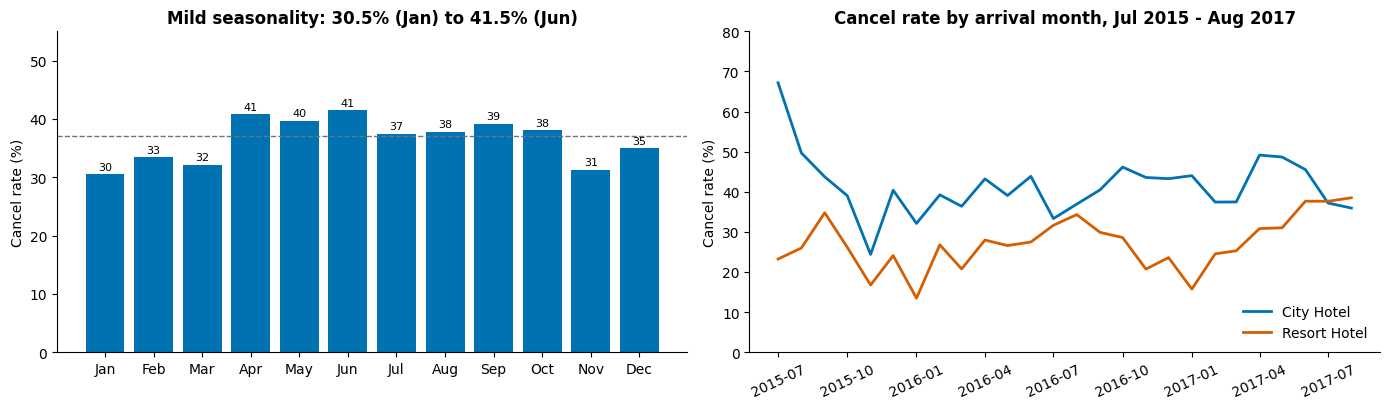

Arrival dates run from 2015-07-01 to 2017-08-31
Yearly cancel rate: {2015: 37.0, 2016: 35.9, 2017: 38.7}


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))

# Cancel rate by calendar month (Jul/Aug appear in 3 years, other months in 2)
mon = df.groupby("arrival_date_month").is_canceled.mean().reindex(MONTH_ORDER) * 100
axes[0].bar([m[:3] for m in MONTH_ORDER], mon.values, color=BLUE)
axes[0].axhline(OVERALL * 100, color=GREY, ls="--", lw=1)
axes[0].set_ylim(0, 55); axes[0].set_ylabel("Cancel rate (%)"); axes[0].set_title("Mild seasonality: 30.5% (Jan) to 41.5% (Jun)")
for i, v in enumerate(mon.values): axes[0].text(i, v + 0.8, f"{v:.0f}", ha="center", fontsize=8)

# Cancel rate over time, by hotel
ym = df.groupby([df.arrival_date.dt.to_period("M").dt.to_timestamp(), "hotel"]).is_canceled.mean().unstack() * 100
axes[1].plot(ym.index, ym["City Hotel"], color=BLUE, lw=2, label="City Hotel")
axes[1].plot(ym.index, ym["Resort Hotel"], color=ORANGE, lw=2, label="Resort Hotel")
axes[1].set_ylim(0, 80); axes[1].set_ylabel("Cancel rate (%)"); axes[1].set_title("Cancel rate by arrival month, Jul 2015 - Aug 2017")
axes[1].legend(frameon=False, loc="lower right"); axes[1].tick_params(axis="x", rotation=25)
savefig("06_time_patterns")
print("Arrival dates run from", df.arrival_date.min().date(), "to", df.arrival_date.max().date())
print("Yearly cancel rate:", (df.groupby("arrival_date_year").is_canceled.mean() * 100).round(1).to_dict())

**Takeaway (F12).** Seasonality exists but is **mild** (30.5% in January to 41.5% in June), and the yearly rate is stable (37.0%, 35.9%, 38.7%). The City Hotel is consistently above the Resort. Since the data covers **26 months (Jul 2015 to Aug 2017)**, we have a real choice: a **random split** (simple, but optimistic) or a **time-based split** (train on earlier months, test on the latest ones, which is closer to how a hotel would really use the model). We recommend a time-based hold-out for the final test set if the team has time, and say why in the slides.

## 8. Correlations

**Plain-English guide.** A correlation of +1 means "when A goes up, B always goes up", -1 means the opposite, 0 means no *straight-line* relationship. Correlation only captures straight-line patterns for numbers; it cannot see that a *category* (like deposit type) matters. So we use two tools: **Pearson correlation** for numbers, and **Cramér's V** (0 = unrelated, 1 = fully determines) for categories.

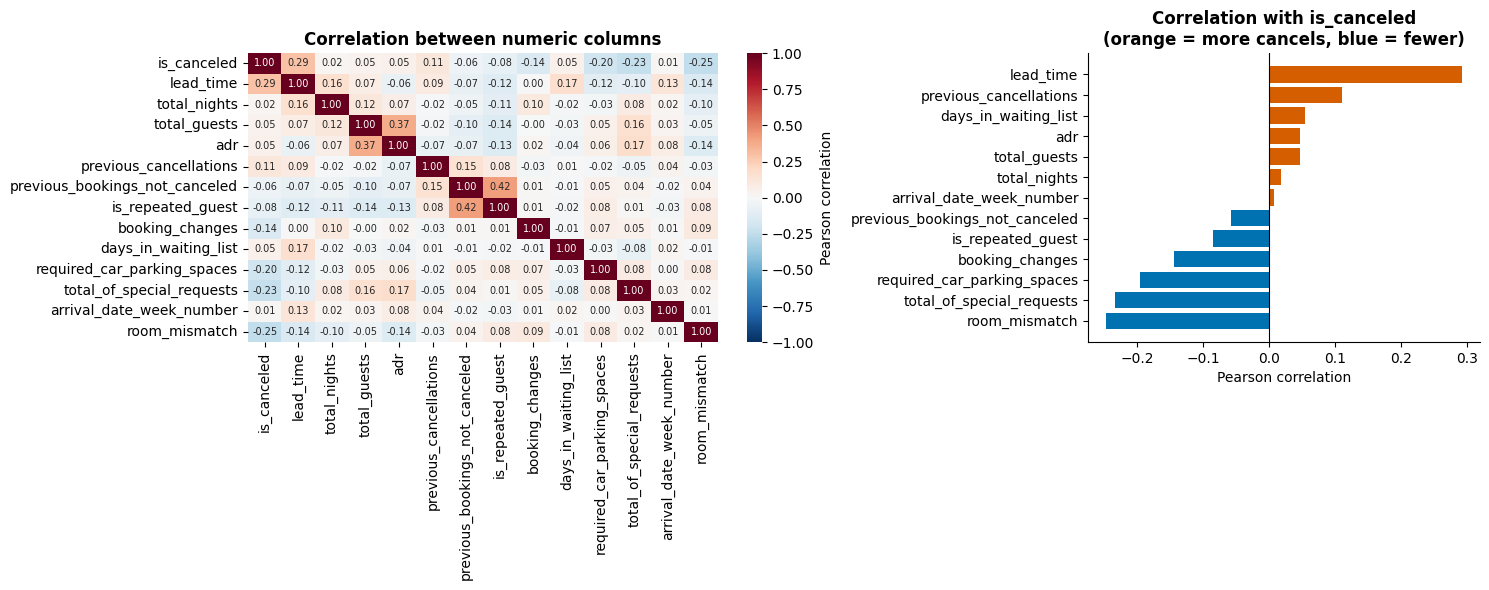

In [23]:
num_cols = ["is_canceled", "lead_time", "total_nights", "total_guests", "adr", "previous_cancellations",
            "previous_bookings_not_canceled", "is_repeated_guest", "booking_changes", "days_in_waiting_list",
            "required_car_parking_spaces", "total_of_special_requests", "arrival_date_week_number", "room_mismatch"]
corr = df[num_cols].corr()

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.5, 1]})
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[0],
            cbar_kws={"label": "Pearson correlation"}, annot_kws={"fontsize": 7})
axes[0].set_title("Correlation between numeric columns")

t = corr["is_canceled"].drop("is_canceled").sort_values()
axes[1].barh(t.index, t.values, color=[ORANGE if v > 0 else BLUE for v in t.values])
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_title("Correlation with is_canceled\n(orange = more cancels, blue = fewer)")
axes[1].set_xlabel("Pearson correlation")
savefig("07_numeric_correlations")

**Takeaway (F13).** Against the target, the strongest straight-line relationships are **lead_time (+0.29)**, **special requests (-0.23)**, **parking (-0.20)**, **booking changes (-0.14)** and **previous cancellations (+0.11)**. The strongest of all is `room_mismatch` (-0.25), the timing-risk column from F6 (reserved and assigned room differ), so it should not be trusted. All are modest; no single number explains cancellation, which is a good sign that a multi-feature model will add value over a one-rule baseline. Between the features themselves, overlap is limited: the only pairs above 0.3 are `previous_bookings_not_canceled` with `is_repeated_guest` (0.42, both describe repeat guests) and `total_guests` with `adr` (0.37, more guests means a higher nightly price). `arrival_date_week_number` and the month encode the same information, as noted in the data dictionary.

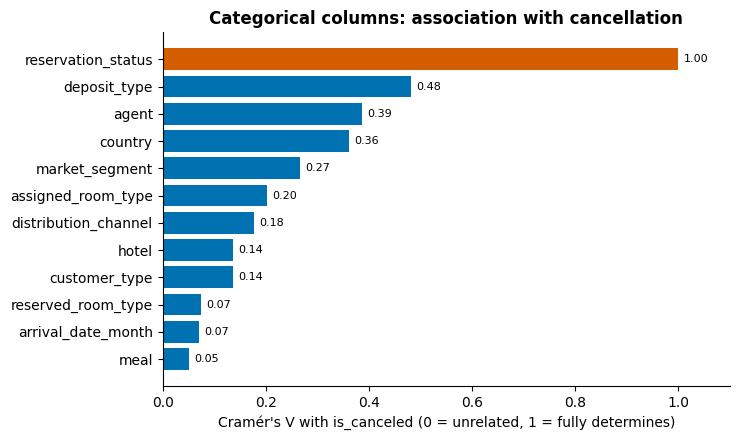

Cramér's V between pairs of categorical features (high = redundant):
        market_segment vs distribution_channel  : 0.69
    reserved_room_type vs assigned_room_type    : 0.78
        market_segment vs customer_type         : 0.28


In [24]:
def cramers_v(a, b):
    """Strength of association between two categorical variables, 0 (none) to 1 (perfect)."""
    ct = pd.crosstab(a, b)
    chi2 = chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum()
    return np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

cats = ["deposit_type", "country", "market_segment", "agent", "reserved_room_type", "assigned_room_type",
        "customer_type", "distribution_channel", "hotel", "arrival_date_month", "meal", "reservation_status"]
cv = pd.Series({c: cramers_v(df[c].fillna("MISSING").astype(str), df.is_canceled) for c in cats}).sort_values()

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.barh(cv.index, cv.values, color=[ORANGE if c == "reservation_status" else BLUE for c in cv.index])
for y, v in enumerate(cv.values): ax.text(v + 0.01, y, f"{v:.2f}", va="center", fontsize=8)
ax.set_xlim(0, 1.1); ax.set_xlabel("Cramér's V with is_canceled (0 = unrelated, 1 = fully determines)")
ax.set_title("Categorical columns: association with cancellation")
savefig("08_categorical_association")

# Redundancy between pairs of categorical columns
print("Cramér's V between pairs of categorical features (high = redundant):")
for a, b in [("market_segment", "distribution_channel"), ("reserved_room_type", "assigned_room_type"), ("market_segment", "customer_type")]:
    print(f"  {a:>20} vs {b:<22}: {cramers_v(df[a], df[b]):.2f}")

**Takeaway (F14).** Among categories, **`reservation_status` (1.00)** is the leakage column (it fully determines the target) and should be ignored. Of the legitimate features, **`deposit_type` (0.48), `agent` (0.39), `country` (0.36) and `market_segment` (0.27)** are the most associated with cancellation. `deposit_type` is high largely because of the anomaly in F11. The pair checks show `market_segment` and `distribution_channel` overlap heavily, and `reserved_room_type` and `assigned_room_type` overlap, so we do not need both of each pair.

## 9. Promising transformations and extra data

### Transformations to try in *Prepare the Data*

| Idea | Why | Applies to |
|---|---|---|
| Drop exact duplicates **before** the train/test split | Prevents identical rows appearing in both sets (F3); check the effect on per-night room counts | whole table |
| Drop `reservation_status`, `reservation_status_date` | Leakage (F6) | 2 columns |
| Decide whether to drop the "late-known" group | Timing leakage (F6) | `required_car_parking_spaces`, `assigned_room_type`, `booking_changes`, `total_of_special_requests`, `days_in_waiting_list` |
| Convert missing `agent` / `company` into a 'None' category, `company` into `has_company` | Missing means 'none', which is informative (F2) | `agent`, `company` |
| Group rare countries / agents into 'Other' | Avoids 177+ one-hot columns (F8) | `country`, `agent` |
| Merge `Undefined` meal into `SC` | Same meaning | `meal` |
| `total_nights`, `total_guests`, `is_family`, `has_babies` | Combine weak columns into one stronger one | stay and guest columns |
| Flags: `has_changes`, `was_waitlisted`, `has_history` | 90-99% zeros, the yes/no carries the signal (F7) | several count columns |
| Log or sqrt transform; cap at 99th percentile | Right skew and outliers (F7, F4) | `lead_time`, `adr`, `total_nights` |
| Lead-time buckets | Cancel rate is non-linear in lead time (F9) | `lead_time` |
| Date features: day of week, month number (cyclical), `is_weekend_arrival` | Stronger than day-of-month | arrival date |
| Ordered month or cyclic (sin/cos) encoding | Months are circular (Dec is next to Jan) | `arrival_date_month` |
| Impute, scale and encode **inside a scikit-learn Pipeline**, fit on train only | Avoids leakage, required by the rubric | all |

### Extra data that would be useful
- **A booking ID / guest ID:** would let us separate true duplicates from separate bookings and see a guest's history (F3).
- **Cancellation policy per booking** (free until X days before arrival): the real driver behind the deposit pattern (F11).
- **The cancellation timestamp**, not just the final status date, to model *when* cancellations happen, not just whether.
- **Price relative to the market** (competitor rates, discounts, whether the room was a promotion), because ADR alone is weakly predictive.
- **Local events / holiday calendar and weather:** these drive both demand and cancellation.
- **Hotel capacity and daily occupancy:** needed to turn a prediction into dollars (how many rooms could be resold, overbooking risk).
- **Cost inputs for the value case:** cost of an empty room night and cost of relocating a guest if we overbook and everyone shows up. These decide how many false positives vs false negatives we can afford.

## 10. Summary of what we learned

**Big picture.** Cancellation is a real, material problem: **37% of all bookings are canceled** (28% after removing duplicates). It is a binary classification task with a usable target and enough rows (119k, or about 87k after de-duplication) to model well within our timeline.

**Seven things the team should know**

1. **Two columns are the answer in disguise** (`reservation_status`, `reservation_status_date`). Drop them (F6).
2. **26.8% of rows are exact duplicates**, and they inflate the cancel rate from 27.5% to 37.0% and risk leaking between train and test. De-duplicate before splitting (F3), but check the effect on the per-night room forecast.
3. **Lead time is the cleanest driver**: 10% cancel within a week of booking, 68% more than a year out (F9).
4. **Who books matters**: Groups (61%) and Portuguese guests (57%) cancel most; Direct (15%) and Corporate (19%) least (F9).
5. **`deposit_type = Non Refund` cancels 99%**, which is backwards from common sense and looks like a record-keeping artifact. Report results with and without it (F11).
6. **Several columns are only known after booking** (parking, assigned room, changes, special requests). The team's framing forecasts at 30, 14, 7 and 1 days out, and the file only stores final values, so these columns should be excluded or handled carefully (F6).
7. **Data is clean otherwise**: only 4 columns have missing values, and for 2 of those the missing value means "none" (F2). Skewed numbers need transforming (F7).

**Decisions for the team (status after the *Frame the Problem* section)**

| # | Decision | Status and recommendation |
|---|---|---|
| 1 | Prediction moment | **Settled:** forecasts at 30, 14, 7 and 1 days out. Limit features to what would be known at each horizon. |
| 2 | Drop exact duplicates? | **Open.** Protects the classifier from train/test leakage, but may undercount rooms in the per-night forecast. Run the forecast both ways. |
| 3 | Keep `deposit_type`? | Keep, report with and without, flag as a limitation. |
| 4 | Random or time-based split? | **Settled:** time-based. Use time-ordered cross-validation inside the training period. |
| 5 | Which metric? | **Settled:** MAE by lead time and interval coverage (forecast); ROC-AUC, precision and calibration (classifier); revenue recovered (business). |

**Limitations of this dataset (for the slides).** Only two hotels, both in Portugal, 2015-2017; no booking or guest ID; only final booking values are stored (we cannot see what was known N days before arrival); no price context; and the odd `deposit_type` behaviour means the model may not transfer to other hotels.

## 11. Prepare the Data — Cleaning, Feature Engineering, and Scaling

**Purpose.** Turn the **original 32-column `raw` data** from Section 1 into leakage-aware, model-ready train / validation / test matrices for **Task 2: `is_canceled`**. The EDA cells and results above are unchanged. This section implements the key preparation ideas from F2–F14.

**Checklist coverage**

| Assignment requirement | Implementation below |
|---|---|
| Outliers (optional) | Remove impossible negative ADR / zero-guest rows; cap upper-tail numeric values at a **training-only** quantile |
| Missing values | Four missing fields: `children → 0`, `agent → NO_AGENT`, `country → UNKNOWN`, `company → has_company`; other numeric/categorical gaps handled by imputers |
| Feature selection (optional) | Exclude the target, final-status leakage, timing-risk features, redundant dates, and unhelpful company ID |
| Feature engineering | Lead-time buckets, log transforms, stay/guest aggregates, historical cancellation rate, interactions, calendar and geographic features |
| Feature scaling | `StandardScaler` for numeric features; train-fitted One-Hot Encoding for categoricals |

**Prediction-time assumption (important).** This is a **booking-time / baseline cancellation classification** feature set. The team's future 30/14/7/1-days-before-arrival predictions require historical booking *snapshots* and eligibility labels at each horizon, which this final-status dataset does **not** provide. Do not interpret this notebook as a fully validated snapshot-based horizon forecast.

**Leakage policy.** The source table has no booking ID. We compare de-duplicated results with the full dataset in later experiments. We remove exact duplicates **before the split** for this classifier and split chronologically by **arrival date**, reserving the most recent dates for final evaluation. Learned clipping limits, imputations, rare-category groups and scalers are fitted on **training data only**. For time-series CV, refit the **entire Pipeline** within each fold, rather than CV on a once-preprocessed training matrix.

### 11.1 Remove duplicates and impossible records

We retain the original `raw` unchanged. `adr = 0` can represent a complimentary stay, and `total_nights = 0` may represent an unusual/day-use record, so neither is automatically discarded. Extremely long stays and long lead times can be real and will be **capped rather than deleted**. We remove records with **zero guests** or **negative ADR** as a conservative baseline. This cleaning policy should be tested for sensitivity.

In [25]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from scipy import sparse
from IPython.display import display

# Settings for the downstream experiments.
DROP_DEPOSIT_TYPE = False          # Rerun preparation with True for F11 robustness check.
OUTLIER_UPPER_QUANTILE = 0.995     # Fit cutoffs on training data only.
RARE_CATEGORY_MIN_COUNT = 100     # OneHotEncoder groups rare levels using training counts.

clean = raw.copy()
original_n = len(clean)
exact_duplicates = int(clean.duplicated().sum())
clean = clean.drop_duplicates().copy()

guest_count = clean["adults"] + clean["children"].fillna(0) + clean["babies"]
invalid_guest = guest_count <= 0
invalid_adr = clean["adr"] < 0
invalid_mask = invalid_guest | invalid_adr
print(f"Original bookings:         {original_n:,}")
print(f"Exact duplicate rows:      {exact_duplicates:,}")
print(f"Zero-guest rows removed:   {invalid_guest.sum():,}")
print(f"Negative-ADR rows removed: {invalid_adr.sum():,}")

clean = clean.loc[~invalid_mask].copy().reset_index(drop=True)
print(f"Bookings after cleaning:   {len(clean):,}")
print(f"Remaining target rate:     {clean['is_canceled'].mean():.1%}")
assert clean["is_canceled"].isin([0, 1]).all()
assert not clean.duplicated().any()

Original bookings:         119,390
Exact duplicate rows:      31,994
Zero-guest rows removed:   166
Negative-ADR rows removed: 1
Bookings after cleaning:   87,229
Remaining target rate:     27.5%


### 11.2 Chronological train / validation / test split (70% / 15% / 15% of unique arrival dates)

The boundaries use **unique arrival dates**, not a random sample. No arrival date appears in two partitions; this is a retrospective hold-out design, not yet the historical-snapshot dataset required for rolling forecasts. **Do not inspect the validation/test sets to choose imputation or clipping thresholds.**

In [26]:
split_data = clean.copy()
split_data["_arrival_date"] = pd.to_datetime({
    "year": split_data["arrival_date_year"],
    "month": split_data["arrival_date_month"].map(MONTH_NUM),
    "day": split_data["arrival_date_day_of_month"],
}, errors="raise")
split_data = split_data.sort_values("_arrival_date", kind="stable").reset_index(drop=True)

unique_dates = split_data["_arrival_date"].drop_duplicates().sort_values().to_numpy()
i_train = int(len(unique_dates) * 0.70)
i_valid = int(len(unique_dates) * 0.85)
assert 0 < i_train < i_valid < len(unique_dates), "Need at least 3 distinct time periods."
train_end = pd.Timestamp(unique_dates[i_train - 1])
valid_end = pd.Timestamp(unique_dates[i_valid - 1])

train_df = split_data.loc[split_data._arrival_date <= train_end].copy()
valid_df = split_data.loc[(split_data._arrival_date > train_end)
                          & (split_data._arrival_date <= valid_end)].copy()
test_df  = split_data.loc[split_data._arrival_date > valid_end].copy()

def make_xy(partition):
    X = partition.drop(columns=["is_canceled", "_arrival_date"]).reset_index(drop=True)
    y = partition["is_canceled"].astype(int).reset_index(drop=True)
    return X, y

X_train_raw, y_train = make_xy(train_df)
X_valid_raw, y_valid = make_xy(valid_df)
X_test_raw,  y_test  = make_xy(test_df)

split_report = pd.DataFrame([
    {"split": label, "rows": len(part),
     "start": part._arrival_date.min().date(), "end": part._arrival_date.max().date(),
     "cancellation_rate": round(part.is_canceled.mean(), 3)}
    for label, part in [("Train", train_df), ("Validation", valid_df), ("Test", test_df)]
])
display(split_report)
assert len(train_df) + len(valid_df) + len(test_df) == len(clean)
assert train_df._arrival_date.max() < valid_df._arrival_date.min()
assert valid_df._arrival_date.max() < test_df._arrival_date.min()

,split,rows,start,end,cancellation_rate
0,Train,56132,2015-07-01,2017-01-05,0.251
1,Validation,14009,2017-01-06,2017-05-04,0.286
2,Test,17088,2017-05-05,2017-08-31,0.347


### 11.3 Feature selection and feature creation

**Excluded (leakage / timing risk):** `reservation_status`, `reservation_status_date`, `assigned_room_type`, `booking_changes`, `days_in_waiting_list`, `required_car_parking_spaces`, and `total_of_special_requests` (see F6). We also remove original date components *after* extracting calendar features, the high-missingness `company` ID (retaining `has_company`), and `distribution_channel` (strongly overlaps with `market_segment`, F14).

**Constructed:** `total_nights`, `zero_night_stay`, `weekend_ratio`, `total_guests`, `is_family`, `has_babies`, `adr_per_guest`, `has_history`, `history_count`, `historical_cancel_rate`, `lead_time_bucket`, `lead_time_log`, `adr_log`, `total_nights_log`, `is_domestic`, `hotel_market_segment`, `long_lead_group`, `arrival_dayofweek`, `is_weekend_arrival`, `month_sin`, and `month_cos`.

The engineered `historical_cancel_rate` is set to 0 for guests with no history and differentiated by `has_history`; `adr_per_guest` and `weekend_ratio` are left missing when their denominator is zero and later imputed by the training-only pipeline. `agent` is an ID, so it must be a **category**, not a continuous number.

In [27]:
class BookingFeatureEngineer(BaseEstimator, TransformerMixin):
    """Stateless, booking-time feature construction; safe within CV folds."""
    LEAKY_OR_POST_BOOKING = [
        "reservation_status", "reservation_status_date", "assigned_room_type",
        "booking_changes", "days_in_waiting_list",
        "required_car_parking_spaces", "total_of_special_requests",
    ]

    def __init__(self, drop_deposit_type=False):
        self.drop_deposit_type = drop_deposit_type

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        d = X.copy()
        month_number = d["arrival_date_month"].map(MONTH_NUM)
        arrival = pd.to_datetime({
            "year": d["arrival_date_year"], "month": month_number,
            "day": d["arrival_date_day_of_month"]
        }, errors="raise")

        # Missing values whose interpretation is established in the EDA.
        d["children"] = d["children"].fillna(0)
        d["country"] = d["country"].fillna("UNKNOWN")
        d["meal"] = d["meal"].replace("Undefined", "SC")
        d["market_segment"] = d["market_segment"].replace("Undefined", "UNKNOWN")
        d["agent"] = d["agent"].map(
            lambda value: "NO_AGENT" if pd.isna(value) else str(int(value))
        )
        d["has_agent"] = (d["agent"] != "NO_AGENT").astype(int)
        d["has_company"] = d["company"].notna().astype(int)

        # Customer and stay aggregates.
        d["total_nights"] = d["stays_in_weekend_nights"] + d["stays_in_week_nights"]
        d["zero_night_stay"] = (d["total_nights"] == 0).astype(int)
        d["weekend_ratio"] = d["stays_in_weekend_nights"] / d["total_nights"].replace(0, np.nan)
        d["total_guests"] = d["adults"] + d["children"] + d["babies"]
        d["is_family"] = ((d["children"] + d["babies"]) > 0).astype(int)
        d["has_babies"] = (d["babies"] > 0).astype(int)
        d["adr_per_guest"] = d["adr"] / d["total_guests"].replace(0, np.nan)

        # Historical behaviour (assumed to reflect *prior* bookings at prediction time).
        d["history_count"] = (d["previous_cancellations"]
                              + d["previous_bookings_not_canceled"])
        d["has_history"] = (d["history_count"] > 0).astype(int)
        d["historical_cancel_rate"] = (
            d["previous_cancellations"] / d["history_count"].replace(0, np.nan)
        ).fillna(0)

        # Nonlinearity: bucket lead time, log-transform large positive quantities.
        d["lead_time_bucket"] = pd.cut(
            d["lead_time"], bins=[-np.inf, 7, 30, 90, 180, 365, np.inf],
            labels=["0-7", "8-30", "31-90", "91-180", "181-365", "366+"]
        ).astype(str)
        d["lead_time_log"] = np.log1p(d["lead_time"].clip(lower=0))
        d["adr_log"] = np.log1p(d["adr"].clip(lower=0))
        d["total_nights_log"] = np.log1p(d["total_nights"].clip(lower=0))

        # Travel market and interactions.
        d["is_domestic"] = (d["country"] == "PRT").astype(int)
        d["hotel_market_segment"] = (d["hotel"].astype(str) + " | "
                                     + d["market_segment"].astype(str))
        d["long_lead_group"] = ((d["lead_time"] > 180)
                                & (d["market_segment"] == "Groups")).astype(int)

        # Cyclic calendar features. Month and week number are not used as independent raw fields.
        d["arrival_dayofweek"] = arrival.dt.dayofweek.astype(str)
        d["is_weekend_arrival"] = (arrival.dt.dayofweek >= 5).astype(int)
        d["month_sin"] = np.sin(2 * np.pi * month_number / 12)
        d["month_cos"] = np.cos(2 * np.pi * month_number / 12)

        drop_cols = self.LEAKY_OR_POST_BOOKING + [
            "is_canceled", "company", "distribution_channel",
            "arrival_date_year", "arrival_date_month", "arrival_date_week_number",
            "arrival_date_day_of_month",
        ]
        if self.drop_deposit_type:
            drop_cols.append("deposit_type")
        d = d.drop(columns=drop_cols, errors="ignore")
        numeric = d.select_dtypes(include="number").columns
        d.loc[:, numeric] = d.loc[:, numeric].replace([np.inf, -np.inf], np.nan)
        return d

# Inspect the deterministic features (no learnt transformations yet).
engineer = BookingFeatureEngineer(drop_deposit_type=DROP_DEPOSIT_TYPE)
preview = engineer.transform(X_train_raw)
print(f"Features before encoding: {preview.shape[1]} ({preview.select_dtypes(include='number').shape[1]} numeric, "
      f"{preview.select_dtypes(exclude='number').shape[1]} categorical)")
display(preview[["lead_time", "lead_time_bucket", "historical_cancel_rate",
                 "total_nights", "total_guests", "hotel_market_segment"]].head(6))
for banned in BookingFeatureEngineer.LEAKY_OR_POST_BOOKING:
    assert banned not in preview.columns, f"Leakage-risk feature remains: {banned}"

Features before encoding: 41 (30 numeric, 11 categorical)


,lead_time,lead_time_bucket,historical_cancel_rate,total_nights,total_guests,hotel_market_segment
0,342,181-365,0.0,0,2.0,Resort Hotel | Direct
1,737,366+,0.0,0,2.0,Resort Hotel | Direct
2,7,0-7,0.0,1,1.0,Resort Hotel | Direct
3,13,8-30,0.0,1,1.0,Resort Hotel | Corporate
4,14,8-30,0.0,2,2.0,Resort Hotel | Online TA
5,0,0-7,0.0,2,2.0,Resort Hotel | Direct


### 11.4 Training-only outlier capping, imputation, encoding, and feature scaling

- **Outliers:** `QuantileCapper` caps the selected right-skewed numeric features at the **99.5th percentile of training rows**; very high ADR/guest counts remain represented but cannot dominate the scaler. Unlike a fixed manually chosen cap, the learnt percentile is estimated inside each training fold.
- **Missing values:** Other numeric gaps use **train median**; categorical gaps use **`UNKNOWN`**. The 4 missing `children` values are a domain-based `0` fill; missing `country` stays an explicit category; `agent` missing is `NO_AGENT`; missing `company` is captured by `has_company`.
- **Encoding:** `OneHotEncoder` uses rare-category aggregation (`min_frequency=100`) and tolerates categories unseen in validation/test. This is especially important for `country` and `agent`.
- **Scaling:** `StandardScaler` standardizes all numeric columns using **train means and standard deviations**; one-hot columns stay 0/1. Trees generally do not need scaling, but this common representation is suitable for linear baselines and model comparison.

All learnt preprocessing is wrapped in one scikit-learn Pipeline, which can be cloned and fitted separately for time-series CV.

In [28]:
class QuantileCapper(BaseEstimator, TransformerMixin):
    """Upper-tail winsorization; learns limits only when fit() is called."""
    def __init__(self, upper_quantile=0.995):
        self.upper_quantile = upper_quantile

    def fit(self, X, y=None):
        array = np.asarray(X, dtype=float)
        self.upper_bounds_ = np.nanquantile(array, self.upper_quantile, axis=0)
        self.n_features_in_ = array.shape[1]
        return self

    def transform(self, X):
        return np.minimum(np.asarray(X, dtype=float), self.upper_bounds_)

    def get_feature_names_out(self, input_features=None):
        if input_features is None:
            return np.array([f"x{i}" for i in range(self.n_features_in_)], dtype=object)
        return np.asarray(input_features, dtype=object)

# Infer types from the stateless engineered training data only.
num_cols_prepared = preview.select_dtypes(include="number").columns.tolist()
cat_cols_prepared = preview.select_dtypes(exclude="number").columns.tolist()
clip_candidates = [
    "adr", "lead_time", "stays_in_weekend_nights", "stays_in_week_nights",
    "adults", "babies", "previous_cancellations", "previous_bookings_not_canceled",
    "history_count", "total_nights", "total_guests", "adr_per_guest"
]
clip_cols = [c for c in clip_candidates if c in num_cols_prepared]
other_num_cols = [c for c in num_cols_prepared if c not in clip_cols]

clip_numeric_steps = Pipeline([
    ("cap", QuantileCapper(upper_quantile=OUTLIER_UPPER_QUANTILE)),
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
other_numeric_steps = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
categorical_steps = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="UNKNOWN")),
    ("encode", OneHotEncoder(handle_unknown="infrequent_if_exist",
                             min_frequency=RARE_CATEGORY_MIN_COUNT)),
])

preprocessor = ColumnTransformer([
    ("capped_num", clip_numeric_steps, clip_cols),
    ("other_num", other_numeric_steps, other_num_cols),
    ("categorical", categorical_steps, cat_cols_prepared),
], remainder="drop", verbose_feature_names_out=True)

# Fit the whole preprocessing chain ONLY on the training portion.
prepare_pipeline = Pipeline([
    ("feature_engineering", BookingFeatureEngineer(drop_deposit_type=DROP_DEPOSIT_TYPE)),
    ("preprocessing", preprocessor),
])
X_train = prepare_pipeline.fit_transform(X_train_raw, y_train)
X_valid = prepare_pipeline.transform(X_valid_raw)
X_test = prepare_pipeline.transform(X_test_raw)
feature_names = prepare_pipeline.named_steps["preprocessing"].get_feature_names_out()

print("Model-ready matrices (rows, encoded columns):")
print("Train:     ", X_train.shape)
print("Validation:", X_valid.shape)
print("Test:      ", X_test.shape)
print("Encoded features:", len(feature_names))

Model-ready matrices (rows, encoded columns):
Train:      (56132, 171)
Validation: (14009, 171)
Test:       (17088, 171)
Encoded features: 171


### 11.5 Quality checks and a preview of standardized features

We verify the absence of NaNs/infinities, that the target is not among the feature names, that no leaky variable survived, and that **all partitions have exactly the same fitted columns**. The train mean of each scaled numeric column should be approximately zero (unless that feature has a degenerate variance).

In [29]:
def finite_matrix(A):
    values = A.data if sparse.issparse(A) else np.asarray(A)
    return bool(np.isfinite(values).all())

assert X_train.shape[0] == len(y_train)
assert X_valid.shape[0] == len(y_valid)
assert X_test.shape[0] == len(y_test)
assert X_train.shape[1] == X_valid.shape[1] == X_test.shape[1]
assert finite_matrix(X_train) and finite_matrix(X_valid) and finite_matrix(X_test)
assert not any("is_canceled" in name for name in feature_names)
assert not any(any(b in name for b in BookingFeatureEngineer.LEAKY_OR_POST_BOOKING)
               for name in feature_names)

n_scaled = len(clip_cols) + len(other_num_cols)
train_numeric = X_train[:, :n_scaled]
scaled_means = np.asarray(train_numeric.mean(axis=0)).ravel()
print("Maximum absolute training mean, standardized numeric features:",
      f"{np.max(np.abs(scaled_means)):.2e}")
assert np.max(np.abs(scaled_means)) < 1e-8

# Small readable sample; do not materialize the full dense matrix.
head = X_train[:5].toarray() if sparse.issparse(X_train) else X_train[:5]
encoded_preview = pd.DataFrame(head[:, :min(12, n_scaled)],
                               columns=feature_names[:min(12, n_scaled)])
display(encoded_preview.round(2))

# Inspect actual learned training-only caps (one row per capped feature).
capper = prepare_pipeline.named_steps["preprocessing"].named_transformers_["capped_num"].named_steps["cap"]
cap_summary = pd.DataFrame({
    "feature": clip_cols,
    f"train_upper_{OUTLIER_UPPER_QUANTILE:.1%}": capper.upper_bounds_,
    "max_before_cap": preview[clip_cols].max().to_numpy()
})
display(cap_summary.round(2))
print("Data preparation checks passed; ready for model training.")

Maximum absolute training mean, standardized numeric features: 1.43e-13


,capped_num__adr,capped_num__lead_time,capped_num__stays_in_weekend_nights,capped_num__stays_in_week_nights,capped_num__adults,capped_num__babies,capped_num__previous_cancellations,capped_num__previous_bookings_not_canceled,capped_num__history_count,capped_num__total_nights,capped_num__total_guests,capped_num__adr_per_guest
0,-2.08,3.41,-1.0,-1.35,0.28,-0.11,-0.16,-0.15,-0.17,-1.40,0.00,-1.94
1,-2.08,3.72,-1.0,-1.35,0.28,-0.11,-0.16,-0.15,-0.17,-1.40,0.00,-1.94
2,-0.51,-0.82,-1.0,-0.82,-1.70,-0.11,-0.16,-0.15,-0.17,-1.00,-1.45,0.82
3,-0.51,-0.74,-1.0,-0.82,-1.70,-0.11,-0.16,-0.15,-0.17,-1.00,-1.45,0.82
4,-0.02,-0.73,-1.0,-0.30,0.28,-0.11,-0.16,-0.15,-0.17,-0.61,0.00,-0.13


,feature,train_upper_99.5%,max_before_cap
0,adr,263.25,5400.0
1,lead_time,367.00,737.0
2,stays_in_weekend_nights,4.00,19.0
3,stays_in_week_nights,10.00,50.0
4,adults,3.00,55.0
5,babies,1.00,10.0
6,previous_cancellations,1.00,26.0
7,previous_bookings_not_canceled,8.00,58.0
8,history_count,9.00,64.0
9,total_nights,14.00,69.0


Data preparation checks passed; ready for model training.


### 11.6 Suggested follow-up experiments and optional save

**Experiment plan.** Compare original vs de-duplicated data (duplicate choice changes the cancel rate); rerun this section with `DROP_DEPOSIT_TYPE=True` to check the suspicious Non Refund artifact (F11); and compare linear versus tree models with/without the engineered features. Keep the **latest-date test set untouched** until final model selection. Use time-ordered CV within `train_df` with the **full `BookingFeatureEngineer → ColumnTransformer → estimator` pipeline inside every fold**.

**Scope limitation.** These matrices are for **classification** (`is_canceled`) only. Do **not** automatically remove exact duplicates from the separate nightly-room-count forecasting task: identical records could represent multiple genuine rooms. Further, `previous_*` variables are used under the assumption that they reflect history known at booking, and `deposit_type` must be verified as known then. Different prediction horizons require reconstruction from event/snapshot data.

For handoff, the following optional cell writes matrices, targets, column names and the fitted preparation pipeline to `../data/processed/`. It is **off by default** so simply executing the notebook does not silently create multiple large files.

In [30]:
SAVE_PREPARED_ARTIFACTS = False
if SAVE_PREPARED_ARTIFACTS:
    import joblib
    from scipy.sparse import save_npz, csr_matrix
    PROCESSED = Path("../data/processed")
    PROCESSED.mkdir(parents=True, exist_ok=True)
    for split_name, matrix, target in [
        ("train", X_train, y_train),
        ("validation", X_valid, y_valid),
        ("test", X_test, y_test),
    ]:
        save_npz(PROCESSED / f"cancel_{split_name}_X.npz", csr_matrix(matrix))
        target.to_frame("is_canceled").to_csv(
            PROCESSED / f"cancel_{split_name}_y.csv", index=False)
    pd.Series(feature_names, name="feature").to_csv(
        PROCESSED / "cancel_feature_names.csv", index=False)
    joblib.dump(prepare_pipeline, PROCESSED / "cancel_prepare_pipeline.joblib")
    print(f"Saved model-ready files to: {PROCESSED.resolve()}")
else:
    print("Artifacts kept in memory. Set SAVE_PREPARED_ARTIFACTS=True to export them.")

Artifacts kept in memory. Set SAVE_PREPARED_ARTIFACTS=True to export them.


---

# 12. Shortlist Promising Models

This section integrates the model-shortlisting stage into the existing exploration and feature-engineering notebook. It **reuses** `X_train`, `X_valid`, `y_train`, `y_valid` and the fitted `prepare_pipeline` from Section 11 instead of repeating or refitting preprocessing. The chronological test set remains untouched.

## 12.1 Set up a fair, quick comparison

- **Same training subset** for every candidate, with a fixed seed and stratification so both target classes are represented.
- **Same complete validation split**, evaluated using the original proportion of cancellations.
- Use sparse standardized encoded features for most algorithms. Gaussian Naive Bayes, histogram gradient boosting and the neural network use **dense training subsets only**; avoid densifying the entire source dataset unnecessarily.
- The feature transformer and encoder above were fit on the training period only; no validation/test observations were used to fit them. For later cross-validation/hyperparameter tuning, refit the *full preprocessing+model pipeline inside each training fold*.

In [31]:
from scipy import sparse
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score,
    accuracy_score, precision_score, recall_score, f1_score, brier_score_loss)

RANDOM_STATE = 42
FAST_TRAIN_ROWS = 15000  # set None for full training; some models will be slower
train_indices = np.arange(len(y_train))
if FAST_TRAIN_ROWS is not None and FAST_TRAIN_ROWS < len(train_indices):
    selected_indices, _ = train_test_split(
        train_indices, train_size=FAST_TRAIN_ROWS,
        stratify=y_train, random_state=RANDOM_STATE)
else:
    selected_indices = train_indices
X_fit = X_train[selected_indices]
y_fit = y_train.iloc[selected_indices]
print(f'Train subset: {len(y_fit):,} / {len(y_train):,} | validation: {len(y_valid):,}')
print(f'Class balance: train subset {y_fit.mean():.1%}, validation {y_valid.mean():.1%}')

Train subset: 15,000 / 56,132 | validation: 14,009
Class balance: train subset 25.1%, validation 28.6%


## 12.2 Train a variety of baseline models automatically

In [32]:
# These are intentionally modest defaults / budgets, not optimized hyperparameters.
# Histogram boosting and Gaussian NB require dense arrays; convert only the sampled train data.
models = {
    'Dummy (majority)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': LogisticRegression(max_iter=700, random_state=RANDOM_STATE),
    'SGD Logistic': SGDClassifier(loss='log_loss', max_iter=1000, random_state=RANDOM_STATE),
    'Linear SVM': LinearSVC(max_iter=2500, dual=False, random_state=RANDOM_STATE),
    'Gaussian Naive Bayes': GaussianNB(),
    'Random Forest': RandomForestClassifier(n_estimators=90, max_depth=16,
                         min_samples_leaf=4, n_jobs=-1, random_state=RANDOM_STATE),
    'Extra Trees': ExtraTreesClassifier(n_estimators=90, max_depth=18,
                       min_samples_leaf=4, n_jobs=-1, random_state=RANDOM_STATE),
    'Histogram Gradient Boosting': HistGradientBoostingClassifier(max_iter=110,
                              max_leaf_nodes=25, random_state=RANDOM_STATE),
    'Neural Net (MLP)': MLPClassifier(hidden_layer_sizes=(48,), max_iter=90,
                                    early_stopping=True, random_state=RANDOM_STATE),
}
DENSE_REQUIRED = {'Gaussian Naive Bayes', 'Histogram Gradient Boosting', 'Neural Net (MLP)'}

def dense(A):
    return A.toarray() if sparse.issparse(A) else np.asarray(A)

results = []
trained_models = {}
# Hold the full validation features in sparse form until a dense model needs them.
import time
for name, model in models.items():
    tic = time.perf_counter()
    try:
        requires_dense = name in DENSE_REQUIRED
        train_mat = dense(X_fit) if requires_dense else X_fit
        valid_mat = dense(X_valid) if requires_dense else X_valid
        model.fit(train_mat, y_fit)
        pred = model.predict(valid_mat)
        # AUC can also rank SVM decision scores; these are NOT calibrated probabilities.
        if hasattr(model, 'predict_proba'):
            score = model.predict_proba(valid_mat)[:, 1]
            brier = brier_score_loss(y_valid, score)
        else:
            score = model.decision_function(valid_mat)
            brier = np.nan
        results.append({
            'Model': name, 'ROC-AUC': roc_auc_score(y_valid, score),
            'PR-AUC': average_precision_score(y_valid, score),
            'Precision': precision_score(y_valid, pred, zero_division=0),
            'Recall': recall_score(y_valid, pred, zero_division=0),
            'F1': f1_score(y_valid, pred, zero_division=0),
            'Accuracy': accuracy_score(y_valid, pred),
            'Brier': brier, 'Seconds': time.perf_counter() - tic,
            'Train rows': len(y_fit), 'Status': 'OK',
        })
        trained_models[name] = model
        print(f'{name:30s} | ROC-AUC {results[-1]["ROC-AUC"]:.3f} | {results[-1]["Seconds"]:.1f}s')
    except Exception as exc:
        results.append({'Model': name, 'Status': f'FAILED: {type(exc).__name__}: {exc}'})
        print(f'{name:30s} | {results[-1]["Status"]}')

scores = pd.DataFrame(results).sort_values('ROC-AUC', ascending=False, na_position='last')
display(scores.round(3))

Dummy (majority)               | ROC-AUC 0.500 | 0.0s
Logistic Regression            | ROC-AUC 0.816 | 0.1s
SGD Logistic                   | ROC-AUC 0.814 | 0.1s
Linear SVM                     | ROC-AUC 0.814 | 0.2s
Gaussian Naive Bayes           | ROC-AUC 0.728 | 0.2s
Random Forest                  | ROC-AUC 0.823 | 0.4s
Extra Trees                    | ROC-AUC 0.827 | 0.4s
Histogram Gradient Boosting    | ROC-AUC 0.827 | 0.6s
Neural Net (MLP)               | ROC-AUC 0.827 | 0.8s


,Model,ROC-AUC,PR-AUC,Precision,Recall,F1,Accuracy,Brier,Seconds,Train rows,Status
6,Extra Trees,0.827,0.637,0.715,0.244,0.364,0.756,0.151,0.377,15000,OK
8,Neural Net (MLP),0.827,0.630,0.615,0.467,0.531,0.764,0.150,0.759,15000,OK
7,Histogram Gradient Boosting,0.827,0.634,0.645,0.423,0.511,0.768,0.150,0.605,15000,OK
5,Random Forest,0.823,0.630,0.709,0.236,0.354,0.754,0.153,0.368,15000,OK
1,Logistic Regression,0.816,0.612,0.672,0.301,0.416,0.758,0.155,0.138,15000,OK
2,SGD Logistic,0.814,0.604,0.618,0.428,0.505,0.761,0.154,0.099,15000,OK
3,Linear SVM,0.814,0.612,0.681,0.256,0.372,0.753,NaN,0.227,15000,OK
4,Gaussian Naive Bayes,0.728,0.481,0.464,0.696,0.557,0.683,0.296,0.150,15000,OK
0,Dummy (majority),0.500,0.286,0.000,0.000,0.000,0.714,0.286,0.012,15000,OK


## 12.3 Inspect the ranking and make a shortlist

Use ROC-AUC for model ranking, but **do not equate high recall with safe resale decisions**. Since a false-positive cancellation prediction can lead to double booking, pay attention to precision and probability calibration. A `LinearSVC` decision score is not a probability and its Brier score is therefore left blank.

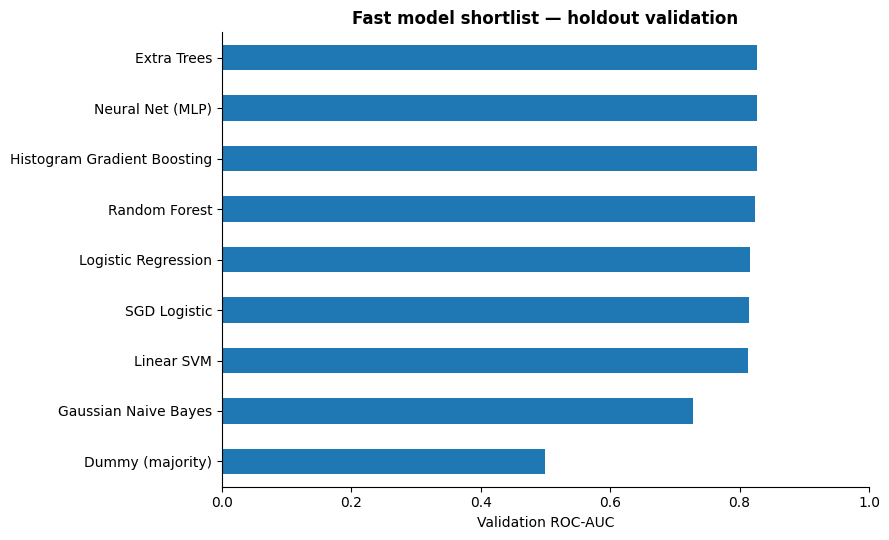

Top three by validation ROC-AUC:


,Model,ROC-AUC,PR-AUC,Precision,Recall,F1,Brier
6,Extra Trees,0.827,0.637,0.715,0.244,0.364,0.151
8,Neural Net (MLP),0.827,0.630,0.615,0.467,0.531,0.150
7,Histogram Gradient Boosting,0.827,0.634,0.645,0.423,0.511,0.150


Do not score the test split until the final tuned approach has been selected.


In [33]:
successful = scores[scores['Status'].eq('OK')].copy()
assert len(successful) >= 2, 'Too few models trained successfully; inspect error messages.'
ax = successful.sort_values('ROC-AUC').plot.barh(
    x='Model', y='ROC-AUC', legend=False, figsize=(9,5.5))
ax.set(xlabel='Validation ROC-AUC', ylabel='', title='Fast model shortlist — holdout validation')
ax.set_xlim(0,1)
plt.tight_layout()
plt.show()

shortlist = successful.head(3)[['Model','ROC-AUC','PR-AUC','Precision','Recall','F1','Brier']]
print('Top three by validation ROC-AUC:')
display(shortlist.round(3))
print('Do not score the test split until the final tuned approach has been selected.')

## 12.4 Interpretation and next steps

**What this experiment establishes:** which broad classifier families look promising under a consistent, intentionally cheap comparison. Some complex models may be disadvantaged by the smaller training set. The ranking is *provisional*.

**Next steps:** tune 2–3 shortlisted candidates with time-ordered CV, ensuring the **entire** feature engineering/preprocessing chain is re-fit per fold; then compare precision at high thresholds, PR-AUC, and probability calibration. Check robustness with `DROP_DEPOSIT_TYPE=True`, and assess the timing assumptions of historical fields. Only after those choices are locked should the final held-out test period be examined.

**Caution:** a booking-level classifier does not directly forecast how many rooms will be vacant on a given night. Linking this to Task 1 requires aggregation and a booking snapshot as of the forecast date.

In [34]:
# Optional lightweight export for GitHub / reports; disabled by default.
EXPORT_RESULTS = False
if EXPORT_RESULTS:
    output_dir = Path('../reports') if Path('../reports').exists() else Path('reports')
    output_dir.mkdir(exist_ok=True, parents=True)
    scores.to_csv(output_dir / 'model_shortlist_validation.csv', index=False)
    print('Wrote', output_dir / 'model_shortlist_validation.csv')

# 13 Model Cross-Validation

## 13.1 Environment and Setup

In [35]:
import sys
from pathlib import Path
import pandas as pd
import sklearn

# Define shared experiment settings
RANDOM_STATE = 67
N_SPLITS = 5
TARGET = "is_canceled"

# Locate the project and load the original data
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "raw" / "hotel_bookings.csv"
raw = pd.read_csv(DATA_PATH)

# Check the environment and data
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__, "| scikit-learn:", sklearn.__version__)
print("Data shape:", raw.shape)
print("Cancellation rate:", f"{raw[TARGET].mean():.1%}")
print("Random state:", RANDOM_STATE, "| CV folds:", N_SPLITS)
display(raw.head(5))

Python: 3.12.15
pandas: 2.3.3 | scikit-learn: 1.9.1
Data shape: (119390, 32)
Cancellation rate: 37.0%
Random state: 67 | CV folds: 5


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03



1. Follow our teammate's cleaning rules: remove exact duplicates, records with zero guests, and records with negative ADR.
2. Split the data by time: use earlier data for training and later data for validation and final testing.
3. Separate the inputs and labels: X_train_raw contains the booking information, and y_train indicates whether each booking was cancelled.

In [36]:
import calendar

RANDOM_STATE = 67
N_SPLITS = 5
MONTH_NUM = {name: i for i, name in enumerate(calendar.month_name) if name}

# Reproduce the existing cleaning rules
clean = raw.drop_duplicates().copy()
guest_count = clean["adults"] + clean["children"].fillna(0) + clean["babies"]
clean = clean.loc[(guest_count > 0) & ~(clean["adr"] < 0)].copy()

# Build arrival dates and sort chronologically
split_data = clean.copy()
split_data["_arrival_date"] = pd.to_datetime({
    "year": split_data["arrival_date_year"],
    "month": split_data["arrival_date_month"].map(MONTH_NUM),
    "day": split_data["arrival_date_day_of_month"]
})
split_data = split_data.sort_values("_arrival_date", kind="stable").reset_index(drop=True)

# Split using 70% / 15% / 15% of unique arrival dates
dates = split_data["_arrival_date"].drop_duplicates().to_numpy()
train_end = pd.Timestamp(dates[int(len(dates) * 0.70) - 1])
valid_end = pd.Timestamp(dates[int(len(dates) * 0.85) - 1])

train_df = split_data.loc[split_data["_arrival_date"] <= train_end].copy()
valid_df = split_data.loc[
    (split_data["_arrival_date"] > train_end) &
    (split_data["_arrival_date"] <= valid_end)
].copy()
test_df = split_data.loc[split_data["_arrival_date"] > valid_end].copy()

# Separate predictors and target
def make_xy(part):
    X = part.drop(columns=["is_canceled", "_arrival_date"]).reset_index(drop=True)
    y = part["is_canceled"].astype(int).reset_index(drop=True)
    return X, y

X_train_raw, y_train = make_xy(train_df)
X_valid_raw, y_valid = make_xy(valid_df)
X_test_raw, y_test = make_xy(test_df)

# Check partition sizes and date ranges
print("Rows after cleaning:", len(clean))
display(pd.DataFrame([
    {"Dataset": name, "Rows": len(part),
     "Start": part["_arrival_date"].min().date(),
     "End": part["_arrival_date"].max().date()}
    for name, part in [
        ("Train", train_df), ("Validation", valid_df), ("Test", test_df)
    ]
]))

Rows after cleaning: 87229


,Dataset,Rows,Start,End
0,Train,56132,2015-07-01,2017-01-05
1,Validation,14009,2017-01-06,2017-05-04
2,Test,17088,2017-05-05,2017-08-31


In [79]:
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import (
    roc_auc_score, precision_score, recall_score,
    f1_score, brier_score_loss
)

# Evaluate a pipeline using the shared chronological folds
def evaluate_model(model_name, model_pipeline):
    target = np.asarray(y_train, dtype=int)
    rows = []
    for fold, (train_idx, valid_idx) in enumerate(cv_splits, 1):
        fitted = clone(model_pipeline)
        fitted.fit(X_train_raw.iloc[train_idx], target[train_idx])
        X_fold, actual = X_train_raw.iloc[valid_idx], target[valid_idx]
        if hasattr(fitted, "predict_proba"):
            score = fitted.predict_proba(X_fold)[:, 1]
            predicted = (score >= 0.5).astype(int)
            brier = brier_score_loss(actual, score)
        else:
            score = fitted.decision_function(X_fold)
            predicted = fitted.predict(X_fold)
            brier = np.nan
        rows.append({
            "Fold": fold,
            "ROC_AUC": roc_auc_score(actual, score),
            "Precision": precision_score(actual, predicted, zero_division=0),
            "Recall": recall_score(actual, predicted, zero_division=0),
            "F1": f1_score(actual, predicted, zero_division=0),
            "Brier": brier
        })
        print(f"{model_name}: fold {fold}/{len(cv_splits)} completed")
    scores = pd.DataFrame(rows).set_index("Fold")
    summary = scores.agg(["mean", "std"]).T
    display(scores.round(4), summary.round(4))
    return scores, summary

## 13.2 Logistic Regression

### 13.2.1 N-Fold Cross-Validation

In [80]:
import numpy as np
from sklearn.model_selection import TimeSeriesSplit

# Create chronological splits using unique arrival dates
arrival_dates = train_df["_arrival_date"].reset_index(drop=True)
unique_train_dates = arrival_dates.drop_duplicates().sort_values().to_numpy()
date_cv = TimeSeriesSplit(n_splits=N_SPLITS)
cv_splits, fold_report = [], []

# Map date groups to row positions for model evaluation
for fold, (train_days, valid_days) in enumerate(
    date_cv.split(unique_train_dates), start=1
):
    train_idx = np.flatnonzero(arrival_dates.isin(unique_train_dates[train_days]))
    valid_idx = np.flatnonzero(arrival_dates.isin(unique_train_dates[valid_days]))
    cv_splits.append((train_idx, valid_idx))

    fold_report.append({
        "Fold": fold,
        "Train_rows": len(train_idx),
        "Valid_rows": len(valid_idx),
        "Train_start": arrival_dates.iloc[train_idx].min().date(),
        "Train_end": arrival_dates.iloc[train_idx].max().date(),
        "Valid_start": arrival_dates.iloc[valid_idx].min().date(),
        "Valid_end": arrival_dates.iloc[valid_idx].max().date()
    })

display(pd.DataFrame(fold_report))
print("Number of CV folds:", len(cv_splits))

,Fold,Train_rows,Valid_rows,Train_start,Train_end,Valid_start,Valid_end
0,1,7220,6258,2015-07-01,2015-10-03,2015-10-04,2016-01-03
1,2,13478,8702,2015-07-01,2016-01-03,2016-01-04,2016-04-04
2,3,22180,11241,2015-07-01,2016-04-04,2016-04-05,2016-07-05
3,4,33421,12155,2015-07-01,2016-07-05,2016-07-06,2016-10-05
4,5,45576,10556,2015-07-01,2016-10-05,2016-10-06,2017-01-05


Number of CV folds: 5


In [81]:
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, precision_score, recall_score,
                             f1_score, brier_score_loss)

RANDOM_STATE, N_SPLITS = 67, 5

# Create five chronological folds within the original training set
arrival_dates = train_df["_arrival_date"].reset_index(drop=True)
unique_dates = arrival_dates.drop_duplicates().sort_values().to_numpy()
cv_splits = []
for train_days, valid_days in TimeSeriesSplit(n_splits=N_SPLITS).split(unique_dates):
    train_idx = np.flatnonzero(arrival_dates.isin(unique_dates[train_days]))
    valid_idx = np.flatnonzero(arrival_dates.isin(unique_dates[valid_days]))
    cv_splits.append((train_idx, valid_idx))

# Combine the existing preparation rules with logistic regression
lr_pipeline = Pipeline([
    ("prepare", clone(prepare_pipeline)),
    ("model", LogisticRegression(max_iter=700, random_state=RANDOM_STATE))
])

# Fit a fresh preparation pipeline and model in every fold
lr_fold_results = []
for fold, (train_idx, valid_idx) in enumerate(cv_splits, start=1):
    fold_model = clone(lr_pipeline)
    fold_model.fit(X_train_raw.iloc[train_idx], y_train.iloc[train_idx])
    probability = fold_model.predict_proba(X_train_raw.iloc[valid_idx])[:, 1]
    prediction = (probability >= 0.5).astype(int)
    actual = y_train.iloc[valid_idx]

    lr_fold_results.append({
        "Fold": fold,
        "ROC_AUC": roc_auc_score(actual, probability),
        "Precision": precision_score(actual, prediction, zero_division=0),
        "Recall": recall_score(actual, prediction, zero_division=0),
        "F1": f1_score(actual, prediction, zero_division=0),
        "Brier": brier_score_loss(actual, probability)
    })
    print(f"Fold {fold}/{N_SPLITS} | ROC-AUC: {lr_fold_results[-1]['ROC_AUC']:.4f}")

# Summarize performance across the five folds
lr_cv_scores = pd.DataFrame(lr_fold_results)
lr_cv_summary = lr_cv_scores.drop(columns="Fold").agg(["mean", "std"]).T
lr_cv_summary.columns = ["Mean", "Std"]
display(lr_cv_scores.round(4))
display(lr_cv_summary.round(4))

Fold 1/5 | ROC-AUC: 0.9283
Fold 2/5 | ROC-AUC: 0.6889
Fold 3/5 | ROC-AUC: 0.8062
Fold 4/5 | ROC-AUC: 0.7586
Fold 5/5 | ROC-AUC: 0.8089


,Fold,ROC_AUC,Precision,Recall,F1,Brier
0,1,0.9283,0.8174,0.5547,0.6609,0.0661
1,2,0.6889,0.6547,0.1422,0.2337,0.1625
2,3,0.8062,0.5779,0.3441,0.4313,0.1561
3,4,0.7586,0.5888,0.1471,0.2354,0.1919
4,5,0.8089,0.6799,0.1830,0.2884,0.1646


,Mean,Std
ROC_AUC,0.7982,0.0875
Precision,0.6637,0.0961
Recall,0.2742,0.1771
F1,0.3699,0.1815
Brier,0.1482,0.0479


The mean ROC_AUC is 0.7982, which means the model has about an 80% chance of assigning a higher cancellation probability to a booking that actually cancels. This suggests it can rank cancellation risk reasonably well. Precision is fairly good at 0.66, so the positive predictions are fairly reliable, but recall is too low and many cancellations are missed. F1 is the harmonic mean of Precision and Recall, so the low recall brings F1 down. Brier = 0.1482 means the error in the predicted probabilities is relatively low.

The AUC is 0.9283 in the first fold but only 0.6889 in the second, showing that the model performs quite differently across validation periods.

### 13.2.2 Error Type Analysis

In [82]:
from sklearn.base import clone
from sklearn.metrics import confusion_matrix

# Fit an analysis model on the full training period
lr_analysis_model = clone(lr_pipeline)
lr_analysis_model.fit(X_train_raw, y_train)

# Save individual predictions on the separate validation set
lr_cases = X_valid_raw.reset_index(drop=True).copy()
lr_cases["Actual"] = np.asarray(y_valid, dtype=int)
lr_cases["Cancel_probability"] = lr_analysis_model.predict_proba(X_valid_raw)[:, 1]
lr_cases["Predicted"] = (lr_cases["Cancel_probability"] >= 0.5).astype(int)

# Count correct predictions, false alarms, and missed cancellations
error_table = pd.DataFrame(
    confusion_matrix(lr_cases["Actual"], lr_cases["Predicted"], labels=[0, 1]),
    index=["Actual: Not canceled", "Actual: Canceled"],
    columns=["Predicted: Not canceled", "Predicted: Canceled"]
)
display(error_table)

# Calculate error rates from the confusion matrix
tn, fp, fn, tp = error_table.to_numpy().ravel()
error_rates = pd.DataFrame({
    "Error_type": ["False positive (FP)", "False negative (FN)"],
    "Errors": [fp, fn],
    "Actual_group_size": [tn + fp, tp + fn],
    "Rate_pct": [100 * fp / (tn + fp), 100 * fn / (tp + fn)]
})
display(error_rates.style.format({"Rate_pct": "{:.2f}%"}))

,Predicted: Not canceled,Predicted: Canceled
Actual: Not canceled,9446,556
Actual: Canceled,2856,1151


,Error_type,Errors,Actual_group_size,Rate_pct
0,False positive (FP),556,10002,5.56%
1,False negative (FN),2856,4007,71.28%


The false positive rate is low at 5.56%, while the false negative rate is high at 71.28%

In [83]:
# Flag the two error types
lr_cases["FP"] = ((lr_cases["Actual"] == 0) & (lr_cases["Predicted"] == 1)).astype(int)
lr_cases["FN"] = ((lr_cases["Actual"] == 1) & (lr_cases["Predicted"] == 0)).astype(int)

# Compare error rates across booking groups
for feature in ["hotel", "market_segment"]:
    group_errors = lr_cases.groupby(feature, dropna=False).agg(
        Orders=("Actual", "size"), Canceled=("Actual", "sum"),
        FP=("FP", "sum"), FN=("FN", "sum")
    )
    non_canceled = group_errors["Orders"] - group_errors["Canceled"]
    group_errors["FP_rate_pct"] = 100 * group_errors["FP"] / non_canceled.replace(0, np.nan)
    group_errors["FN_rate_pct"] = 100 * group_errors["FN"] / group_errors["Canceled"].replace(0, np.nan)
    print(f"\nErrors by {feature}")
    display(group_errors.sort_values("FN_rate_pct", ascending=False).round(2))


Errors by hotel


,Orders,Canceled,FP,FN,FP_rate_pct,FN_rate_pct
hotel,,,,,,
Resort Hotel,5189,1109,67,962,1.64,86.74
City Hotel,8820,2898,489,1894,8.26,65.36



Errors by market_segment


,Orders,Canceled,FP,FN,FP_rate_pct,FN_rate_pct
market_segment,,,,,,
Complementary,99,15,1,14,1.19,93.33
Direct,2006,230,15,207,0.84,90.00
Corporate,732,75,2,64,0.30,85.33
Aviation,35,6,1,5,3.45,83.33
Offline TA/TO,1442,188,6,144,0.48,76.60
Online TA,8672,3233,523,2277,9.62,70.43
Groups,1023,260,8,145,1.05,55.77


Looking at hotel types and market segments separately, Resort Hotel has a very high false negative rate, and the FN rate is high across all market segments.

In [84]:
# Select confidently incorrect predictions
fn_cases = lr_cases[
    (lr_cases["Actual"] == 1) & (lr_cases["Predicted"] == 0)
].nsmallest(3, "Cancel_probability")
fp_cases = lr_cases[
    (lr_cases["Actual"] == 0) & (lr_cases["Predicted"] == 1)
].nlargest(3, "Cancel_probability")

# Display selected booking details
case_columns = ["hotel", "market_segment", "lead_time", "adr", "deposit_type",
                "is_repeated_guest", "previous_cancellations",
                "Actual", "Predicted", "Cancel_probability"]
for title, cases in [("False negative examples", fn_cases),
                     ("False positive examples", fp_cases)]:
    view = cases[case_columns].copy()
    view["Cancel_probability"] = view["Cancel_probability"].map("{:.2%}".format)
    print(f"\n{title}")
    display(view.T)


False negative examples


,2356,3428,4326
hotel,City Hotel,Resort Hotel,Resort Hotel
market_segment,Aviation,Online TA,Direct
lead_time,1,0,0
adr,0.0,0.0,80.0
deposit_type,No Deposit,No Deposit,No Deposit
is_repeated_guest,1,0,0
previous_cancellations,0,0,0
Actual,1,1,1
Predicted,0,0,0
Cancel_probability,0.05%,0.23%,0.25%



False positive examples


,3094,6388,11082
hotel,City Hotel,City Hotel,Resort Hotel
market_segment,Direct,Offline TA/TO,Direct
lead_time,2,4,32
adr,79.0,90.0,204.33
deposit_type,No Deposit,No Deposit,No Deposit
is_repeated_guest,1,1,1
previous_cancellations,1,1,2
Actual,0,0,0
Predicted,1,1,1
Cancel_probability,96.85%,92.43%,88.82%


Among the false negatives, the extreme cases were booked close to arrival and had no previous cancellations. Even though they looked low-risk, they could still cancel.

Among the false positives, the bookings were made well in advance and had previous cancellations. The model assigned them a high cancellation probability, but they did not cancel. It seems the model may overestimate the risk for customers with a cancellation history.

### 13.2.3 Permutation Importance

In [85]:
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline

# Reuse the fitted feature engineering, preprocessing, and model
fitted_prepare = lr_analysis_model.named_steps["prepare"]
X_valid_features = fitted_prepare[0].transform(X_valid_raw)
lr_feature_model = Pipeline([
    ("preprocessing", fitted_prepare[1]),
    ("model", lr_analysis_model.named_steps["model"])
])

# Measure the AUC decrease after shuffling each feature
lr_pi = permutation_importance(
    lr_feature_model, X_valid_features, y_valid,
    scoring="roc_auc", n_repeats=5, random_state=67, n_jobs=1
)
lr_importance = pd.DataFrame({
    "Feature": X_valid_features.columns,
    "AUC_drop": lr_pi.importances_mean,
    "Shuffle_SD": lr_pi.importances_std
}).sort_values("AUC_drop", ascending=False).reset_index(drop=True)
display(lr_importance.head(10).round(4))

,Feature,AUC_drop,Shuffle_SD
0,agent,0.1116,0.0027
1,lead_time_log,0.0818,0.0026
2,is_domestic,0.0405,0.0017
3,has_history,0.0206,0.0009
4,country,0.0204,0.0015
5,history_count,0.0199,0.0013
6,customer_type,0.0197,0.0018
7,lead_time_bucket,0.0107,0.0009
8,deposit_type,0.0077,0.0004
9,previous_bookings_not_canceled,0.0062,0.0006


**AUC_drop:** The average drop in AUC after shuffling this variable.

**Shuffle_SD:** How much the importance values vary when shuffling is repeated 5 times.

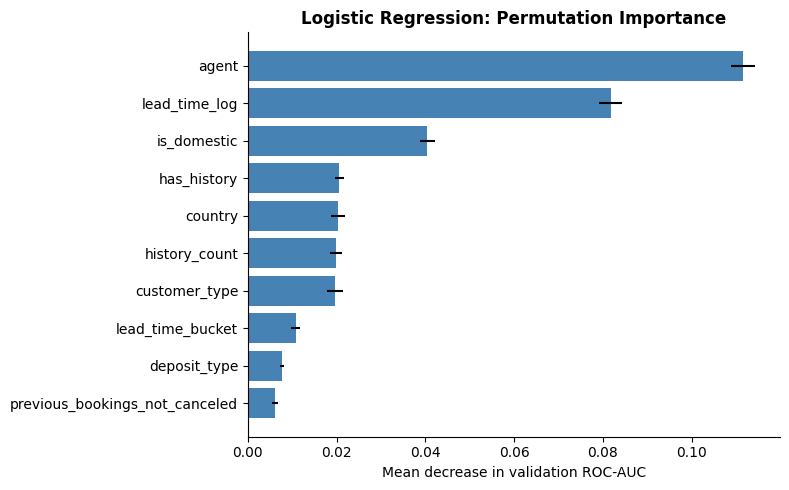

In [86]:
import matplotlib.pyplot as plt

# Plot the ten most important features
lr_top10 = lr_importance.head(10).sort_values("AUC_drop")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(lr_top10["Feature"], lr_top10["AUC_drop"],
        xerr=lr_top10["Shuffle_SD"], color="steelblue")
ax.set_xlabel("Mean decrease in validation ROC-AUC")
ax.set_title("Logistic Regression: Permutation Importance")
ax.axvline(0, color="gray", linewidth=0.8)
plt.tight_layout()
plt.show()

A larger drop in ROC-AUC after shuffling means the model relies more on that variable. The current LR model relies most on agent, lead_time_log and is_domestic.

Agency information is the most helpful.
Shuffling agent reduces AUC by about 0.112 on average, which shows that LR relies heavily on differences between agencies to distinguish cancellation risk.

Booking lead time is also important.
Both lead_time_log and lead_time_bucket are in the top 10, showing that the model uses information about how far in advance customers book.

Where customers come from and their booking history also help with prediction.
is_domestic, country and several booking history variables are all in the top 10.

### 13.2.4 A Feature Selection Experiment

is_domestic only distinguishes between Portugal and other countries, so we choose to remove it.

In [87]:
from sklearn.base import clone

# Create a separate model version and exclude the domestic indicator
lr_v1_pipeline = clone(lr_pipeline)
preprocessor_v1 = lr_v1_pipeline.named_steps["prepare"][1]
preprocessor_v1.set_params(transformers=[
    (name, transformer, [col for col in columns if col != "is_domestic"])
    for name, transformer, columns in preprocessor_v1.transformers
])
print("V1: exclude is_domestic; retain country.")

from sklearn.metrics import (roc_auc_score, precision_score, recall_score,
                             f1_score, brier_score_loss)

# Evaluate V1 on the same chronological folds
v1_rows = []
for fold, (train_idx, valid_idx) in enumerate(cv_splits, 1):
    v1_model = clone(lr_v1_pipeline)
    v1_model.fit(X_train_raw.iloc[train_idx], y_train.iloc[train_idx])
    actual = y_train.iloc[valid_idx]
    probability = v1_model.predict_proba(X_train_raw.iloc[valid_idx])[:, 1]
    prediction = (probability >= 0.5).astype(int)
    v1_rows.append({
        "Fold": fold, "ROC_AUC": roc_auc_score(actual, probability),
        "Precision": precision_score(actual, prediction, zero_division=0),
        "Recall": recall_score(actual, prediction, zero_division=0),
        "F1": f1_score(actual, prediction, zero_division=0),
        "Brier": brier_score_loss(actual, probability)
    })

# Compare baseline and feature-selection results
lr_v1_cv_scores = pd.DataFrame(v1_rows).set_index("Fold")
metric_cols = ["ROC_AUC", "Precision", "Recall", "F1", "Brier"]
lr_version_comparison = pd.concat({
    "V0_Baseline": lr_cv_scores[metric_cols].agg(["mean", "std"]).T,
    "V1_NoDomestic": lr_v1_cv_scores[metric_cols].agg(["mean", "std"]).T
}, axis=1)
display(lr_version_comparison.round(4))

V1: exclude is_domestic; retain country.


V0_Baseline         V1_NoDomestic        
                 mean     std          mean     std
ROC_AUC        0.7982  0.0875        0.7984  0.0871
Precision      0.6637  0.0961        0.6636  0.0999
Recall         0.2742  0.1771        0.2734  0.1771
F1             0.3699  0.1815        0.3693  0.1830
Brier          0.1482  0.0479        0.1482  0.0479

After removing it, LR's overall performance changes little. We then generate V1's predictions and confusion matrix and compare the errors from V0 and V1 side by side.

In [88]:
from sklearn.base import clone
from sklearn.metrics import confusion_matrix

# Fit V1 and save validation predictions
lr_v1_analysis_model = clone(lr_v1_pipeline)
lr_v1_analysis_model.fit(X_train_raw, y_train)
lr_v1_cases = X_valid_raw.reset_index(drop=True).copy()
lr_v1_cases["Actual"] = np.asarray(y_valid, dtype=int)
lr_v1_cases["Cancel_probability"] = lr_v1_analysis_model.predict_proba(X_valid_raw)[:, 1]
lr_v1_cases["Predicted"] = (lr_v1_cases["Cancel_probability"] >= 0.5).astype(int)

# Display the V1 confusion matrix
v1_cm = confusion_matrix(lr_v1_cases["Actual"], lr_v1_cases["Predicted"], labels=[0, 1])
v1_error_table = pd.DataFrame(v1_cm, index=error_table.index, columns=error_table.columns)
display(v1_error_table)

# Compare error counts and rates on the same validation set
comparison_rows = []
for version, matrix in [("V0_Baseline", error_table.to_numpy()),
                        ("V1_NoDomestic", v1_cm)]:
    tn, fp, fn, tp = matrix.ravel()
    comparison_rows.append({
        "Version": version, "FP": fp, "FN": fn,
        "FP_rate_pct": 100 * fp / (tn + fp),
        "FN_rate_pct": 100 * fn / (tp + fn)
    })
lr_error_comparison = pd.DataFrame(comparison_rows).set_index("Version")
display(lr_error_comparison.style.format({
    "FP_rate_pct": "{:.2f}%", "FN_rate_pct": "{:.2f}%"
}))

,Predicted: Not canceled,Predicted: Canceled
Actual: Not canceled,9458,544
Actual: Canceled,2859,1148


,FP,FN,FP_rate_pct,FN_rate_pct
Version,,,,
V0_Baseline,556,2856,5.56%,71.28%
V1_NoDomestic,544,2859,5.44%,71.35%


,V0_AUC_drop,V1_AUC_drop
Feature,,
agent,0.1116,0.1106
lead_time_log,0.0818,0.0821
country,0.0204,0.0713
has_history,0.0206,0.0201
customer_type,0.0197,0.0195
history_count,0.0199,0.0195
lead_time_bucket,0.0107,0.0108
deposit_type,0.0077,0.0077
previous_bookings_not_canceled,0.0062,0.0059


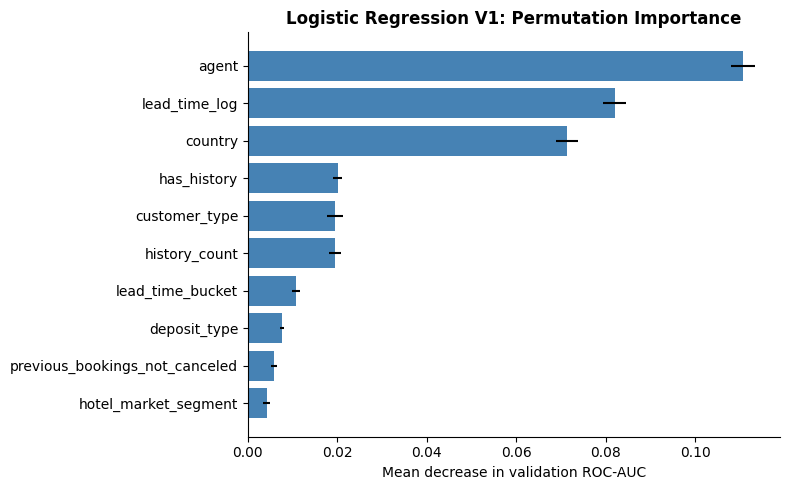

In [89]:
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline

# Reuse the fitted V1 components and inspect its retained features
fitted_prepare_v1 = lr_v1_analysis_model.named_steps["prepare"]
X_valid_features_v1 = fitted_prepare_v1[0].transform(X_valid_raw).drop(columns=["is_domestic"])
lr_v1_feature_model = Pipeline([
    ("preprocessing", fitted_prepare_v1[1]),
    ("model", lr_v1_analysis_model.named_steps["model"])
])

# Calculate permutation importance on the same validation set
lr_v1_pi = permutation_importance(
    lr_v1_feature_model, X_valid_features_v1, y_valid,
    scoring="roc_auc", n_repeats=5, random_state=67, n_jobs=1
)
lr_v1_importance = pd.DataFrame({
    "Feature": X_valid_features_v1.columns,
    "AUC_drop": lr_v1_pi.importances_mean,
    "Shuffle_SD": lr_v1_pi.importances_std
}).sort_values("AUC_drop", ascending=False).reset_index(drop=True)

# Compare importance values by feature name
lr_importance_comparison = pd.concat({
    "V0_AUC_drop": lr_importance.set_index("Feature")["AUC_drop"],
    "V1_AUC_drop": lr_v1_importance.set_index("Feature")["AUC_drop"]
}, axis=1).sort_values("V1_AUC_drop", ascending=False)
display(lr_importance_comparison.head(10).round(4))

import matplotlib.pyplot as plt

# Plot the ten most important V1 features
lr_v1_top10 = lr_v1_importance.head(10).sort_values("AUC_drop")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(lr_v1_top10["Feature"], lr_v1_top10["AUC_drop"],
        xerr=lr_v1_top10["Shuffle_SD"], color="steelblue")
ax.set_xlabel("Mean decrease in validation ROC-AUC")
ax.set_title("Logistic Regression V1: Permutation Importance")
plt.tight_layout()
plt.show()

There is little difference between V0 and V1. Country's AUC_Drop rises from 0.02 to 0.07, more than tripling

Recorded summaries used for: None


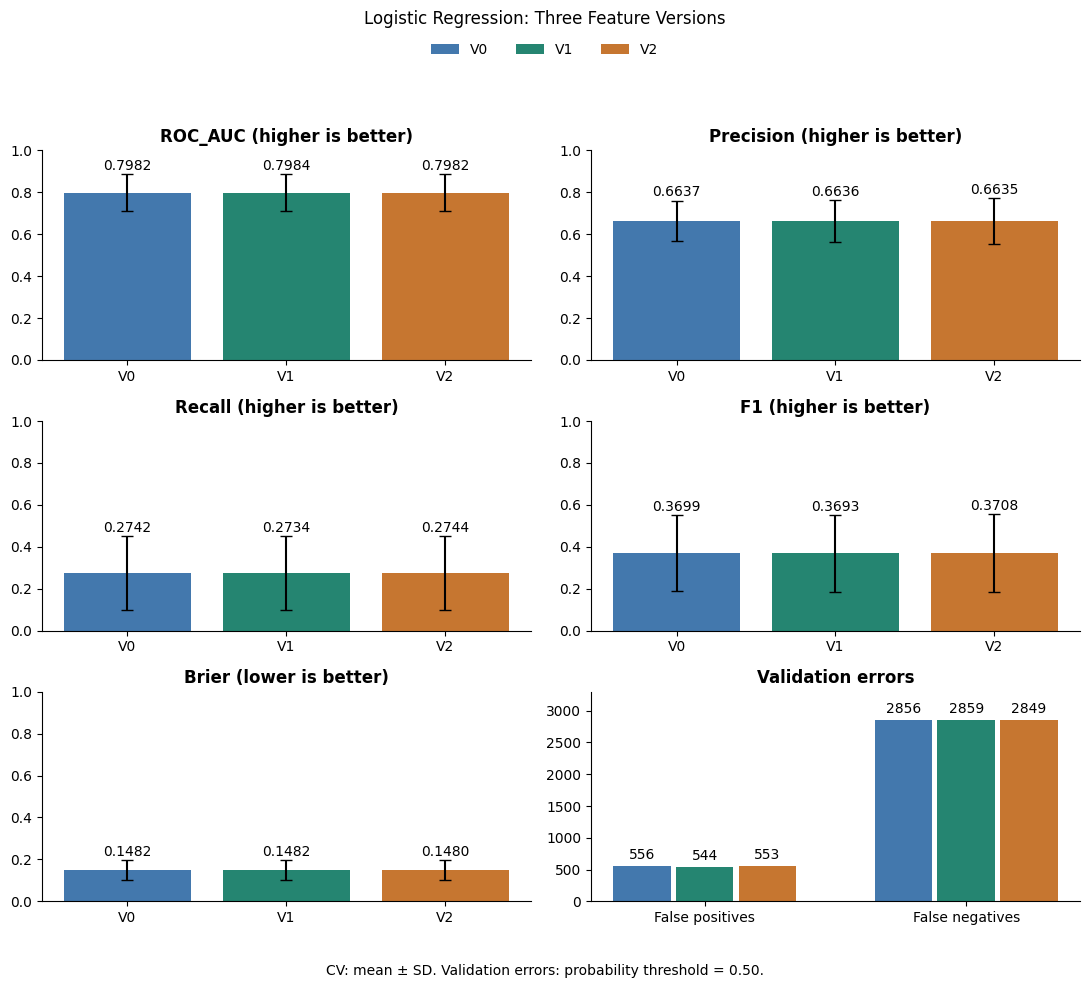

In [90]:
import pandas as pd
import matplotlib.pyplot as plt

plt.close("all")

# Prepare plotting data from live results or recorded screenshot summaries
metrics = ["ROC_AUC", "Precision", "Recall", "F1", "Brier"]
versions = ["V0_Baseline", "V1_NoDomestic", "V2_StayValue"]
score_names = ["lr_cv_scores", "lr_v1_cv_scores", "lr_v2_cv_scores"]

recorded_means = [
    [0.7982, 0.6637, 0.2742, 0.3699, 0.1482],
    [0.7984, 0.6636, 0.2734, 0.3693, 0.1482],
    [0.7982, 0.6635, 0.2744, 0.3708, 0.1480]
]
recorded_stds = [
    [0.0875, 0.0961, 0.1771, 0.1815, 0.0479],
    [0.0871, 0.0999, 0.1771, 0.1830, 0.0479],
    [0.0882, 0.1094, 0.1770, 0.1849, 0.0483]
]

version_summaries = {}
restored_versions = []
for i, version in enumerate(versions):
    scores = globals().get(score_names[i])
    if isinstance(scores, pd.DataFrame) and set(metrics).issubset(scores.columns):
        version_summaries[version] = scores[metrics].agg(["mean", "std"]).T
    else:
        version_summaries[version] = pd.DataFrame({
            "mean": recorded_means[i], "std": recorded_stds[i]
        }, index=metrics)
        restored_versions.append(version)

lr_three_versions = pd.concat(version_summaries, axis=1)

# Restore validation error counts if the comparison table is missing
if "lr_all_error_comparison" not in globals():
    lr_all_error_comparison = pd.DataFrame({
        "FP": [556, 544, 553], "FN": [2856, 2859, 2849]
    }, index=versions)

print("Recorded summaries used for:", ", ".join(restored_versions) or "None")

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Read the existing evaluation results
versions = ["V0_Baseline", "V1_NoDomestic", "V2_StayValue"]
labels = ["V0", "V1", "V2"]
colors = ["#4378ad", "#258571", "#c67630"]
metrics = ["ROC_AUC", "Precision", "Recall", "F1", "Brier"]
fig, axes = plt.subplots(3, 2, figsize=(11, 10))

# Plot five-fold means and standard deviations
for ax, metric in zip(axes.flat, metrics):
    means = [lr_three_versions.loc[metric, (v, "mean")] for v in versions]
    stds = [lr_three_versions.loc[metric, (v, "std")] for v in versions]
    ax.bar(labels, means, yerr=stds, color=colors, capsize=4)
    for i, (mean, sd) in enumerate(zip(means, stds)):
        ax.text(i, mean + sd + 0.02, f"{mean:.4f}", ha="center")
    ax.set_title(metric + (" (lower is better)" if metric == "Brier"
                           else " (higher is better)"))
    ax.set_ylim(0, 1)

# Plot validation errors separately
ax = axes.flat[5]
for j, version in enumerate(versions):
    bars = ax.bar(np.arange(2) + (j - 1) * 0.24,
                  lr_all_error_comparison.loc[version, ["FP", "FN"]],
                  width=0.22, color=colors[j])
    ax.bar_label(bars, padding=3)
ax.set_xticks([0, 1], ["False positives", "False negatives"])
ax.set_title("Validation errors")
ax.set_ylim(0, 3300)

fig.suptitle("Logistic Regression: Three Feature Versions")
fig.legend([Patch(facecolor=c) for c in colors], labels,
           loc="upper center", bbox_to_anchor=(0.5, 0.96),
           ncol=3, frameon=False)
plt.tight_layout(rect=[0, 0.05, 1, 0.91])
fig.text(0.5, 0.015,
         "CV: mean ± SD. Validation errors: probability threshold = 0.50.",
         ha="center")
plt.show()

The mean five-fold ROC-AUC is around 0.798 for all three versions, so their overall performance is similar. V1 keeps roughly the same predictive performance after removing the redundant variable. At the same time, the importance of country rises from 0.0204 to 0.0713, showing that the model uses country information more.

V2 shows small improvements in Recall, F1 and Brier, but the gains are limited. On the fixed validation set, V2 has 10 fewer false negatives and 9 more false positives than V1, so the total number of errors falls by only 1. The new variable has a permutation importance of just 0.00034, suggesting it adds little to the current LR model. If simplicity is the priority, we can keep V1 as the LR candidate for now.

All three versions achieved a mean five-fold ROC-AUC of approximately 0.798, with similar overall performance. V1 maintained predictive performance after removing the redundant domestic indicator. The importance of country increased from 0.0204 to 0.0713, indicating greater model reliance on country information.

V2 slightly improved recall, F1 and Brier score, but the gains were limited. On the separate validation set, it produced 10 fewer false negatives and 9 more false positives than V1—only one fewer error overall. The new feature’s permutation importance was 0.00034, suggesting little additional value for this LR model. V1 is therefore a reasonable provisional choice when simplicity is preferred.

## 13.2.5 Another Round of Feature Engineering

New variable: text_estimated_stay_value= adr * total_nights

In [91]:
from sklearn.base import clone

# Extend the existing feature engineering with one interaction
class BookingFeatureEngineerV2(BookingFeatureEngineer):
    def transform(self, X):
        d = super().transform(X)
        d["estimated_stay_value"] = d["adr"] * d["total_nights"]
        return d

# Build V2 from V1 and include the new numeric feature
lr_v2_pipeline = clone(lr_v1_pipeline)
prepare_v2 = lr_v2_pipeline.named_steps["prepare"]
prepare_v2.set_params(feature_engineering=BookingFeatureEngineerV2(
    drop_deposit_type=prepare_v2[0].drop_deposit_type
))
preprocessor_v2 = prepare_v2[1]
preprocessor_v2.set_params(transformers=[
    (name, transformer, list(columns) + ["estimated_stay_value"]
     if name == "capped_num" else columns)
    for name, transformer, columns in preprocessor_v2.transformers
])

# Inspect the new feature
preview_v2 = prepare_v2[0].transform(X_train_raw)
display(preview_v2[["adr", "total_nights", "estimated_stay_value"]].head())

# Evaluate V2 using the existing chronological folds
v2_rows = []
for fold, (train_idx, valid_idx) in enumerate(cv_splits, 1):
    v2_model = clone(lr_v2_pipeline)
    v2_model.fit(X_train_raw.iloc[train_idx], y_train.iloc[train_idx])
    actual = y_train.iloc[valid_idx]
    probability = v2_model.predict_proba(X_train_raw.iloc[valid_idx])[:, 1]
    prediction = (probability >= 0.5).astype(int)
    v2_rows.append({
        "Fold": fold, "ROC_AUC": roc_auc_score(actual, probability),
        "Precision": precision_score(actual, prediction, zero_division=0),
        "Recall": recall_score(actual, prediction, zero_division=0),
        "F1": f1_score(actual, prediction, zero_division=0),
        "Brier": brier_score_loss(actual, probability)
    })

# Compare all three versions
lr_v2_cv_scores = pd.DataFrame(v2_rows).set_index("Fold")
metric_cols = ["ROC_AUC", "Precision", "Recall", "F1", "Brier"]
lr_three_versions = pd.concat({
    "V0_Baseline": lr_cv_scores[metric_cols].agg(["mean", "std"]).T,
    "V1_NoDomestic": lr_v1_cv_scores[metric_cols].agg(["mean", "std"]).T,
    "V2_StayValue": lr_v2_cv_scores[metric_cols].agg(["mean", "std"]).T
}, axis=1)
display(lr_three_versions.round(4))

,adr,total_nights,estimated_stay_value
0,0.0,0,0.0
1,0.0,0,0.0
2,75.0,1,75.0
3,75.0,1,75.0
4,98.0,2,196.0


V0_Baseline         V1_NoDomestic         V2_StayValue        
                 mean     std          mean     std         mean     std
ROC_AUC        0.7982  0.0875        0.7984  0.0871       0.7982  0.0882
Precision      0.6637  0.0961        0.6636  0.0999       0.6635  0.1094
Recall         0.2742  0.1771        0.2734  0.1771       0.2744  0.1770
F1             0.3699  0.1815        0.3693  0.1830       0.3708  0.1849
Brier          0.1482  0.0479        0.1482  0.0479       0.1480  0.0483

V0 is the original baseline model. V1 removes the redundant is_domestic variable, with little change in performance. V2 adds an interaction feature, and again there is little change.

## 13.2.6 V2 Error Analysis and Feature Importance Plot

,FP,FN,FP_rate_pct,FN_rate_pct
Version,,,,
V0_Baseline,556,2856,5.56%,71.28%
V1_NoDomestic,544,2859,5.44%,71.35%
V2_StayValue,553,2849,5.53%,71.10%


,Feature,AUC_drop,Shuffle_SD
27,estimated_stay_value,0.00034,0.00041


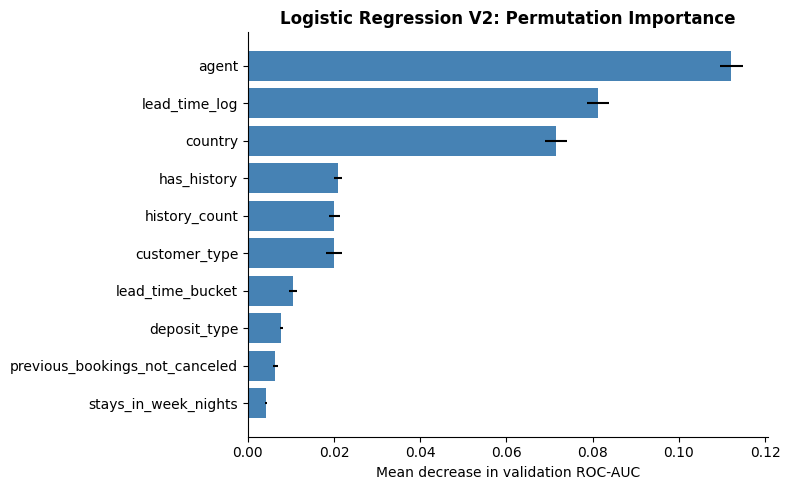

In [92]:
# Fit V2 and save predictions on the original validation set
lr_v2_analysis_model = clone(lr_v2_pipeline)
lr_v2_analysis_model.fit(X_train_raw, y_train)
lr_v2_cases = X_valid_raw.reset_index(drop=True).copy()
lr_v2_cases["Actual"] = np.asarray(y_valid, dtype=int)
lr_v2_cases["Cancel_probability"] = lr_v2_analysis_model.predict_proba(X_valid_raw)[:, 1]
lr_v2_cases["Predicted"] = (lr_v2_cases["Cancel_probability"] >= 0.5).astype(int)
v2_cm = confusion_matrix(lr_v2_cases["Actual"], lr_v2_cases["Predicted"], labels=[0, 1])

# Compare error counts and rates across all three versions
error_rows = []
for version, matrix in [("V0_Baseline", error_table.to_numpy()),
                        ("V1_NoDomestic", v1_cm), ("V2_StayValue", v2_cm)]:
    tn, fp, fn, tp = matrix.ravel()
    error_rows.append({
        "Version": version, "FP": fp, "FN": fn,
        "FP_rate_pct": 100 * fp / (tn + fp),
        "FN_rate_pct": 100 * fn / (tp + fn)
    })
lr_all_error_comparison = pd.DataFrame(error_rows).set_index("Version")
display(lr_all_error_comparison.style.format({
    "FP_rate_pct": "{:.2f}%", "FN_rate_pct": "{:.2f}%"
}))

# Inspect the retained V2 features using the fitted components
fitted_prepare_v2 = lr_v2_analysis_model.named_steps["prepare"]
X_valid_features_v2 = fitted_prepare_v2[0].transform(X_valid_raw).drop(columns=["is_domestic"])
lr_v2_feature_model = Pipeline([
    ("preprocessing", fitted_prepare_v2[1]),
    ("model", lr_v2_analysis_model.named_steps["model"])
])
lr_v2_pi = permutation_importance(
    lr_v2_feature_model, X_valid_features_v2, y_valid,
    scoring="roc_auc", n_repeats=5, random_state=67, n_jobs=1
)
lr_v2_importance = pd.DataFrame({
    "Feature": X_valid_features_v2.columns,
    "AUC_drop": lr_v2_pi.importances_mean,
    "Shuffle_SD": lr_v2_pi.importances_std
}).sort_values("AUC_drop", ascending=False).reset_index(drop=True)

# Display the new feature's importance even if it is outside the top ten
display(lr_v2_importance.loc[
    lr_v2_importance["Feature"].eq("estimated_stay_value")
].round(5))

# Plot the ten most important features
lr_v2_top10 = lr_v2_importance.head(10).sort_values("AUC_drop")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(lr_v2_top10["Feature"], lr_v2_top10["AUC_drop"],
        xerr=lr_v2_top10["Shuffle_SD"], color="steelblue")
ax.set_xlabel("Mean decrease in validation ROC-AUC")
ax.set_title("Logistic Regression V2: Permutation Importance")
plt.tight_layout()
plt.show()

## 13.3 SGD Logistic

## 13.3 continued — Four models: V0, V1 and V2

The original cells above are unchanged, including the unfinished SGD cell that refers to an undefined `evaluate_model`. If Run All stops there, select the setup cell below and use Run > Run All Below.

These four models follow the LR experiment: V0 keeps the existing features; V1 removes `is_domestic` while retaining `country`; V2 starts from V1 and adds `estimated_stay_value = adr * total_nights`. The country field already identifies guests from Portugal, so V1 tests whether removing a redundant indicator preserves performance. V2 tests whether combining nightly rate and stay length adds useful information beyond the two separate inputs. This is an estimated booking-value feature, not actual hotel revenue.

Each version uses the same five chronological folds, with preprocessing refitted in each fold. Error analysis and permutation importance use the separate validation set, as in the LR example. The test set is not evaluated. Default thresholds are used: 0.5 for probabilities and 0 for Linear SVM decision scores. SVM scores are not probabilities, so its Brier is blank. These experiments do not establish performance at 30/14/7/1-day forecast horizons.

### Shared setup for these four models

In [93]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.linear_model import SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, precision_score, recall_score,
                             f1_score, brier_score_loss, confusion_matrix)
from sklearn.exceptions import ConvergenceWarning
import warnings

warnings.filterwarnings("default", category=ConvergenceWarning)
MEMBER_SEED = 67
MEMBER_METRICS = ["ROC_AUC", "Precision", "Recall", "F1", "Brier"]

# Reuse the three preparation versions already defined in the LR section.
member_preparations = {
    "V0": clone(lr_pipeline.named_steps["prepare"]),
    "V1": clone(lr_v1_pipeline.named_steps["prepare"]),
    "V2": clone(lr_v2_pipeline.named_steps["prepare"])
}
member_models = {}
member_results = {}

def member_dense(matrix):
    return matrix.toarray() if sparse.issparse(matrix) else np.asarray(matrix)

def member_pipeline(classifier, version, needs_dense=False):
    steps = [("prepare", clone(member_preparations[version]))]
    if needs_dense:
        steps.append(("dense", FunctionTransformer(member_dense, accept_sparse=True)))
    steps.append(("model", clone(classifier)))
    return Pipeline(steps)

def member_scores(fitted, X, actual):
    prediction = fitted.predict(X)
    if hasattr(fitted, "predict_proba"):
        score = fitted.predict_proba(X)[:, 1]
        brier = brier_score_loss(actual, score)
    else:
        score = fitted.decision_function(X)
        brier = np.nan
    return prediction, score, {
        "ROC_AUC": roc_auc_score(actual, score),
        "Precision": precision_score(actual, prediction, zero_division=0),
        "Recall": recall_score(actual, prediction, zero_division=0),
        "F1": f1_score(actual, prediction, zero_division=0),
        "Brier": brier
    }

def member_cv(name, version):
    classifier, needs_dense = member_models[name]
    pipeline = member_pipeline(classifier, version, needs_dense)
    rows = []
    for fold, (train_idx, valid_idx) in enumerate(cv_splits, 1):
        fitted = clone(pipeline)
        fitted.fit(X_train_raw.iloc[train_idx], y_train.iloc[train_idx])
        _, _, scores = member_scores(
            fitted, X_train_raw.iloc[valid_idx], y_train.iloc[valid_idx]
        )
        rows.append({"Fold": fold, **scores})
        print(f"{name} {version} | Fold {fold}/5 | ROC-AUC: {scores['ROC_AUC']:.4f}")
    fold_scores = pd.DataFrame(rows).set_index("Fold")
    summary = fold_scores.agg(["mean", "std"]).T
    summary.columns = ["Mean", "Std"]
    member_results[(name, version)] = {
        "pipeline": pipeline, "cv_scores": fold_scores, "cv_summary": summary
    }
    display(fold_scores.round(4))
    display(summary.round(4))
    return fold_scores, summary

def member_analysis(name, version):
    result = member_results[(name, version)]
    fitted = clone(result["pipeline"]).fit(X_train_raw, y_train)
    prediction, score, metrics = member_scores(fitted, X_valid_raw, y_valid)
    cases = X_valid_raw.reset_index(drop=True).copy()
    cases["Actual"] = np.asarray(y_valid, dtype=int)
    cases["Predicted"] = prediction
    cases["Risk_score"] = score
    cases["FP"] = ((cases.Actual == 0) & (cases.Predicted == 1)).astype(int)
    cases["FN"] = ((cases.Actual == 1) & (cases.Predicted == 0)).astype(int)
    matrix = confusion_matrix(cases.Actual, cases.Predicted, labels=[0, 1])
    tn, fp, fn, tp = matrix.ravel()
    result.update({"analysis_model": fitted, "cases": cases,
                   "validation_metrics": metrics, "confusion_matrix": matrix})
    result["errors"] = {
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "FP_rate_pct": 100 * fp / (tn + fp),
        "FN_rate_pct": 100 * fn / (tp + fn)
    }
    print(f"{name} {version}: separate-validation confusion matrix")
    display(pd.DataFrame(matrix,
        index=["Actual: Not canceled", "Actual: Canceled"],
        columns=["Predicted: Not canceled", "Predicted: Canceled"]))
    display(pd.DataFrame([result["errors"]], index=[version]).round(2))

    # Check whether false alarms and missed cancellations concentrate in specific groups.
    for feature in ["hotel", "market_segment"]:
        groups = cases.groupby(feature, dropna=False).agg(
            Orders=("Actual", "size"), Canceled=("Actual", "sum"),
            FP=("FP", "sum"), FN=("FN", "sum")
        )
        groups["FP_rate_pct"] = 100 * groups.FP / (groups.Orders - groups.Canceled).replace(0, np.nan)
        groups["FN_rate_pct"] = 100 * groups.FN / groups.Canceled.replace(0, np.nan)
        print(f"Errors by {feature}")
        display(groups.sort_values("FN_rate_pct", ascending=False).round(2))

    # Show examples for interpreting mistakes; SVM risk scores are not probabilities.
    columns = ["hotel", "market_segment", "lead_time", "adr", "deposit_type",
               "is_repeated_guest", "previous_cancellations",
               "Actual", "Predicted", "Risk_score"]
    for title, example in [
        ("False negative examples", cases[cases.FN == 1].nsmallest(3, "Risk_score")),
        ("False positive examples", cases[cases.FP == 1].nlargest(3, "Risk_score"))
    ]:
        print(title)
        display(example[columns].round({"Risk_score": 4}).T)

    # Shuffle engineered features before preprocessing, matching the LR approach.
    prepare = fitted.named_steps["prepare"]
    features = prepare[0].transform(X_valid_raw)
    retained = [column for _, _, columns in prepare[1].transformers for column in columns]
    features = features[retained]
    feature_steps = [("preprocessing", prepare[1])]
    if "dense" in fitted.named_steps:
        feature_steps.append(("dense", fitted.named_steps["dense"]))
    feature_steps.append(("model", fitted.named_steps["model"]))
    feature_model = Pipeline(feature_steps)
    pi = permutation_importance(feature_model, features, y_valid, scoring="roc_auc",
                                n_repeats=5, random_state=MEMBER_SEED, n_jobs=1)
    importance = pd.DataFrame({
        "Feature": features.columns,
        "AUC_drop": pi.importances_mean,
        "Shuffle_SD": pi.importances_std
    }).sort_values("AUC_drop", ascending=False).reset_index(drop=True)
    result["importance"] = importance
    print("Top ten permutation importances on the separate validation set")
    display(importance.head(10).round(4))
    if version == "V2":
        print("New feature importance")
        display(importance[importance.Feature.eq("estimated_stay_value")].round(5))
    return result

def member_compare(name):
    comparison = pd.concat({
        version: member_results[(name, version)]["cv_summary"]
        for version in ["V0", "V1", "V2"]
    }, axis=1)
    errors = pd.DataFrame({
        version: member_results[(name, version)]["errors"]
        for version in ["V0", "V1", "V2"]
    }).T
    errors.index.name = "Version"
    print("Five-fold mean and standard deviation")
    display(comparison.round(4))
    print("Separate-validation error comparison")
    display(errors.round(2))
    importance = pd.concat({
        version: member_results[(name, version)]["importance"].set_index("Feature")["AUC_drop"]
        for version in ["V0", "V1", "V2"]
    }, axis=1)
    print("Permutation-importance comparison (top ten in V2)")
    display(importance.sort_values("V2", ascending=False).head(10).round(4))
    return comparison, errors


In [94]:
# Simple comparison and importance plots, using the computed results above.
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

def plot_member_results(name):
    versions = ["V0", "V1", "V2"]
    colors = ["#4378ad", "#258571", "#c67630"]
    labels = ["V0: baseline", "V1: remove domestic", "V2: add stay value"]
    data = [member_results[(name, version)] for version in versions]
    n_valid = int(sum(data[0]["errors"][key] for key in ["TN", "FP", "FN", "TP"]))

    # Match the LR comparison: CV mean/SD and separate-validation error counts.
    fig, axes = plt.subplots(3, 2, figsize=(10, 9))
    for ax, metric in zip(axes.flat, ["ROC_AUC", "Precision", "Recall", "F1", "Brier"]):
        means = np.array([item["cv_summary"].loc[metric, "Mean"] for item in data])
        sds = np.array([item["cv_summary"].loc[metric, "Std"] for item in data])
        if not np.isfinite(means).any():
            ax.text(.5, .5, "Brier not calculated\nSVM scores are not probabilities",
                    ha="center", va="center", transform=ax.transAxes)
            ax.set_title("Brier")
            ax.set_axis_off()
            continue
        ax.bar(versions, means, yerr=sds, color=colors, capsize=4)
        for x, mean, sd in zip(range(3), means, sds):
            ax.text(x, mean + sd + .015, f"{mean:.4f}", ha="center", fontsize=9)
        ax.set_ylim(0, 1.05)
        ax.set_title(metric.replace("_", "-") +
                     (" (lower is better)" if metric == "Brier" else " (higher is better)"))
        ax.set_ylabel("Mean score")
    ax = axes.flat[5]
    for j, item in enumerate(data):
        values = [item["errors"]["FP"], item["errors"]["FN"]]
        bars = ax.bar(np.arange(2) + (j - 1) * .24, values, width=.24, color=colors[j])
        ax.bar_label(bars, labels=[f"{int(value):,}" for value in values], padding=3, fontsize=8)
    ax.set_xticks([0, 1], ["False positives", "False negatives"])
    ax.set_title("Separate-validation errors")
    ax.set_ylabel("Bookings")
    ax.set_ylim(0, max(item["errors"][key] for item in data for key in ["FP", "FN"]) * 1.18)
    fig.suptitle(f"{name}: V0, V1 and V2", fontsize=13)
    fig.legend([Patch(facecolor=color) for color in colors], labels,
               loc="upper center", bbox_to_anchor=(.5, .955), ncol=3, frameon=False)
    fig.text(.5, .015,
             f"CV bars: mean ± SD across five chronological folds (not confidence intervals).\n"
             f"Error counts: separate validation, n={n_valid:,}; default decision thresholds.",
             ha="center", fontsize=9)
    fig.tight_layout(rect=[0, .055, 1, .92])
    plt.show()

    # One straightforward importance figure with a panel for each feature version.
    fig, axes = plt.subplots(3, 1, figsize=(9, 10))
    tops = [item["importance"].head(6).sort_values("AUC_drop") for item in data]
    lower = min(0, min((top["AUC_drop"] - top["Shuffle_SD"]).min() for top in tops))
    upper = max((top["AUC_drop"] + top["Shuffle_SD"]).max() for top in tops)
    padding = max((upper - lower) * .06, .001)
    for ax, top, version, color in zip(axes, tops, versions, colors):
        ax.barh(top["Feature"], top["AUC_drop"], xerr=top["Shuffle_SD"],
                color=color, capsize=3)
        ax.axvline(0, color="gray", linewidth=.8)
        ax.set_xlim(lower - padding, upper + padding)
        ax.set_title(version, loc="left")
        ax.tick_params(axis="y", labelsize=10)
        ax.set_xlabel("Decrease in validation ROC-AUC after shuffling")
    fig.suptitle(f"{name}: important variables", fontsize=13)
    fig.text(.5, .012,
             "Top six engineered features per version. Error bars: SD over five shuffles.\n"
             "Importance describes model reliance, not causation.", ha="center", fontsize=9)
    fig.tight_layout(rect=[0, .055, 1, .95])
    plt.show()

### 13.3.1 SGD Logistic — feature experiments

SGD Logistic learns a weighted combination of the features using stochastic gradient descent.

### V0: baseline — five-fold CV

In [95]:
# Keep model settings and chronological folds fixed across feature versions.
member_models["SGD Logistic"] = (
    SGDClassifier(loss="log_loss", max_iter=1000, random_state=MEMBER_SEED), False
)
sgd_v0_cv_scores, sgd_v0_cv_summary = member_cv("SGD Logistic", "V0")

SGD Logistic V0 | Fold 1/5 | ROC-AUC: 0.9262
SGD Logistic V0 | Fold 2/5 | ROC-AUC: 0.7111
SGD Logistic V0 | Fold 3/5 | ROC-AUC: 0.7956
SGD Logistic V0 | Fold 4/5 | ROC-AUC: 0.7439
SGD Logistic V0 | Fold 5/5 | ROC-AUC: 0.7983


,ROC_AUC,Precision,Recall,F1,Brier
Fold,,,,,
1,0.9262,0.7882,0.5692,0.6610,0.0693
2,0.7111,0.6222,0.1556,0.2489,0.1600
3,0.7956,0.5662,0.2855,0.3796,0.1637
4,0.7439,0.5926,0.0485,0.0896,0.2213
5,0.7983,0.6583,0.1931,0.2986,0.1665


,Mean,Std
ROC_AUC,0.7950,0.0820
Precision,0.6455,0.0868
Recall,0.2504,0.1974
F1,0.3355,0.2105
Brier,0.1561,0.0547


### V0: errors and important variables

In [96]:
# Fit on the full training period; inspect the separate validation set.
sgd_v0_analysis = member_analysis("SGD Logistic", "V0")

SGD Logistic V0: separate-validation confusion matrix


,Predicted: Not canceled,Predicted: Canceled
Actual: Not canceled,9486,516
Actual: Canceled,3051,956


,TN,FP,FN,TP,FP_rate_pct,FN_rate_pct
V0,9486,516,3051,956,5.16,76.14


Errors by hotel


,Orders,Canceled,FP,FN,FP_rate_pct,FN_rate_pct
hotel,,,,,,
Resort Hotel,5189,1109,99,970,2.43,87.47
City Hotel,8820,2898,417,2081,7.04,71.81


...

,2356,4326,7908
hotel,City Hotel,Resort Hotel,Resort Hotel
market_segment,Aviation,Direct,Direct
lead_time,1,0,0
adr,0.0,80.0,35.0
deposit_type,No Deposit,No Deposit,No Deposit
is_repeated_guest,1,0,1
previous_cancellations,0,0,0
Actual,1,1,1
Predicted,0,0,0
Risk_score,0.0025,0.0033,0.0068


False positive examples


,3094,6388,11082
hotel,City Hotel,City Hotel,Resort Hotel
market_segment,Direct,Offline TA/TO,Direct
lead_time,2,4,32
adr,79.0,90.0,204.33
deposit_type,No Deposit,No Deposit,No Deposit
is_repeated_guest,1,1,1
previous_cancellations,1,1,2
Actual,0,0,0
Predicted,1,1,1
Risk_score,0.9899,0.9759,0.9427


Top ten permutation importances on the separate validation set


,Feature,AUC_drop,Shuffle_SD
0,agent,0.1236,0.0030
1,lead_time_log,0.0982,0.0028
2,is_domestic,0.0346,0.0017
3,customer_type,0.0231,0.0021
4,has_history,0.0224,0.0008
5,history_count,0.0192,0.0014
6,country,0.0186,0.0016
7,lead_time_bucket,0.0149,0.0012
8,deposit_type,0.0075,0.0004
9,total_guests,0.0065,0.0006


### V1: remove is_domestic — five-fold CV

In [97]:
# Keep model settings and chronological folds fixed across feature versions.
sgd_v1_cv_scores, sgd_v1_cv_summary = member_cv("SGD Logistic", "V1")

SGD Logistic V1 | Fold 1/5 | ROC-AUC: 0.9260
SGD Logistic V1 | Fold 2/5 | ROC-AUC: 0.6800
SGD Logistic V1 | Fold 3/5 | ROC-AUC: 0.7821
SGD Logistic V1 | Fold 4/5 | ROC-AUC: 0.7436
SGD Logistic V1 | Fold 5/5 | ROC-AUC: 0.7982


,ROC_AUC,Precision,Recall,F1,Brier
Fold,,,,,
1,0.9260,0.7893,0.5692,0.6614,0.0693
2,0.6800,0.6708,0.1800,0.2838,0.1625
3,0.7821,0.5414,0.3221,0.4039,0.1649
4,0.7436,0.5799,0.0510,0.0937,0.2218
5,0.7982,0.6576,0.1931,0.2985,0.1667


,Mean,Std
ROC_AUC,0.7860,0.0906
Precision,0.6478,0.0956
Recall,0.2631,0.1962
F1,0.3483,0.2077
Brier,0.1570,0.0549


### V1: errors and important variables

In [98]:
# Fit on the full training period; inspect the separate validation set.
sgd_v1_analysis = member_analysis("SGD Logistic", "V1")

SGD Logistic V1: separate-validation confusion matrix


,Predicted: Not canceled,Predicted: Canceled
Actual: Not canceled,9476,526
Actual: Canceled,3046,961


,TN,FP,FN,TP,FP_rate_pct,FN_rate_pct
V1,9476,526,3046,961,5.26,76.02


Errors by hotel


,Orders,Canceled,FP,FN,FP_rate_pct,FN_rate_pct
hotel,,,,,,
Resort Hotel,5189,1109,99,971,2.43,87.56
City Hotel,8820,2898,427,2075,7.21,71.60


...

,2356,4326,7908
hotel,City Hotel,Resort Hotel,Resort Hotel
market_segment,Aviation,Direct,Direct
lead_time,1,0,0
adr,0.0,80.0,35.0
deposit_type,No Deposit,No Deposit,No Deposit
is_repeated_guest,1,0,1
previous_cancellations,0,0,0
Actual,1,1,1
Predicted,0,0,0
Risk_score,0.0027,0.0033,0.0068


False positive examples


,3094,6388,11082
hotel,City Hotel,City Hotel,Resort Hotel
market_segment,Direct,Offline TA/TO,Direct
lead_time,2,4,32
adr,79.0,90.0,204.33
deposit_type,No Deposit,No Deposit,No Deposit
is_repeated_guest,1,1,1
previous_cancellations,1,1,2
Actual,0,0,0
Predicted,1,1,1
Risk_score,0.99,0.976,0.9434


Top ten permutation importances on the separate validation set


,Feature,AUC_drop,Shuffle_SD
0,agent,0.1241,0.0029
1,lead_time_log,0.0983,0.0028
2,country,0.0668,0.0027
3,customer_type,0.0232,0.0021
4,has_history,0.0225,0.0008
5,history_count,0.0192,0.0014
6,lead_time_bucket,0.0149,0.0012
7,deposit_type,0.0075,0.0004
8,total_guests,0.0063,0.0005
9,stays_in_week_nights,0.0045,0.0002


### V2: V1 plus estimated_stay_value — five-fold CV

In [99]:
# Keep model settings and chronological folds fixed across feature versions.
sgd_v2_cv_scores, sgd_v2_cv_summary = member_cv("SGD Logistic", "V2")

SGD Logistic V2 | Fold 1/5 | ROC-AUC: 0.9302
SGD Logistic V2 | Fold 2/5 | ROC-AUC: 0.7021
SGD Logistic V2 | Fold 3/5 | ROC-AUC: 0.8046
SGD Logistic V2 | Fold 4/5 | ROC-AUC: 0.7444
SGD Logistic V2 | Fold 5/5 | ROC-AUC: 0.7981


,ROC_AUC,Precision,Recall,F1,Brier
Fold,,,,,
1,0.9302,0.8431,0.5411,0.6592,0.0663
2,0.7021,0.7299,0.1111,0.1929,0.1654
3,0.8046,0.5508,0.4358,0.4866,0.1580
4,0.7444,0.5692,0.0499,0.0917,0.2217
5,0.7981,0.6584,0.1944,0.3002,0.1665


,Mean,Std
ROC_AUC,0.7959,0.0860
Precision,0.6703,0.1205
Recall,0.2665,0.2124
F1,0.3461,0.2281
Brier,0.1556,0.0560


### V2: errors and important variables

In [100]:
# Fit on the full training period; inspect the separate validation set.
sgd_v2_analysis = member_analysis("SGD Logistic", "V2")

SGD Logistic V2: separate-validation confusion matrix


,Predicted: Not canceled,Predicted: Canceled
Actual: Not canceled,9456,546
Actual: Canceled,3041,966


,TN,FP,FN,TP,FP_rate_pct,FN_rate_pct
V2,9456,546,3041,966,5.46,75.89


Errors by hotel


,Orders,Canceled,FP,FN,FP_rate_pct,FN_rate_pct
hotel,,,,,,
Resort Hotel,5189,1109,99,965,2.43,87.02
City Hotel,8820,2898,447,2076,7.55,71.64


...

,3094,6388,11082
hotel,City Hotel,City Hotel,Resort Hotel
market_segment,Direct,Offline TA/TO,Direct
lead_time,2,4,32
adr,79.0,90.0,204.33
deposit_type,No Deposit,No Deposit,No Deposit
is_repeated_guest,1,1,1
previous_cancellations,1,1,2
Actual,0,0,0
Predicted,1,1,1
Risk_score,0.9906,0.9774,0.9469


Top ten permutation importances on the separate validation set


,Feature,AUC_drop,Shuffle_SD
0,agent,0.1249,0.0029
1,lead_time_log,0.0993,0.0028
2,country,0.0668,0.0027
3,customer_type,0.0235,0.0021
4,has_history,0.0228,0.0008
5,history_count,0.0192,0.0014
6,lead_time_bucket,0.0151,0.0012
7,deposit_type,0.0075,0.0004
8,stays_in_week_nights,0.0070,0.0002
9,total_guests,0.0052,0.0004


New feature importance


,Feature,AUC_drop,Shuffle_SD
40,estimated_stay_value,-0.0037,0.00044


### Compare V0, V1 and V2

In [101]:
# Compare feature experiments without evaluating the final test set.
sgd_version_comparison, sgd_error_comparison = member_compare("SGD Logistic")

Five-fold mean and standard deviation


V0              V1              V2        
             Mean     Std    Mean     Std    Mean     Std
ROC_AUC    0.7950  0.0820  0.7860  0.0906  0.7959  0.0860
Precision  0.6455  0.0868  0.6478  0.0956  0.6703  0.1205
Recall     0.2504  0.1974  0.2631  0.1962  0.2665  0.2124
F1         0.3355  0.2105  0.3483  0.2077  0.3461  0.2281
Brier      0.1561  0.0547  0.1570  0.0549  0.1556  0.0560

Separate-validation error comparison


,TN,FP,FN,TP,FP_rate_pct,FN_rate_pct
Version,,,,,,
V0,9486.0,516.0,3051.0,956.0,5.16,76.14
V1,9476.0,526.0,3046.0,961.0,5.26,76.02
V2,9456.0,546.0,3041.0,966.0,5.46,75.89


Permutation-importance comparison (top ten in V2)


,V0,V1,V2
Feature,,,
agent,0.1236,0.1241,0.1249
lead_time_log,0.0982,0.0983,0.0993
country,0.0186,0.0668,0.0668
customer_type,0.0231,0.0232,0.0235
has_history,0.0224,0.0225,0.0228
history_count,0.0192,0.0192,0.0192
lead_time_bucket,0.0149,0.0149,0.0151
deposit_type,0.0075,0.0075,0.0075
stays_in_week_nights,0.0046,0.0045,0.0070


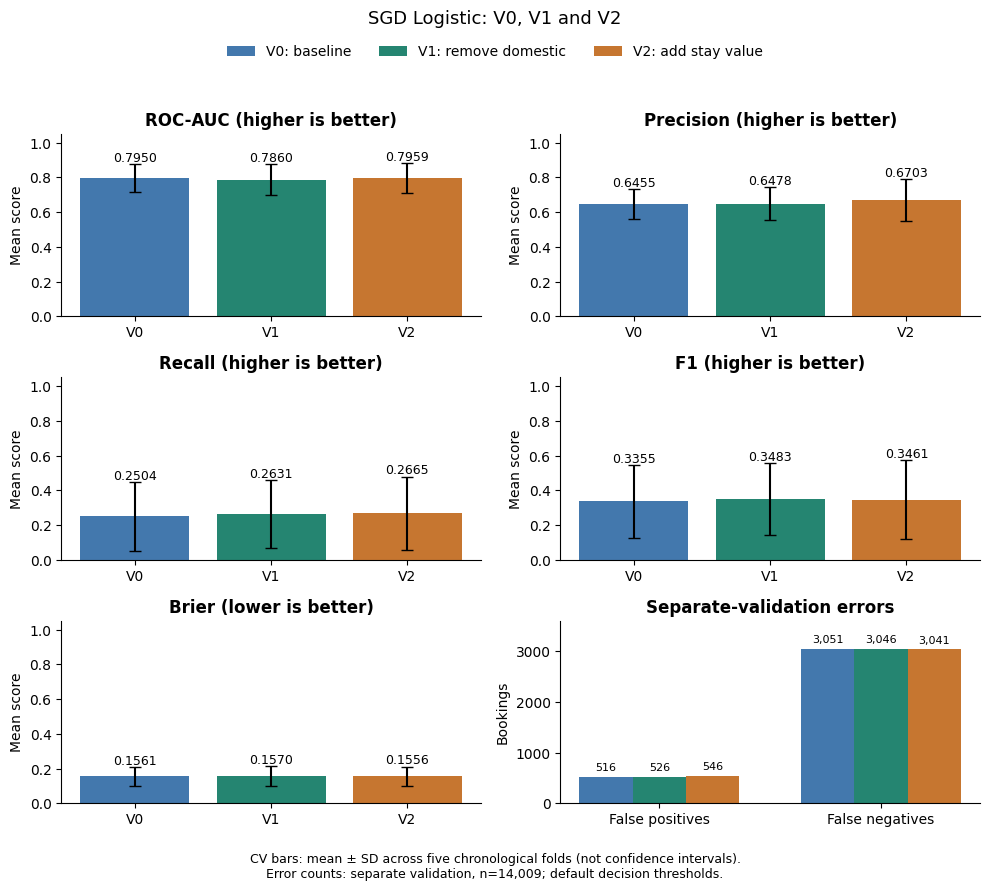

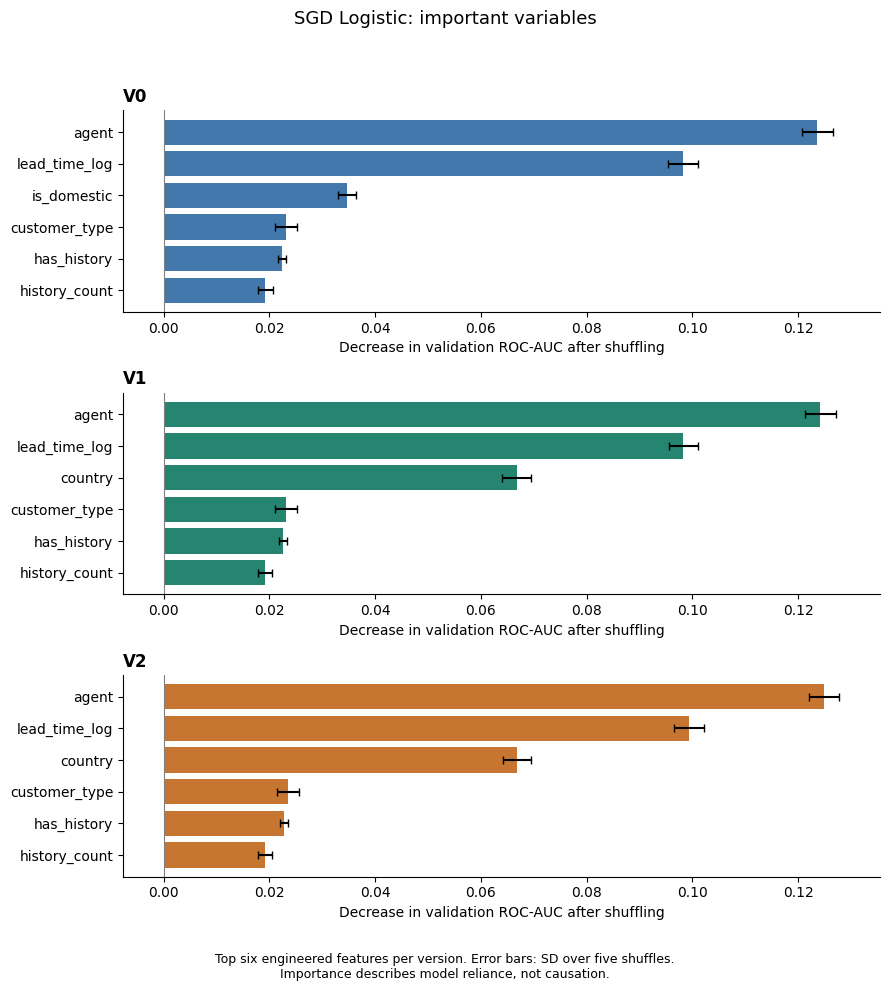

In [102]:
# Show the existing results as simple plots.
plot_member_results("SGD Logistic")

Mean CV ROC-AUC was 0.7950 for V0, 0.7860 for V1, and 0.7912 for V2. The mean AUC changes are small relative to the variation across folds. The leading V0 permutation features were agent, lead_time_log, is_domestic. The new feature's V2 AUC drop was -0.00370.

On the separate validation set, V0 made 516 false positives and 3051 false negatives; V1 made 526 and 3046; V2 made 546 and 3041. For V0, the missed-cancellation rate was 87.5% in Resort Hotel and 71.8% in City Hotel. We should consider both error types: a false positive could lead to double booking if used to release a room, while a false negative can miss a resale opportunity.

## 13.4 Extra Trees — feature experiments

Extra Trees combines randomized decision trees and can learn nonlinear patterns.

### V0: baseline — five-fold CV

In [103]:
# Keep model settings and chronological folds fixed across feature versions.
member_models["Extra Trees"] = (
    ExtraTreesClassifier(n_estimators=90, max_depth=18, min_samples_leaf=4,
                           n_jobs=-1, random_state=MEMBER_SEED), False
)
et_v0_cv_scores, et_v0_cv_summary = member_cv("Extra Trees", "V0")

Extra Trees V0 | Fold 1/5 | ROC-AUC: 0.9383
Extra Trees V0 | Fold 2/5 | ROC-AUC: 0.7237
Extra Trees V0 | Fold 3/5 | ROC-AUC: 0.8128
Extra Trees V0 | Fold 4/5 | ROC-AUC: 0.7583
Extra Trees V0 | Fold 5/5 | ROC-AUC: 0.8225


,ROC_AUC,Precision,Recall,F1,Brier
Fold,,,,,
1,0.9383,0.8194,0.6631,0.7330,0.0640
2,0.7237,0.7088,0.1839,0.2920,0.1509
3,0.8128,0.6858,0.2376,0.3529,0.1475
4,0.7583,0.7370,0.1683,0.2741,0.1788
5,0.8225,0.8024,0.1356,0.2320,0.1570


,Mean,Std
ROC_AUC,0.8111,0.0818
Precision,0.7507,0.0582
Recall,0.2777,0.2186
F1,0.3768,0.2038
Brier,0.1397,0.0440


### V0: errors and important variables

In [104]:
# Fit on the full training period; inspect the separate validation set.
et_v0_analysis = member_analysis("Extra Trees", "V0")

Extra Trees V0: separate-validation confusion matrix


,Predicted: Not canceled,Predicted: Canceled
Actual: Not canceled,9670,332
Actual: Canceled,3015,992


,TN,FP,FN,TP,FP_rate_pct,FN_rate_pct
V0,9670,332,3015,992,3.32,75.24


Errors by hotel


,Orders,Canceled,FP,FN,FP_rate_pct,FN_rate_pct
hotel,,,,,,
Resort Hotel,5189,1109,81,900,1.99,81.15
City Hotel,8820,2898,251,2115,4.24,72.98


...

,59,1747,13260
hotel,City Hotel,Resort Hotel,Resort Hotel
market_segment,Offline TA/TO,Corporate,Offline TA/TO
lead_time,42,0,87
adr,70.72,35.0,48.0
deposit_type,No Deposit,No Deposit,No Deposit
is_repeated_guest,0,1,0
previous_cancellations,0,0,0
Actual,1,1,1
Predicted,0,0,0
Risk_score,0.0143,0.019,0.0207


False positive examples


,6921,6388,6110
hotel,Resort Hotel,City Hotel,Resort Hotel
market_segment,Online TA,Offline TA/TO,Groups
lead_time,167,4,195
adr,44.8,90.0,62.28
deposit_type,No Deposit,No Deposit,No Deposit
is_repeated_guest,0,1,0
previous_cancellations,0,1,0
Actual,0,0,0
Predicted,1,1,1
Risk_score,0.751,0.7495,0.7444


Top ten permutation importances on the separate validation set


,Feature,AUC_drop,Shuffle_SD
0,agent,0.0902,0.0022
1,lead_time_bucket,0.0324,0.0014
2,country,0.0262,0.0023
3,is_domestic,0.0241,0.0020
4,market_segment,0.0179,0.0013
5,customer_type,0.0158,0.0012
6,hotel_market_segment,0.0089,0.0011
7,deposit_type,0.0075,0.0003
8,lead_time_log,0.0075,0.0002
9,lead_time,0.0038,0.0002


### V1: remove is_domestic — five-fold CV

In [105]:
# Keep model settings and chronological folds fixed across feature versions.
et_v1_cv_scores, et_v1_cv_summary = member_cv("Extra Trees", "V1")

Extra Trees V1 | Fold 1/5 | ROC-AUC: 0.9378
Extra Trees V1 | Fold 2/5 | ROC-AUC: 0.7156
Extra Trees V1 | Fold 3/5 | ROC-AUC: 0.8173
Extra Trees V1 | Fold 4/5 | ROC-AUC: 0.7652
Extra Trees V1 | Fold 5/5 | ROC-AUC: 0.8264


,ROC_AUC,Precision,Recall,F1,Brier
Fold,,,,,
1,0.9378,0.8438,0.6534,0.7365,0.0640
2,0.7156,0.7506,0.1672,0.2735,0.1505
3,0.8173,0.7073,0.2167,0.3318,0.1452
4,0.7652,0.7613,0.1485,0.2485,0.1766
5,0.8264,0.8008,0.1303,0.2241,0.1559


,Mean,Std
ROC_AUC,0.8125,0.0830
Precision,0.7728,0.0518
Recall,0.2632,0.2205
F1,0.3629,0.2127
Brier,0.1384,0.0433


### V1: errors and important variables

In [106]:
# Fit on the full training period; inspect the separate validation set.
et_v1_analysis = member_analysis("Extra Trees", "V1")

Extra Trees V1: separate-validation confusion matrix


,Predicted: Not canceled,Predicted: Canceled
Actual: Not canceled,9732,270
Actual: Canceled,3111,896


,TN,FP,FN,TP,FP_rate_pct,FN_rate_pct
V1,9732,270,3111,896,2.7,77.64


Errors by hotel


,Orders,Canceled,FP,FN,FP_rate_pct,FN_rate_pct
hotel,,,,,,
Resort Hotel,5189,1109,57,937,1.4,84.49
City Hotel,8820,2898,213,2174,3.6,75.02


...

,5385,398,4326
hotel,Resort Hotel,Resort Hotel,Resort Hotel
market_segment,Corporate,Online TA,Direct
lead_time,0,0,0
adr,35.0,48.0,80.0
deposit_type,No Deposit,No Deposit,No Deposit
is_repeated_guest,1,0,0
previous_cancellations,0,0,0
Actual,1,1,1
Predicted,0,0,0
Risk_score,0.0219,0.0251,0.0274


False positive examples


,177,8989,12587
hotel,City Hotel,Resort Hotel,Resort Hotel
market_segment,Online TA,Online TA,Online TA
lead_time,82,74,253
adr,74.8,113.29,62.5
deposit_type,No Deposit,No Deposit,No Deposit
is_repeated_guest,0,0,0
previous_cancellations,0,0,0
Actual,0,0,0
Predicted,1,1,1
Risk_score,0.7567,0.7262,0.6981


Top ten permutation importances on the separate validation set


,Feature,AUC_drop,Shuffle_SD
0,country,0.0825,0.0033
1,agent,0.0718,0.0018
2,lead_time_bucket,0.0286,0.0012
3,customer_type,0.0185,0.0013
4,market_segment,0.0152,0.0014
5,deposit_type,0.0112,0.0004
6,lead_time_log,0.0070,0.0004
7,hotel_market_segment,0.0068,0.0010
8,lead_time,0.0029,0.0003
9,hotel,0.0026,0.0004


### V2: V1 plus estimated_stay_value — five-fold CV

In [107]:
# Keep model settings and chronological folds fixed across feature versions.
et_v2_cv_scores, et_v2_cv_summary = member_cv("Extra Trees", "V2")

Extra Trees V2 | Fold 1/5 | ROC-AUC: 0.9398
Extra Trees V2 | Fold 2/5 | ROC-AUC: 0.7375
Extra Trees V2 | Fold 3/5 | ROC-AUC: 0.8187
Extra Trees V2 | Fold 4/5 | ROC-AUC: 0.7647
Extra Trees V2 | Fold 5/5 | ROC-AUC: 0.8246


,ROC_AUC,Precision,Recall,F1,Brier
Fold,,,,,
1,0.9398,0.8348,0.6602,0.7373,0.0635
2,0.7375,0.7218,0.1744,0.2810,0.1485
3,0.8187,0.7121,0.2058,0.3193,0.1457
4,0.7647,0.7652,0.1490,0.2495,0.1773
5,0.8246,0.7833,0.1316,0.2253,0.1565


,Mean,Std
ROC_AUC,0.8170,0.0778
Precision,0.7634,0.0496
Recall,0.2642,0.2231
F1,0.3625,0.2125
Brier,0.1383,0.0436


### V2: errors and important variables

In [108]:
# Fit on the full training period; inspect the separate validation set.
et_v2_analysis = member_analysis("Extra Trees", "V2")

Extra Trees V2: separate-validation confusion matrix


,Predicted: Not canceled,Predicted: Canceled
Actual: Not canceled,9751,251
Actual: Canceled,3157,850


,TN,FP,FN,TP,FP_rate_pct,FN_rate_pct
V2,9751,251,3157,850,2.51,78.79


Errors by hotel


,Orders,Canceled,FP,FN,FP_rate_pct,FN_rate_pct
hotel,,,,,,
Resort Hotel,5189,1109,55,950,1.35,85.66
City Hotel,8820,2898,196,2207,3.31,76.16


...

,177,6388,8989
hotel,City Hotel,City Hotel,Resort Hotel
market_segment,Online TA,Offline TA/TO,Online TA
lead_time,82,4,74
adr,74.8,90.0,113.29
deposit_type,No Deposit,No Deposit,No Deposit
is_repeated_guest,0,1,0
previous_cancellations,0,1,0
Actual,0,0,0
Predicted,1,1,1
Risk_score,0.7715,0.7597,0.714


Top ten permutation importances on the separate validation set


,Feature,AUC_drop,Shuffle_SD
0,country,0.0827,0.0034
1,agent,0.0649,0.0017
2,lead_time_bucket,0.0349,0.0014
3,customer_type,0.0174,0.0013
4,market_segment,0.0145,0.0014
5,deposit_type,0.0105,0.0004
6,hotel_market_segment,0.0069,0.0010
7,lead_time_log,0.0048,0.0005
8,has_agent,0.0024,0.0005
9,hotel,0.0021,0.0004


New feature importance


,Feature,AUC_drop,Shuffle_SD
25,estimated_stay_value,0.0003,0.00017


### Compare V0, V1 and V2

In [109]:
# Compare feature experiments without evaluating the final test set.
et_version_comparison, et_error_comparison = member_compare("Extra Trees")

Five-fold mean and standard deviation


V0              V1              V2        
             Mean     Std    Mean     Std    Mean     Std
ROC_AUC    0.8111  0.0818  0.8125  0.0830  0.8170  0.0778
Precision  0.7507  0.0582  0.7728  0.0518  0.7634  0.0496
Recall     0.2777  0.2186  0.2632  0.2205  0.2642  0.2231
F1         0.3768  0.2038  0.3629  0.2127  0.3625  0.2125
Brier      0.1397  0.0440  0.1384  0.0433  0.1383  0.0436

Separate-validation error comparison


,TN,FP,FN,TP,FP_rate_pct,FN_rate_pct
Version,,,,,,
V0,9670.0,332.0,3015.0,992.0,3.32,75.24
V1,9732.0,270.0,3111.0,896.0,2.70,77.64
V2,9751.0,251.0,3157.0,850.0,2.51,78.79


Permutation-importance comparison (top ten in V2)


,V0,V1,V2
Feature,,,
country,0.0262,0.0825,0.0827
agent,0.0902,0.0718,0.0649
lead_time_bucket,0.0324,0.0286,0.0349
customer_type,0.0158,0.0185,0.0174
market_segment,0.0179,0.0152,0.0145
deposit_type,0.0075,0.0112,0.0105
hotel_market_segment,0.0089,0.0068,0.0069
lead_time_log,0.0075,0.0070,0.0048
has_agent,0.0015,0.0016,0.0024


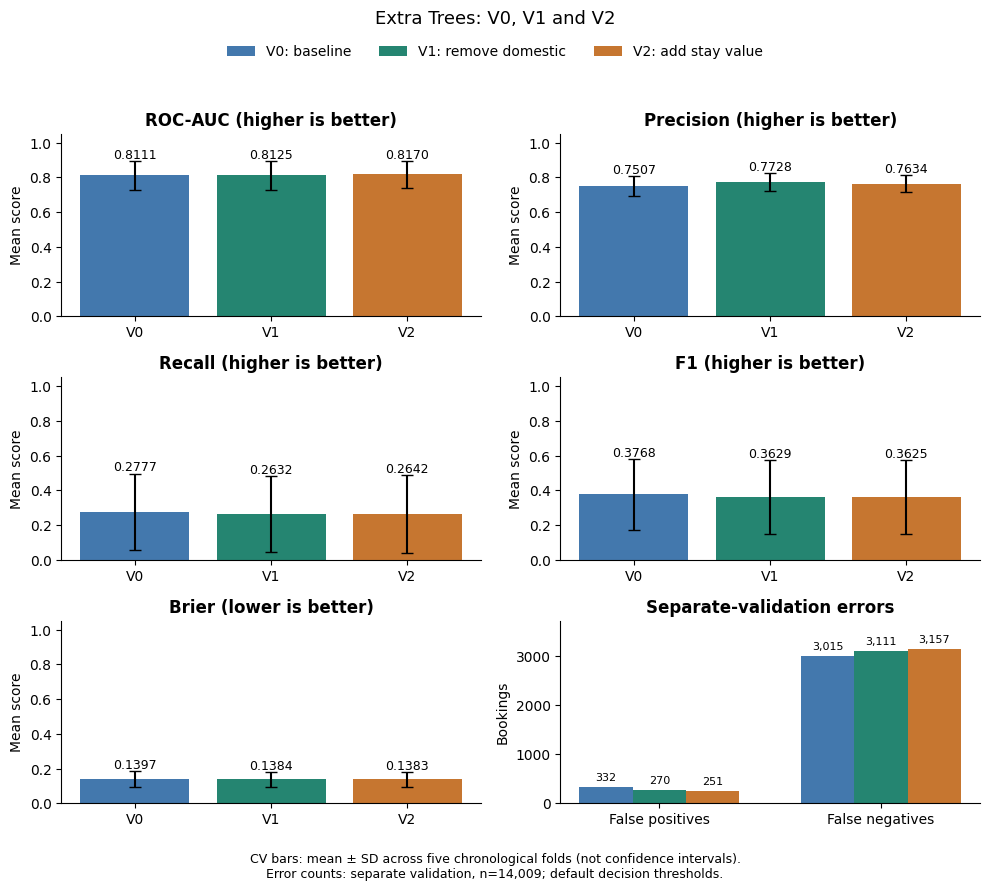

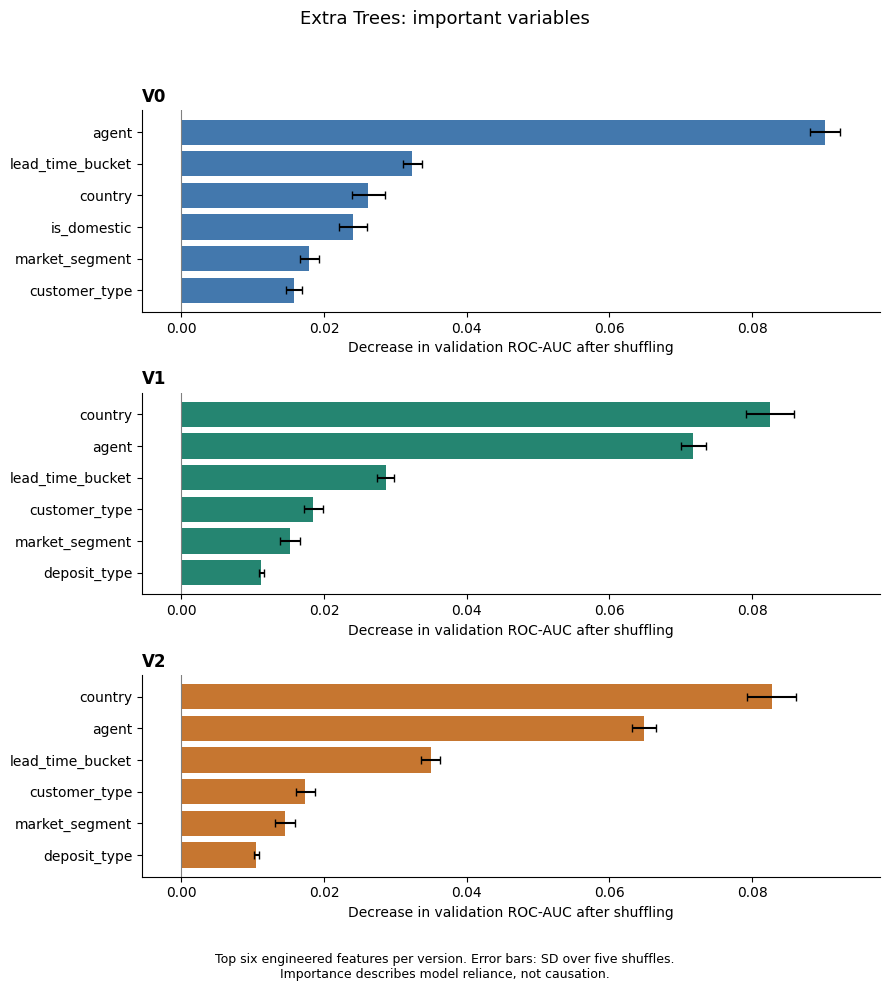

In [110]:
# Show the existing results as simple plots.
plot_member_results("Extra Trees")

Mean CV ROC-AUC was 0.8111 for V0, 0.8137 for V1, and 0.8166 for V2. The mean AUC changes are small relative to the variation across folds. The leading V0 permutation features were agent, lead_time_bucket, country. The new feature's V2 AUC drop was 0.00051.

On the separate validation set, V0 made 348 false positives and 3005 false negatives; V1 made 277 and 3120; V2 made 254 and 3145. For V0, the missed-cancellation rate was 81.2% in Resort Hotel and 72.6% in City Hotel. We should consider both error types: a false positive could lead to double booking if used to release a room, while a false negative can miss a resale opportunity.

## 13.5 Linear SVM — feature experiments

Linear SVM learns a linear decision boundary. Its decision scores rank risk but are not probabilities.

### V0: baseline — five-fold CV

In [111]:
# Keep model settings and chronological folds fixed across feature versions.
member_models["Linear SVM"] = (
    LinearSVC(max_iter=2500, dual=False, random_state=MEMBER_SEED), False
)
svm_v0_cv_scores, svm_v0_cv_summary = member_cv("Linear SVM", "V0")

Linear SVM V0 | Fold 1/5 | ROC-AUC: 0.9270
Linear SVM V0 | Fold 2/5 | ROC-AUC: 0.7145
Linear SVM V0 | Fold 3/5 | ROC-AUC: 0.8028
Linear SVM V0 | Fold 4/5 | ROC-AUC: 0.7587
Linear SVM V0 | Fold 5/5 | ROC-AUC: 0.8076


,ROC_AUC,Precision,Recall,F1,Brier
Fold,,,,,
1,0.9270,0.8028,0.5634,0.6621,NaN
2,0.7145,0.6466,0.1433,0.2347,NaN
3,0.8028,0.5864,0.2824,0.3812,NaN
4,0.7587,0.5881,0.1168,0.1949,NaN
5,0.8076,0.6835,0.1443,0.2383,NaN


,Mean,Std
ROC_AUC,0.8021,0.0793
Precision,0.6615,0.0890
Recall,0.2501,0.1868
F1,0.3422,0.1923
Brier,NaN,NaN


### V0: errors and important variables

In [112]:
# Fit on the full training period; inspect the separate validation set.
svm_v0_analysis = member_analysis("Linear SVM", "V0")

Linear SVM V0: separate-validation confusion matrix


,Predicted: Not canceled,Predicted: Canceled
Actual: Not canceled,9586,416
Actual: Canceled,3021,986


,TN,FP,FN,TP,FP_rate_pct,FN_rate_pct
V0,9586,416,3021,986,4.16,75.39


Errors by hotel


,Orders,Canceled,FP,FN,FP_rate_pct,FN_rate_pct
hotel,,,,,,
Resort Hotel,5189,1109,61,983,1.50,88.64
City Hotel,8820,2898,355,2038,5.99,70.32


...

,2356,4326,3428
hotel,City Hotel,Resort Hotel,Resort Hotel
market_segment,Aviation,Direct,Online TA
lead_time,1,0,0
adr,0.0,80.0,0.0
deposit_type,No Deposit,No Deposit,No Deposit
is_repeated_guest,1,0,0
previous_cancellations,0,0,0
Actual,1,1,1
Predicted,0,0,0
Risk_score,-2.2261,-1.9784,-1.8918


False positive examples


,3094,6388,7646
hotel,City Hotel,City Hotel,City Hotel
market_segment,Direct,Offline TA/TO,Online TA
lead_time,2,4,212
adr,79.0,90.0,122.4
deposit_type,No Deposit,No Deposit,No Deposit
is_repeated_guest,1,1,0
previous_cancellations,1,1,0
Actual,0,0,0
Predicted,1,1,1
Risk_score,1.1091,0.7231,0.6344


Top ten permutation importances on the separate validation set


,Feature,AUC_drop,Shuffle_SD
0,agent,0.1103,0.0025
1,lead_time_log,0.0575,0.0021
2,is_domestic,0.0390,0.0017
3,history_count,0.0228,0.0013
4,country,0.0227,0.0016
5,customer_type,0.0208,0.0019
6,has_history,0.0168,0.0007
7,lead_time_bucket,0.0147,0.0011
8,hotel_market_segment,0.0099,0.0008
9,hotel,0.0085,0.0010


### V1: remove is_domestic — five-fold CV

In [113]:
# Keep model settings and chronological folds fixed across feature versions.
svm_v1_cv_scores, svm_v1_cv_summary = member_cv("Linear SVM", "V1")

Linear SVM V1 | Fold 1/5 | ROC-AUC: 0.9269
Linear SVM V1 | Fold 2/5 | ROC-AUC: 0.7145
Linear SVM V1 | Fold 3/5 | ROC-AUC: 0.8028
Linear SVM V1 | Fold 4/5 | ROC-AUC: 0.7587
Linear SVM V1 | Fold 5/5 | ROC-AUC: 0.8076


,ROC_AUC,Precision,Recall,F1,Brier
Fold,,,,,
1,0.9269,0.8028,0.5634,0.6621,NaN
2,0.7145,0.6450,0.1433,0.2345,NaN
3,0.8028,0.5866,0.2828,0.3816,NaN
4,0.7587,0.5881,0.1168,0.1949,NaN
5,0.8076,0.6830,0.1440,0.2378,NaN


,Mean,Std
ROC_AUC,0.8021,0.0793
Precision,0.6611,0.0890
Recall,0.2501,0.1869
F1,0.3422,0.1924
Brier,NaN,NaN


### V1: errors and important variables

In [114]:
# Fit on the full training period; inspect the separate validation set.
svm_v1_analysis = member_analysis("Linear SVM", "V1")

Linear SVM V1: separate-validation confusion matrix


,Predicted: Not canceled,Predicted: Canceled
Actual: Not canceled,9587,415
Actual: Canceled,3020,987


,TN,FP,FN,TP,FP_rate_pct,FN_rate_pct
V1,9587,415,3020,987,4.15,75.37


Errors by hotel


,Orders,Canceled,FP,FN,FP_rate_pct,FN_rate_pct
hotel,,,,,,
Resort Hotel,5189,1109,61,983,1.50,88.64
City Hotel,8820,2898,354,2037,5.98,70.29


...

,2356,4326,3428
hotel,City Hotel,Resort Hotel,Resort Hotel
market_segment,Aviation,Direct,Online TA
lead_time,1,0,0
adr,0.0,80.0,0.0
deposit_type,No Deposit,No Deposit,No Deposit
is_repeated_guest,1,0,0
previous_cancellations,0,0,0
Actual,1,1,1
Predicted,0,0,0
Risk_score,-2.226,-1.9783,-1.8919


False positive examples


,3094,6388,7646
hotel,City Hotel,City Hotel,City Hotel
market_segment,Direct,Offline TA/TO,Online TA
lead_time,2,4,212
adr,79.0,90.0,122.4
deposit_type,No Deposit,No Deposit,No Deposit
is_repeated_guest,1,1,0
previous_cancellations,1,1,0
Actual,0,0,0
Predicted,1,1,1
Risk_score,1.1091,0.7231,0.6344


Top ten permutation importances on the separate validation set


,Feature,AUC_drop,Shuffle_SD
0,agent,0.1110,0.0025
1,country,0.0750,0.0026
2,lead_time_log,0.0576,0.0021
3,history_count,0.0228,0.0013
4,customer_type,0.0208,0.0019
5,has_history,0.0168,0.0007
6,lead_time_bucket,0.0147,0.0011
7,hotel_market_segment,0.0098,0.0008
8,hotel,0.0083,0.0009
9,total_guests,0.0080,0.0006


### V2: V1 plus estimated_stay_value — five-fold CV

In [115]:
# Keep model settings and chronological folds fixed across feature versions.
svm_v2_cv_scores, svm_v2_cv_summary = member_cv("Linear SVM", "V2")

Linear SVM V2 | Fold 1/5 | ROC-AUC: 0.9276
Linear SVM V2 | Fold 2/5 | ROC-AUC: 0.7122
Linear SVM V2 | Fold 3/5 | ROC-AUC: 0.8028
Linear SVM V2 | Fold 4/5 | ROC-AUC: 0.7580
Linear SVM V2 | Fold 5/5 | ROC-AUC: 0.8076


,ROC_AUC,Precision,Recall,F1,Brier
Fold,,,,,
1,0.9276,0.8209,0.5634,0.6682,NaN
2,0.7122,0.6643,0.1572,0.2543,NaN
3,0.8028,0.5858,0.2910,0.3888,NaN
4,0.7580,0.5771,0.1083,0.1823,NaN
5,0.8076,0.6820,0.1440,0.2377,NaN


,Mean,Std
ROC_AUC,0.8016,0.0803
Precision,0.6660,0.0982
Recall,0.2528,0.1870
F1,0.3463,0.1953
Brier,NaN,NaN


### V2: errors and important variables

In [116]:
# Fit on the full training period; inspect the separate validation set.
svm_v2_analysis = member_analysis("Linear SVM", "V2")

Linear SVM V2: separate-validation confusion matrix


,Predicted: Not canceled,Predicted: Canceled
Actual: Not canceled,9583,419
Actual: Canceled,3019,988


,TN,FP,FN,TP,FP_rate_pct,FN_rate_pct
V2,9583,419,3019,988,4.19,75.34


Errors by hotel


,Orders,Canceled,FP,FN,FP_rate_pct,FN_rate_pct
hotel,,,,,,
Resort Hotel,5189,1109,62,980,1.52,88.37
City Hotel,8820,2898,357,2039,6.03,70.36


...

,3094,6388,7646
hotel,City Hotel,City Hotel,City Hotel
market_segment,Direct,Offline TA/TO,Online TA
lead_time,2,4,212
adr,79.0,90.0,122.4
deposit_type,No Deposit,No Deposit,No Deposit
is_repeated_guest,1,1,0
previous_cancellations,1,1,0
Actual,0,0,0
Predicted,1,1,1
Risk_score,1.1127,0.7226,0.6363


Top ten permutation importances on the separate validation set


,Feature,AUC_drop,Shuffle_SD
0,agent,0.1108,0.0024
1,country,0.0755,0.0026
2,lead_time_log,0.0575,0.0021
3,history_count,0.0226,0.0013
4,customer_type,0.0210,0.0019
5,has_history,0.0167,0.0007
6,lead_time_bucket,0.0144,0.0011
7,hotel_market_segment,0.0098,0.0007
8,hotel,0.0086,0.0010
9,deposit_type,0.0080,0.0004


New feature importance


,Feature,AUC_drop,Shuffle_SD
34,estimated_stay_value,0.00002,0.00038


### Compare V0, V1 and V2

In [117]:
# Compare feature experiments without evaluating the final test set.
svm_version_comparison, svm_error_comparison = member_compare("Linear SVM")

Five-fold mean and standard deviation


V0              V1              V2        
             Mean     Std    Mean     Std    Mean     Std
ROC_AUC    0.8021  0.0793  0.8021  0.0793  0.8016  0.0803
Precision  0.6615  0.0890  0.6611  0.0890  0.6660  0.0982
Recall     0.2501  0.1868  0.2501  0.1869  0.2528  0.1870
F1         0.3422  0.1923  0.3422  0.1924  0.3463  0.1953
Brier         NaN     NaN     NaN     NaN     NaN     NaN

Separate-validation error comparison


,TN,FP,FN,TP,FP_rate_pct,FN_rate_pct
Version,,,,,,
V0,9586.0,416.0,3021.0,986.0,4.16,75.39
V1,9587.0,415.0,3020.0,987.0,4.15,75.37
V2,9583.0,419.0,3019.0,988.0,4.19,75.34


Permutation-importance comparison (top ten in V2)


,V0,V1,V2
Feature,,,
agent,0.1103,0.1110,0.1108
country,0.0227,0.0750,0.0755
lead_time_log,0.0575,0.0576,0.0575
history_count,0.0228,0.0228,0.0226
customer_type,0.0208,0.0208,0.0210
has_history,0.0168,0.0168,0.0167
lead_time_bucket,0.0147,0.0147,0.0144
hotel_market_segment,0.0099,0.0098,0.0098
hotel,0.0085,0.0083,0.0086


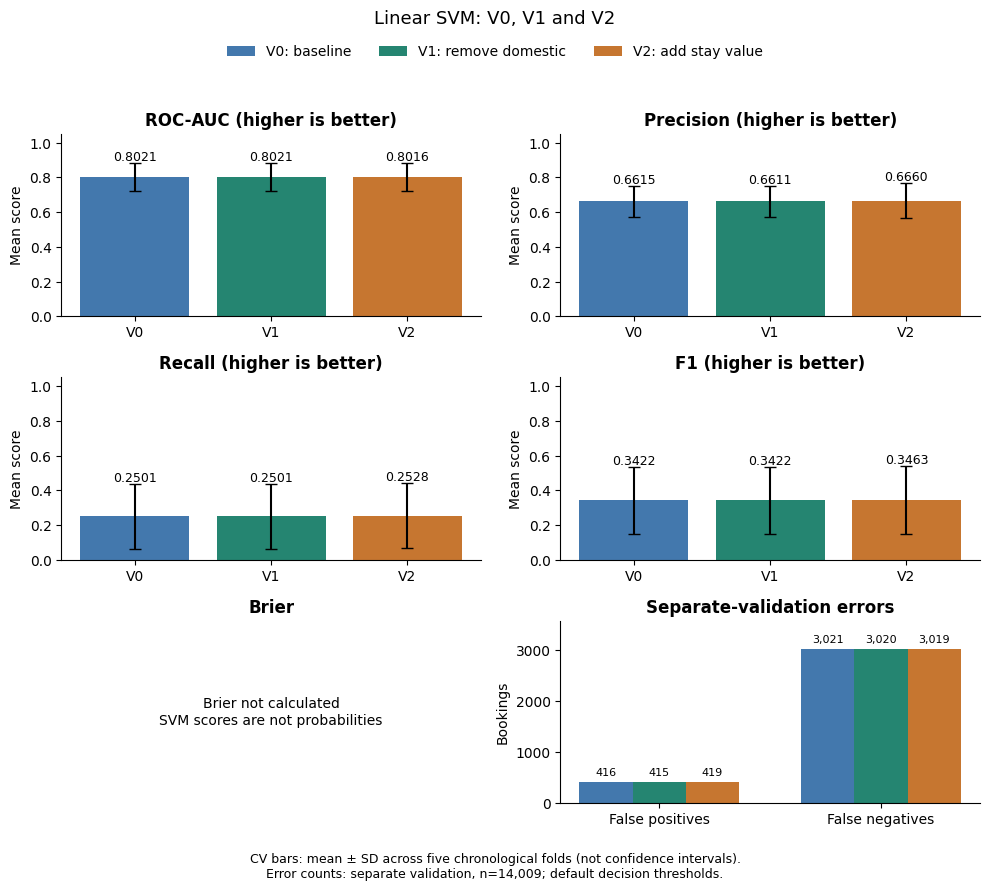

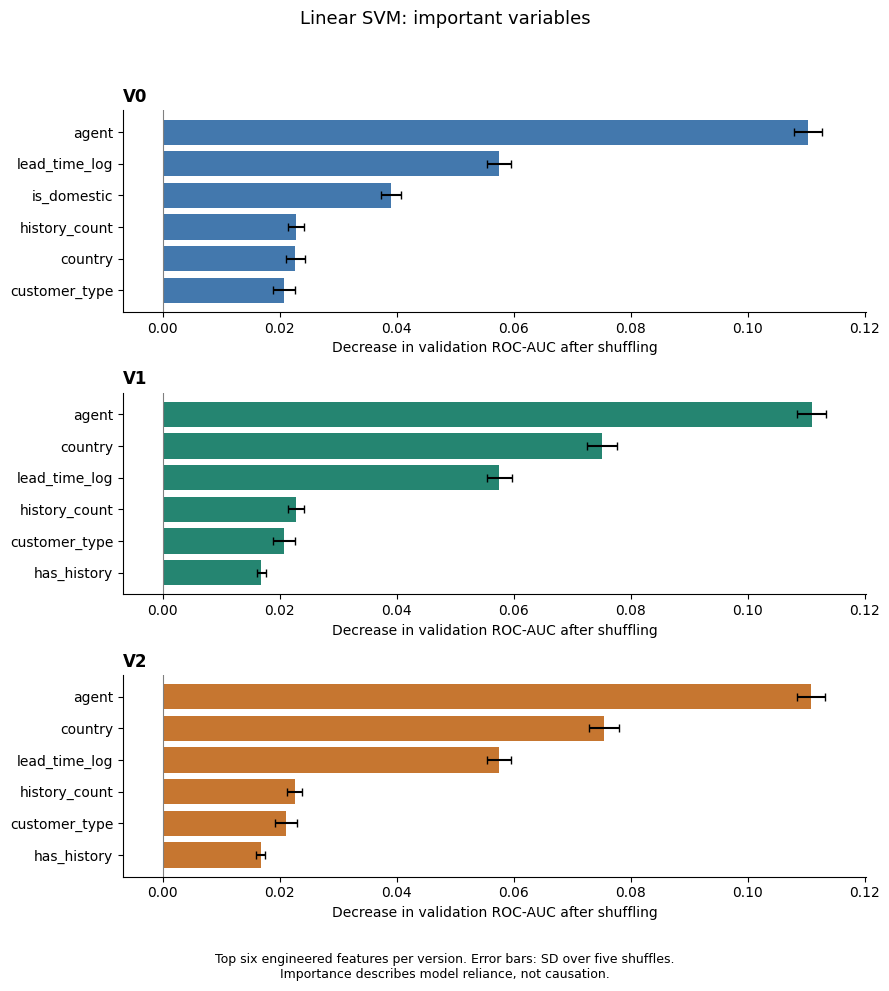

In [118]:
# Show the existing results as simple plots.
plot_member_results("Linear SVM")

Mean CV ROC-AUC was 0.8021 for V0, 0.8021 for V1, and 0.8016 for V2. The mean AUC changes are small relative to the variation across folds. The leading V0 permutation features were agent, lead_time_log, is_domestic. The new feature's V2 AUC drop was 0.00002.

On the separate validation set, V0 made 416 false positives and 3021 false negatives; V1 made 416 and 3020; V2 made 419 and 3019. For V0, the missed-cancellation rate was 88.6% in Resort Hotel and 70.3% in City Hotel. We should consider both error types: a false positive could lead to double booking if used to release a room, while a false negative can miss a resale opportunity.

## 13.6 Histogram Gradient Boosting — feature experiments

Histogram Gradient Boosting adds trees sequentially to improve the predictions.

### V0: baseline — five-fold CV

In [119]:
# Keep model settings and chronological folds fixed across feature versions.
member_models["Histogram Gradient Boosting"] = (
    HistGradientBoostingClassifier(max_iter=110, max_leaf_nodes=25,
                                      random_state=MEMBER_SEED), True
)
hgb_v0_cv_scores, hgb_v0_cv_summary = member_cv("Histogram Gradient Boosting", "V0")

Histogram Gradient Boosting V0 | Fold 1/5 | ROC-AUC: 0.9322
Histogram Gradient Boosting V0 | Fold 2/5 | ROC-AUC: 0.7369
Histogram Gradient Boosting V0 | Fold 3/5 | ROC-AUC: 0.7994
Histogram Gradient Boosting V0 | Fold 4/5 | ROC-AUC: 0.6842
Histogram Gradient Boosting V0 | Fold 5/5 | ROC-AUC: 0.8098


,ROC_AUC,Precision,Recall,F1,Brier
Fold,,,,,
1,0.9322,0.7168,0.7009,0.7088,0.0670
2,0.7369,0.7055,0.1850,0.2931,0.1549
3,0.7994,0.6064,0.3259,0.4240,0.1543
4,0.6842,0.7097,0.1636,0.2660,0.2219
5,0.8098,0.7362,0.2368,0.3584,0.1634


,Mean,Std
ROC_AUC,0.7925,0.0931
Precision,0.6949,0.0509
Recall,0.3224,0.2206
F1,0.4100,0.1779
Brier,0.1523,0.0553


### V0: errors and important variables

In [120]:
# Fit on the full training period; inspect the separate validation set.
hgb_v0_analysis = member_analysis("Histogram Gradient Boosting", "V0")

Histogram Gradient Boosting V0: separate-validation confusion matrix


,Predicted: Not canceled,Predicted: Canceled
Actual: Not canceled,9117,885
Actual: Canceled,2336,1671


,TN,FP,FN,TP,FP_rate_pct,FN_rate_pct
V0,9117,885,2336,1671,8.85,58.3


Errors by hotel


,Orders,Canceled,FP,FN,FP_rate_pct,FN_rate_pct
hotel,,,,,,
Resort Hotel,5189,1109,98,862,2.40,77.73
City Hotel,8820,2898,787,1474,13.29,50.86


...

,13260,59,5864
hotel,Resort Hotel,City Hotel,Resort Hotel
market_segment,Offline TA/TO,Offline TA/TO,Groups
lead_time,87,42,8
adr,48.0,70.72,47.0
deposit_type,No Deposit,No Deposit,No Deposit
is_repeated_guest,0,0,0
previous_cancellations,0,0,0
Actual,1,1,1
Predicted,0,0,0
Risk_score,0.0055,0.0062,0.0081


False positive examples


,6388,11082,177
hotel,City Hotel,Resort Hotel,City Hotel
market_segment,Offline TA/TO,Direct,Online TA
lead_time,4,32,82
adr,90.0,204.33,74.8
deposit_type,No Deposit,No Deposit,No Deposit
is_repeated_guest,1,1,0
previous_cancellations,1,2,0
Actual,0,0,0
Predicted,1,1,1
Risk_score,0.9207,0.8988,0.8837


Top ten permutation importances on the separate validation set


,Feature,AUC_drop,Shuffle_SD
0,agent,0.1263,0.0035
1,is_domestic,0.0946,0.0029
2,lead_time,0.0767,0.0021
3,market_segment,0.0371,0.0020
4,customer_type,0.0198,0.0013
5,previous_bookings_not_canceled,0.0149,0.0008
6,country,0.0116,0.0012
7,deposit_type,0.0089,0.0004
8,total_nights,0.0036,0.0004
9,hotel_market_segment,0.0027,0.0005


### V1: remove is_domestic — five-fold CV

In [121]:
# Keep model settings and chronological folds fixed across feature versions.
hgb_v1_cv_scores, hgb_v1_cv_summary = member_cv("Histogram Gradient Boosting", "V1")

Histogram Gradient Boosting V1 | Fold 1/5 | ROC-AUC: 0.9322
Histogram Gradient Boosting V1 | Fold 2/5 | ROC-AUC: 0.7369
Histogram Gradient Boosting V1 | Fold 3/5 | ROC-AUC: 0.7994
Histogram Gradient Boosting V1 | Fold 4/5 | ROC-AUC: 0.6842
Histogram Gradient Boosting V1 | Fold 5/5 | ROC-AUC: 0.8098


,ROC_AUC,Precision,Recall,F1,Brier
Fold,,,,,
1,0.9322,0.7168,0.7009,0.7088,0.0670
2,0.7369,0.7055,0.1850,0.2931,0.1549
3,0.7994,0.6064,0.3259,0.4240,0.1543
4,0.6842,0.7097,0.1636,0.2660,0.2219
5,0.8098,0.7362,0.2368,0.3584,0.1634


,Mean,Std
ROC_AUC,0.7925,0.0931
Precision,0.6949,0.0509
Recall,0.3224,0.2206
F1,0.4100,0.1779
Brier,0.1523,0.0553


### V1: errors and important variables

In [122]:
# Fit on the full training period; inspect the separate validation set.
hgb_v1_analysis = member_analysis("Histogram Gradient Boosting", "V1")

Histogram Gradient Boosting V1: separate-validation confusion matrix


,Predicted: Not canceled,Predicted: Canceled
Actual: Not canceled,9117,885
Actual: Canceled,2336,1671


,TN,FP,FN,TP,FP_rate_pct,FN_rate_pct
V1,9117,885,2336,1671,8.85,58.3


Errors by hotel


,Orders,Canceled,FP,FN,FP_rate_pct,FN_rate_pct
hotel,,,,,,
Resort Hotel,5189,1109,98,862,2.40,77.73
City Hotel,8820,2898,787,1474,13.29,50.86


...

,13260,59,5864
hotel,Resort Hotel,City Hotel,Resort Hotel
market_segment,Offline TA/TO,Offline TA/TO,Groups
lead_time,87,42,8
adr,48.0,70.72,47.0
deposit_type,No Deposit,No Deposit,No Deposit
is_repeated_guest,0,0,0
previous_cancellations,0,0,0
Actual,1,1,1
Predicted,0,0,0
Risk_score,0.0055,0.0062,0.0081


False positive examples


,6388,11082,177
hotel,City Hotel,Resort Hotel,City Hotel
market_segment,Offline TA/TO,Direct,Online TA
lead_time,4,32,82
adr,90.0,204.33,74.8
deposit_type,No Deposit,No Deposit,No Deposit
is_repeated_guest,1,1,0
previous_cancellations,1,2,0
Actual,0,0,0
Predicted,1,1,1
Risk_score,0.9207,0.8988,0.8837


Top ten permutation importances on the separate validation set


,Feature,AUC_drop,Shuffle_SD
0,agent,0.1263,0.0035
1,country,0.1077,0.0039
2,lead_time,0.0767,0.0021
3,market_segment,0.0371,0.0020
4,customer_type,0.0198,0.0013
5,previous_bookings_not_canceled,0.0149,0.0008
6,deposit_type,0.0089,0.0004
7,total_nights,0.0036,0.0004
8,hotel_market_segment,0.0027,0.0005
9,has_agent,0.0012,0.0002


### V2: V1 plus estimated_stay_value — five-fold CV

In [123]:
# Keep model settings and chronological folds fixed across feature versions.
hgb_v2_cv_scores, hgb_v2_cv_summary = member_cv("Histogram Gradient Boosting", "V2")

Histogram Gradient Boosting V2 | Fold 1/5 | ROC-AUC: 0.9304
Histogram Gradient Boosting V2 | Fold 2/5 | ROC-AUC: 0.7414
Histogram Gradient Boosting V2 | Fold 3/5 | ROC-AUC: 0.7986
Histogram Gradient Boosting V2 | Fold 4/5 | ROC-AUC: 0.6839
Histogram Gradient Boosting V2 | Fold 5/5 | ROC-AUC: 0.8096


,ROC_AUC,Precision,Recall,F1,Brier
Fold,,,,,
1,0.9304,0.7364,0.6951,0.7151,0.0668
2,0.7414,0.7013,0.1761,0.2815,0.1533
3,0.7986,0.6364,0.2828,0.3916,0.1554
4,0.6839,0.7074,0.1625,0.2643,0.2220
5,0.8096,0.7537,0.2034,0.3204,0.1651


,Mean,Std
ROC_AUC,0.7928,0.0919
Precision,0.7070,0.0449
Recall,0.3040,0.2235
F1,0.3946,0.1858
Brier,0.1525,0.0556


### V2: errors and important variables

In [124]:
# Fit on the full training period; inspect the separate validation set.
hgb_v2_analysis = member_analysis("Histogram Gradient Boosting", "V2")

Histogram Gradient Boosting V2: separate-validation confusion matrix


,Predicted: Not canceled,Predicted: Canceled
Actual: Not canceled,9075,927
Actual: Canceled,2282,1725


,TN,FP,FN,TP,FP_rate_pct,FN_rate_pct
V2,9075,927,2282,1725,9.27,56.95


Errors by hotel


,Orders,Canceled,FP,FN,FP_rate_pct,FN_rate_pct
hotel,,,,,,
Resort Hotel,5189,1109,101,844,2.48,76.10
City Hotel,8820,2898,826,1438,13.95,49.62


...

,177,11082,1741
hotel,City Hotel,Resort Hotel,City Hotel
market_segment,Online TA,Direct,Online TA
lead_time,82,32,5
adr,74.8,204.33,223.0
deposit_type,No Deposit,No Deposit,No Deposit
is_repeated_guest,0,1,0
previous_cancellations,0,2,0
Actual,0,0,0
Predicted,1,1,1
Risk_score,0.9198,0.9082,0.8879


Top ten permutation importances on the separate validation set


,Feature,AUC_drop,Shuffle_SD
0,agent,0.1254,0.0035
1,country,0.1082,0.0040
2,lead_time,0.0770,0.0023
3,market_segment,0.0369,0.0020
4,customer_type,0.0206,0.0014
5,previous_bookings_not_canceled,0.0173,0.0010
6,deposit_type,0.0098,0.0003
7,estimated_stay_value,0.0027,0.0004
8,hotel_market_segment,0.0022,0.0002
9,total_nights,0.0021,0.0002


New feature importance


,Feature,AUC_drop,Shuffle_SD
7,estimated_stay_value,0.00265,0.00039


### Compare V0, V1 and V2

In [125]:
# Compare feature experiments without evaluating the final test set.
hgb_version_comparison, hgb_error_comparison = member_compare("Histogram Gradient Boosting")

Five-fold mean and standard deviation


V0              V1              V2        
             Mean     Std    Mean     Std    Mean     Std
ROC_AUC    0.7925  0.0931  0.7925  0.0931  0.7928  0.0919
Precision  0.6949  0.0509  0.6949  0.0509  0.7070  0.0449
Recall     0.3224  0.2206  0.3224  0.2206  0.3040  0.2235
F1         0.4100  0.1779  0.4100  0.1779  0.3946  0.1858
Brier      0.1523  0.0553  0.1523  0.0553  0.1525  0.0556

Separate-validation error comparison


,TN,FP,FN,TP,FP_rate_pct,FN_rate_pct
Version,,,,,,
V0,9117.0,885.0,2336.0,1671.0,8.85,58.30
V1,9117.0,885.0,2336.0,1671.0,8.85,58.30
V2,9075.0,927.0,2282.0,1725.0,9.27,56.95


Permutation-importance comparison (top ten in V2)


,V0,V1,V2
Feature,,,
agent,0.1263,0.1263,0.1254
country,0.0116,0.1077,0.1082
lead_time,0.0767,0.0767,0.0770
market_segment,0.0371,0.0371,0.0369
customer_type,0.0198,0.0198,0.0206
previous_bookings_not_canceled,0.0149,0.0149,0.0173
deposit_type,0.0089,0.0089,0.0098
estimated_stay_value,NaN,NaN,0.0027
hotel_market_segment,0.0027,0.0027,0.0022


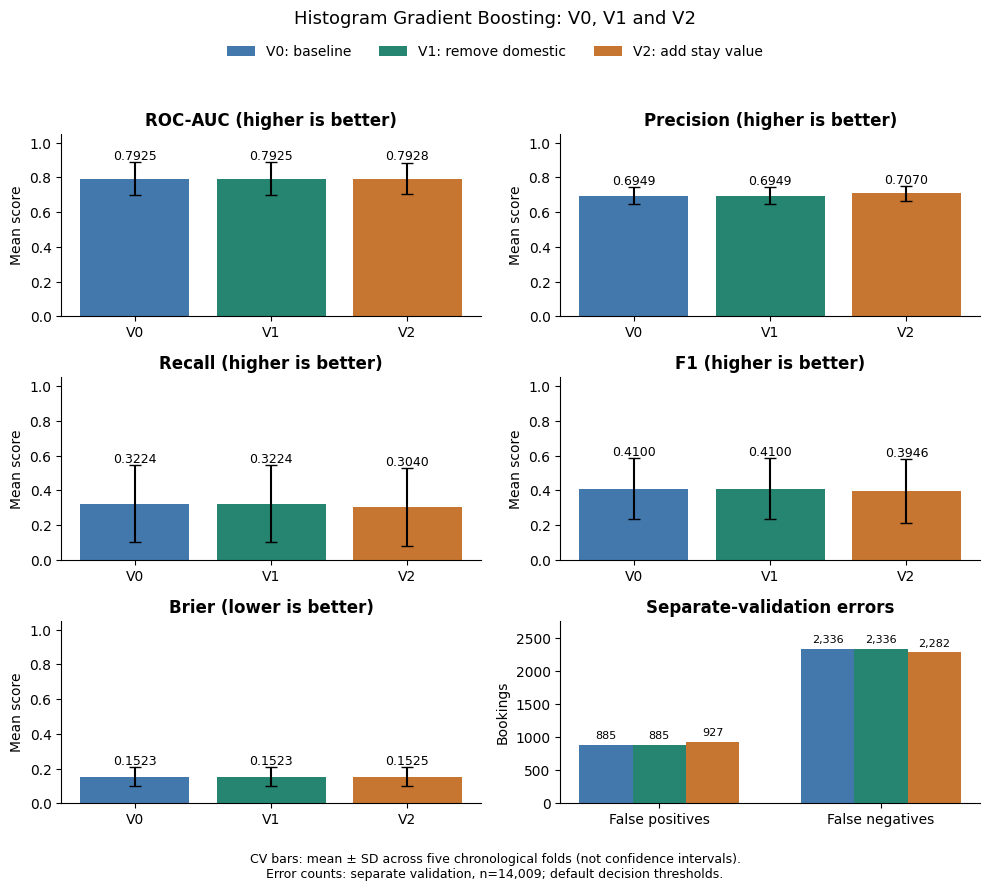

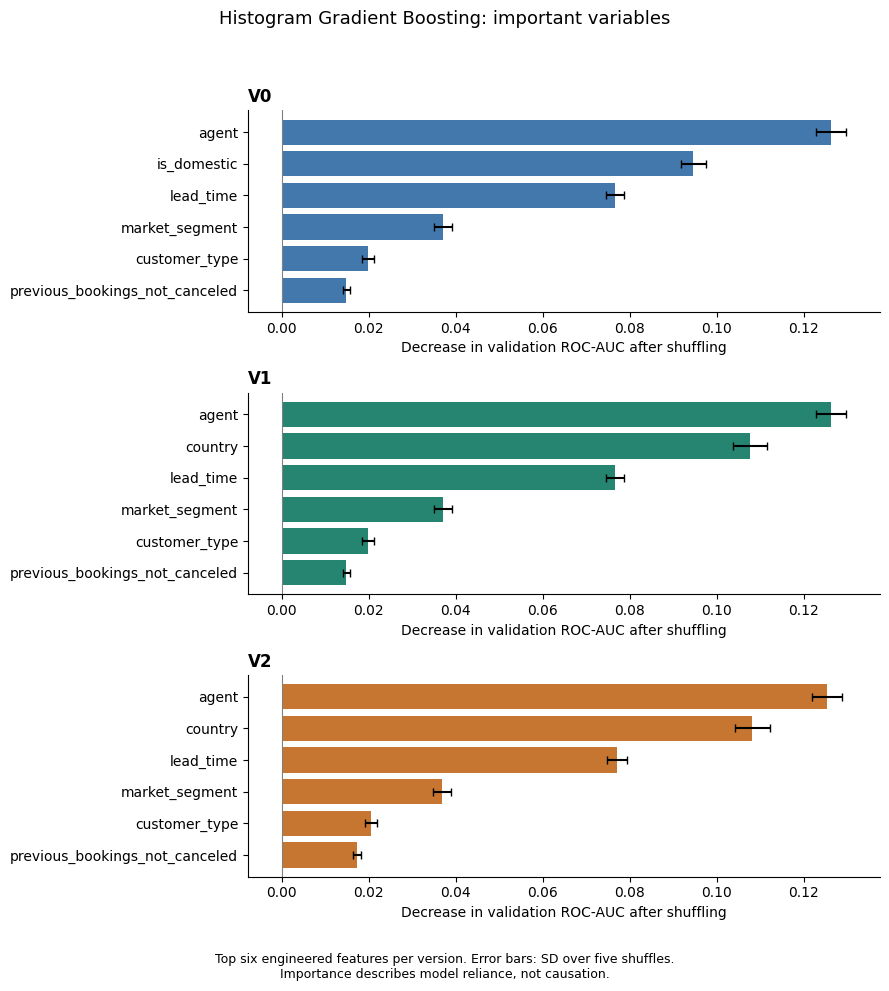

In [126]:
# Show the existing results as simple plots.
plot_member_results("Histogram Gradient Boosting")

Mean CV ROC-AUC was 0.7930 for V0, 0.7930 for V1, and 0.7932 for V2. The mean AUC changes are small relative to the variation across folds. The leading V0 permutation features were agent, is_domestic, lead_time. The new feature's V2 AUC drop was 0.00227.

On the separate validation set, V0 made 903 false positives and 2322 false negatives; V1 made 903 and 2322; V2 made 884 and 2338. For V0, the missed-cancellation rate was 77.5% in Resort Hotel and 50.5% in City Hotel. We should consider both error types: a false positive could lead to double booking if used to release a room, while a false negative can miss a resale opportunity.

## 13.7 Random Forest


### 13.7.1 Random Forest — V0: Five-Fold Chronological Cross-Validation

In [127]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Build the Random Forest pipeline
RANDOM_STATE = 67
rf_pipeline = Pipeline([
    ("prepare", clone(prepare_pipeline)),
    ("model", RandomForestClassifier(
        n_estimators=90, max_depth=16, min_samples_leaf=4,
        random_state=RANDOM_STATE, n_jobs=-1
    ))
])

# Evaluate using the shared five chronological folds
rf_cv_scores, rf_cv_summary = evaluate_model("Random Forest", rf_pipeline)

Random Forest: fold 1/5 completed
Random Forest: fold 2/5 completed
Random Forest: fold 3/5 completed
Random Forest: fold 4/5 completed
Random Forest: fold 5/5 completed


,ROC_AUC,Precision,Recall,F1,Brier
Fold,,,,,
1,0.9307,0.8348,0.6505,0.7312,0.0639
2,0.7092,0.7048,0.1778,0.2839,0.1517
3,0.8120,0.7065,0.2167,0.3317,0.1483
4,0.7437,0.7276,0.1501,0.2489,0.1868
5,0.8035,0.8064,0.1099,0.1934,0.1631


,mean,std
ROC_AUC,0.7998,0.0846
Precision,0.7560,0.0605
Recall,0.2610,0.2212
F1,0.3578,0.2147
Brier,0.1427,0.0466


The ROC_AUC mean is 0.79. Random Forest has almost the same AUC as LR, with higher Precision and a lower Brier score for its predicted probabilities;

### 13.7.2 Random Forest — V0: Permutation Feature Importance

Fitting the analysis model...
Calculating permutation importance...


,Feature,AUC_drop,Shuffle_SD
0,agent,0.06520,0.00143
1,country,0.02928,0.00194
2,is_domestic,0.01894,0.00145
3,market_segment,0.01869,0.00117
4,customer_type,0.01335,0.00098
5,lead_time,0.01330,0.00111
6,lead_time_log,0.01274,0.00114
7,lead_time_bucket,0.01026,0.00069
8,hotel_market_segment,0.00827,0.00108
9,deposit_type,0.00719,0.00039


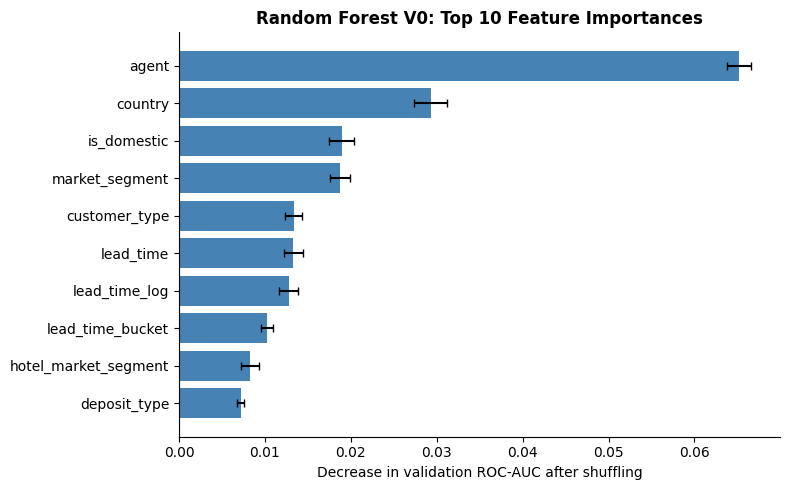

In [128]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance

# Fit an analysis model on the full training sample
print("Fitting the analysis model...")
rf_analysis_model = clone(rf_pipeline).fit(X_train_raw, y_train)

# Calculate importance after feature engineering and before one-hot encoding
rf_prepare = rf_analysis_model.named_steps["prepare"]
X_valid_rf_features = rf_prepare[0].transform(X_valid_raw)
rf_feature_model = Pipeline([
    ("preprocessing", rf_prepare[1]),
    ("model", rf_analysis_model.named_steps["model"])
])
print("Calculating permutation importance...")
rf_pi = permutation_importance(
    rf_feature_model, X_valid_rf_features, y_valid,
    scoring="roc_auc", n_repeats=5, random_state=67, n_jobs=1
)
rf_importance = pd.DataFrame({
    "Feature": X_valid_rf_features.columns,
    "AUC_drop": rf_pi.importances_mean,
    "Shuffle_SD": rf_pi.importances_std
}).sort_values("AUC_drop", ascending=False).reset_index(drop=True)
display(rf_importance.head(15).round(5))

# Plot the ten most important features
top = rf_importance.head(10).sort_values("AUC_drop")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top["Feature"], top["AUC_drop"], xerr=top["Shuffle_SD"],
        color="steelblue", capsize=3)
ax.axvline(0, color="gray", linewidth=0.8)
ax.set(xlabel="Decrease in validation ROC-AUC after shuffling",
       title="Random Forest V0: Top 10 Feature Importances")
fig.tight_layout()
plt.show()

### 13.7.3 Random Forest — V0: Validation Error Analysis

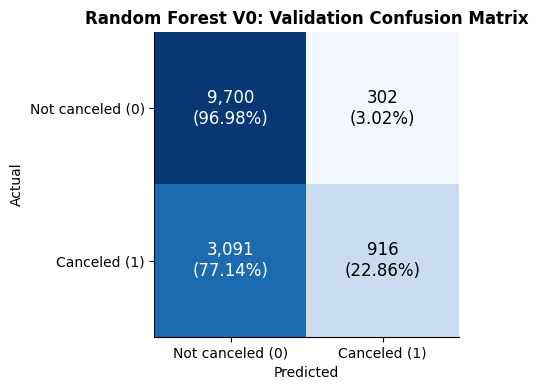

,FP,FN,FP_rate_pct,FN_rate_pct
V0_Baseline,302,3091,3.02%,77.14%


In [129]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import confusion_matrix

# Save validation predictions for error analysis
rf_cases = X_valid_raw.reset_index(drop=True).copy()
rf_cases["Actual"] = np.asarray(y_valid, dtype=int)
rf_cases["Cancel_probability"] = rf_analysis_model.predict_proba(X_valid_raw)[:, 1]
rf_cases["Predicted"] = (rf_cases["Cancel_probability"] >= 0.5).astype(int)

# Calculate counts and percentages within each actual class
rf_cm = confusion_matrix(rf_cases["Actual"], rf_cases["Predicted"], labels=[0, 1])
rf_cm_pct = rf_cm / rf_cm.sum(axis=1, keepdims=True)
tn, fp, fn, tp = rf_cm.ravel()

# Display the confusion matrix with counts and row percentages
fig, ax = plt.subplots(figsize=(6, 4))
ax.imshow(rf_cm_pct, cmap="Blues", vmin=0, vmax=1)
for (i, j), count in np.ndenumerate(rf_cm):
    ax.text(j, i, f"{count:,}\n({rf_cm_pct[i, j]:.2%})",
            ha="center", va="center", fontsize=12,
            color="white" if rf_cm_pct[i, j] > 0.5 else "black")
ax.set(xticks=[0, 1], yticks=[0, 1],
       xticklabels=["Not canceled (0)", "Canceled (1)"],
       yticklabels=["Not canceled (0)", "Canceled (1)"],
       xlabel="Predicted", ylabel="Actual",
       title="Random Forest V0: Validation Confusion Matrix")
fig.tight_layout()
plt.show()

# Summarize false positives and false negatives
rf_error_summary = pd.DataFrame({
    "FP": [fp], "FN": [fn],
    "FP_rate_pct": [100 * fp / (tn + fp)],
    "FN_rate_pct": [100 * fn / (fn + tp)]
}, index=["V0_Baseline"])
display(rf_error_summary.style.format({
    "FP_rate_pct": "{:.2f}%", "FN_rate_pct": "{:.2f}%"
}))

Random Forest greatly reduces false positives, but the false negative rate is still high, so it still misses many cancelled bookings.

### 13.7.4 Random Forest — V1: Feature Selection and Cross-Validation

In [130]:
import pandas as pd
from sklearn.base import clone
from IPython.display import display

# Create V1 and remove is_domestic from the selected model inputs
rf_v1_pipeline = clone(rf_pipeline)
rf_v1_preprocessor = rf_v1_pipeline.named_steps["prepare"][1]
rf_v1_preprocessor.set_params(transformers=[
    (name, transformer, [col for col in columns if col != "is_domestic"])
    for name, transformer, columns in rf_v1_preprocessor.transformers
])

# Evaluate V1 using the same five chronological folds
rf_v1_cv_scores, rf_v1_cv_summary = evaluate_model(
    "Random Forest V1 (no is_domestic)", rf_v1_pipeline
)

# Compare the mean and standard deviation of both versions
rf_v0_v1_comparison = pd.concat({
    "V0_Baseline": rf_cv_summary,
    "V1_NoDomestic": rf_v1_cv_summary
}, axis=1)
display(rf_v0_v1_comparison.round(4))

Random Forest V1 (no is_domestic): fold 1/5 completed
Random Forest V1 (no is_domestic): fold 2/5 completed
Random Forest V1 (no is_domestic): fold 3/5 completed
Random Forest V1 (no is_domestic): fold 4/5 completed
Random Forest V1 (no is_domestic): fold 5/5 completed


,ROC_AUC,Precision,Recall,F1,Brier
Fold,,,,,
1,0.9364,0.8462,0.6176,0.7140,0.0653
2,0.7407,0.7429,0.1606,0.2640,0.1485
3,0.8118,0.7251,0.2068,0.3218,0.1480
4,0.7498,0.7416,0.1273,0.2173,0.1831
5,0.8165,0.8191,0.1119,0.1969,0.1602


,mean,std
ROC_AUC,0.8111,0.0782
Precision,0.7750,0.0539
Recall,0.2448,0.2116
F1,0.3428,0.2130
Brier,0.1410,0.0446


V0_Baseline         V1_NoDomestic        
                 mean     std          mean     std
ROC_AUC        0.7998  0.0846        0.8111  0.0782
Precision      0.7560  0.0605        0.7750  0.0539
Recall         0.2610  0.2212        0.2448  0.2116
F1             0.3578  0.2147        0.3428  0.2130
Brier          0.1427  0.0466        0.1410  0.0446

The standard deviation of AUC drops from 0.0846 to 0.0782, so AUC varies slightly less across the five time periods. However, the false negative rate is still high.

### 13.7.5 Random Forest — V1: Validation Error Analysis

Training the V1 analysis model...


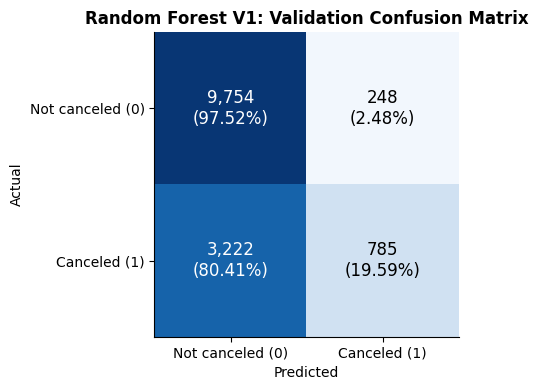

,FP,FN,FP_rate_pct,FN_rate_pct
Version,,,,
V0_Baseline,302,3091,3.02%,77.14%
V1_NoDomestic,248,3222,2.48%,80.41%


In [131]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import confusion_matrix

# Fit V1 on the full training sample
print("Training the V1 analysis model...")
rf_v1_analysis_model = clone(rf_v1_pipeline).fit(X_train_raw, y_train)

# Save predictions on the same validation sample
rf_v1_cases = X_valid_raw.reset_index(drop=True).copy()
rf_v1_cases["Actual"] = np.asarray(y_valid, dtype=int)
rf_v1_cases["Cancel_probability"] = rf_v1_analysis_model.predict_proba(X_valid_raw)[:, 1]
rf_v1_cases["Predicted"] = (rf_v1_cases["Cancel_probability"] >= 0.5).astype(int)

# Calculate counts and percentages within each actual class
rf_v1_cm = confusion_matrix(rf_v1_cases["Actual"], rf_v1_cases["Predicted"], labels=[0, 1])
rf_v1_cm_pct = rf_v1_cm / rf_v1_cm.sum(axis=1, keepdims=True)
rf_v1_tn, rf_v1_fp, rf_v1_fn, rf_v1_tp = rf_v1_cm.ravel()

# Plot the confusion matrix
fig, ax = plt.subplots(figsize=(6, 4))
ax.imshow(rf_v1_cm_pct, cmap="Blues", vmin=0, vmax=1)
for (i, j), count in np.ndenumerate(rf_v1_cm):
    ax.text(j, i, f"{count:,}\n({rf_v1_cm_pct[i, j]:.2%})",
            ha="center", va="center", fontsize=12,
            color="white" if rf_v1_cm_pct[i, j] > 0.5 else "black")
ax.set(xticks=[0, 1], yticks=[0, 1],
       xticklabels=["Not canceled (0)", "Canceled (1)"],
       yticklabels=["Not canceled (0)", "Canceled (1)"],
       xlabel="Predicted", ylabel="Actual",
       title="Random Forest V1: Validation Confusion Matrix")
fig.tight_layout()
plt.show()

# Compare validation errors between V0 and V1
rf_v1_error_summary = pd.DataFrame({
    "FP": [rf_v1_fp], "FN": [rf_v1_fn],
    "FP_rate_pct": [100 * rf_v1_fp / (rf_v1_tn + rf_v1_fp)],
    "FN_rate_pct": [100 * rf_v1_fn / (rf_v1_fn + rf_v1_tp)]
}, index=["V1_NoDomestic"])
rf_error_comparison = pd.concat([rf_error_summary, rf_v1_error_summary])
rf_error_comparison.index.name = "Version"
display(rf_error_comparison.style.format({
    "FP_rate_pct": "{:.2f}%", "FN_rate_pct": "{:.2f}%"
}))

In comparison, the false negative rate actually increases by 3%, meaning the model performs worse after removing this variable

### 13.7.6 Random Forest — V1: Feature Importance Comparison

Calculating V1 permutation importance...


,V0_AUC_drop,V1_AUC_drop,V1_Shuffle_SD
Feature,,,
country,0.02928,0.07502,0.00292
agent,0.06520,0.05573,0.00119
customer_type,0.01335,0.01639,0.00147
lead_time,0.01330,0.01227,0.00098
market_segment,0.01869,0.01202,0.00112
lead_time_log,0.01274,0.01165,0.00100
deposit_type,0.00719,0.00985,0.00045
hotel_market_segment,0.00827,0.00825,0.00093
lead_time_bucket,0.01026,0.00590,0.00062


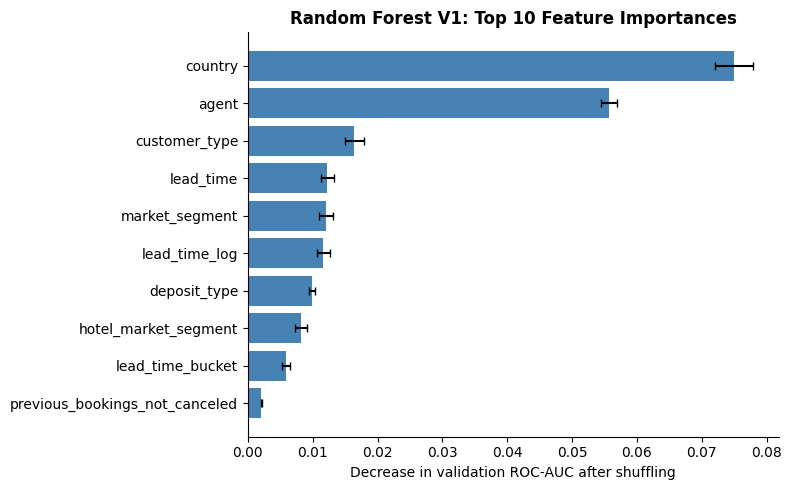

In [132]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance

# Prepare engineered features used by V1
rf_v1_prepare = rf_v1_analysis_model.named_steps["prepare"]
X_valid_rf_v1_features = rf_v1_prepare[0].transform(X_valid_raw).drop(columns=["is_domestic"])
rf_v1_feature_model = Pipeline([
    ("preprocessing", rf_v1_prepare[1]),
    ("model", rf_v1_analysis_model.named_steps["model"])
])

# Calculate permutation importance on the validation sample
print("Calculating V1 permutation importance...")
rf_v1_pi = permutation_importance(
    rf_v1_feature_model, X_valid_rf_v1_features, y_valid,
    scoring="roc_auc", n_repeats=5, random_state=67, n_jobs=1
)
rf_v1_importance = pd.DataFrame({
    "Feature": X_valid_rf_v1_features.columns,
    "AUC_drop": rf_v1_pi.importances_mean,
    "Shuffle_SD": rf_v1_pi.importances_std
}).sort_values("AUC_drop", ascending=False).reset_index(drop=True)

# Compare feature importance between V0 and V1
rf_v0_v1_importance = pd.concat({
    "V0_AUC_drop": rf_importance.set_index("Feature")["AUC_drop"],
    "V1_AUC_drop": rf_v1_importance.set_index("Feature")["AUC_drop"],
    "V1_Shuffle_SD": rf_v1_importance.set_index("Feature")["Shuffle_SD"]
}, axis=1).sort_values("V1_AUC_drop", ascending=False)
display(rf_v0_v1_importance.head(15).round(5))

# Plot the ten most important V1 features
top = rf_v1_importance.head(10).sort_values("AUC_drop")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top["Feature"], top["AUC_drop"], xerr=top["Shuffle_SD"],
        color="steelblue", capsize=3)
ax.axvline(0, color="gray", linewidth=0.8)
ax.set(xlabel="Decrease in validation ROC-AUC after shuffling",
       title="Random Forest V1: Top 10 Feature Importances")
fig.tight_layout()
plt.show()

After removing is_domestic, V1 relies more on country

### 13.7.7 Random Forest — V2: Feature Engineering and Cross-Validation

V2: estimated_stay_value = adr × total_nights  

In [133]:
import pandas as pd
from sklearn.base import clone
from IPython.display import display

# Add an interaction between room rate and length of stay
class BookingFeatureEngineerRFV2(BookingFeatureEngineer):
    def transform(self, X):
        d = super().transform(X)
        d["estimated_stay_value"] = d["adr"] * d["total_nights"]
        return d

# Create V2 from V1
rf_v2_pipeline = clone(rf_v1_pipeline)
rf_v2_prepare = rf_v2_pipeline.named_steps["prepare"]
rf_v2_prepare.set_params(feature_engineering=BookingFeatureEngineerRFV2(
    drop_deposit_type=rf_v2_prepare[0].drop_deposit_type
))

# Include the new feature in the capped numeric preprocessing branch
rf_v2_preprocessor = rf_v2_prepare[1]
rf_v2_preprocessor.set_params(transformers=[
    (name, transformer, list(columns) + ["estimated_stay_value"]
     if name == "capped_num" else columns)
    for name, transformer, columns in rf_v2_preprocessor.transformers
])

# Evaluate V2 using the same five chronological folds
rf_v2_cv_scores, rf_v2_cv_summary = evaluate_model(
    "Random Forest V2 (stay value)", rf_v2_pipeline
)

# Compare all three versions
rf_three_versions = pd.concat({
    "V0_Baseline": rf_cv_summary,
    "V1_NoDomestic": rf_v1_cv_summary,
    "V2_StayValue": rf_v2_cv_summary
}, axis=1)
display(rf_three_versions.round(4))

Random Forest V2 (stay value): fold 1/5 completed
Random Forest V2 (stay value): fold 2/5 completed
Random Forest V2 (stay value): fold 3/5 completed
Random Forest V2 (stay value): fold 4/5 completed
Random Forest V2 (stay value): fold 5/5 completed


,ROC_AUC,Precision,Recall,F1,Brier
Fold,,,,,
1,0.9369,0.8423,0.6360,0.7248,0.0645
2,0.7215,0.7551,0.1661,0.2723,0.1499
3,0.8140,0.7204,0.2020,0.3155,0.1460
4,0.7596,0.7563,0.1240,0.2130,0.1799
5,0.8173,0.8203,0.1082,0.1912,0.1602


,mean,std
ROC_AUC,0.8099,0.0815
Precision,0.7789,0.0506
Recall,0.2473,0.2204
F1,0.3434,0.2188
Brier,0.1401,0.0443


V0_Baseline         V1_NoDomestic         V2_StayValue        
                 mean     std          mean     std         mean     std
ROC_AUC        0.7998  0.0846        0.8111  0.0782       0.8099  0.0815
Precision      0.7560  0.0605        0.7750  0.0539       0.7789  0.0506
Recall         0.2610  0.2212        0.2448  0.2116       0.2473  0.2204
F1             0.3578  0.2147        0.3428  0.2130       0.3434  0.2188
Brier          0.1427  0.0466        0.1410  0.0446       0.1401  0.0443

There is no major change

### 13.7.8 Random Forest — V2: Validation Error Analysis

Training the V2 analysis model...


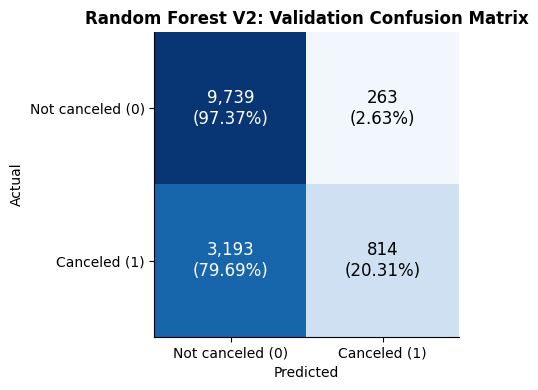

,FP,FN,FP_rate_pct,FN_rate_pct,Total_errors
Version,,,,,
V0_Baseline,302,3091,3.02%,77.14%,3393
V1_NoDomestic,248,3222,2.48%,80.41%,3470
V2_StayValue,263,3193,2.63%,79.69%,3456


In [134]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import confusion_matrix

# Fit V2 on the full training sample
print("Training the V2 analysis model...")
rf_v2_analysis_model = clone(rf_v2_pipeline).fit(X_train_raw, y_train)

# Save predictions on the same validation sample
rf_v2_cases = X_valid_raw.reset_index(drop=True).copy()
rf_v2_cases["Actual"] = np.asarray(y_valid, dtype=int)
rf_v2_cases["Cancel_probability"] = rf_v2_analysis_model.predict_proba(X_valid_raw)[:, 1]
rf_v2_cases["Predicted"] = (rf_v2_cases["Cancel_probability"] >= 0.5).astype(int)

# Calculate counts and percentages within each actual class
rf_v2_cm = confusion_matrix(rf_v2_cases["Actual"], rf_v2_cases["Predicted"], labels=[0, 1])
rf_v2_cm_pct = rf_v2_cm / rf_v2_cm.sum(axis=1, keepdims=True)
rf_v2_tn, rf_v2_fp, rf_v2_fn, rf_v2_tp = rf_v2_cm.ravel()

# Plot the confusion matrix
fig, ax = plt.subplots(figsize=(6, 4))
ax.imshow(rf_v2_cm_pct, cmap="Blues", vmin=0, vmax=1)
for (i, j), count in np.ndenumerate(rf_v2_cm):
    ax.text(j, i, f"{count:,}\n({rf_v2_cm_pct[i, j]:.2%})",
            ha="center", va="center", fontsize=12,
            color="white" if rf_v2_cm_pct[i, j] > 0.5 else "black")
ax.set(xticks=[0, 1], yticks=[0, 1],
       xticklabels=["Not canceled (0)", "Canceled (1)"],
       yticklabels=["Not canceled (0)", "Canceled (1)"],
       xlabel="Predicted", ylabel="Actual",
       title="Random Forest V2: Validation Confusion Matrix")
fig.tight_layout()
plt.show()

# Compare validation errors across all three versions
rf_v2_error_summary = pd.DataFrame({
    "FP": [rf_v2_fp], "FN": [rf_v2_fn],
    "FP_rate_pct": [100 * rf_v2_fp / (rf_v2_tn + rf_v2_fp)],
    "FN_rate_pct": [100 * rf_v2_fn / (rf_v2_fn + rf_v2_tp)]
}, index=["V2_StayValue"])
rf_all_error_comparison = pd.concat([
    rf_error_summary, rf_v1_error_summary, rf_v2_error_summary
])
rf_all_error_comparison.index.name = "Version"
rf_all_error_comparison["Total_errors"] = (
    rf_all_error_comparison["FP"] + rf_all_error_comparison["FN"]
)
display(rf_all_error_comparison.style.format({
    "FP_rate_pct": "{:.2f}%", "FN_rate_pct": "{:.2f}%"
}))

False positives decrease slightly, but false negatives remain high

### 13.7.9 Random Forest — V2: Permutation Feature Importance

Calculating V2 permutation importance...


,Feature,AUC_drop,Shuffle_SD
Rank,,,
1,country,0.07562,0.00244
2,agent,0.05926,0.00143
3,market_segment,0.01713,0.00110
4,customer_type,0.01419,0.00136
5,lead_time,0.01172,0.00087
6,lead_time_log,0.01157,0.00118
7,deposit_type,0.00956,0.00040
8,lead_time_bucket,0.00611,0.00057
9,hotel_market_segment,0.00560,0.00095



Importance of the new feature:


,Feature,AUC_drop,Shuffle_SD
Rank,,,
16,estimated_stay_value,0.00063,0.00031


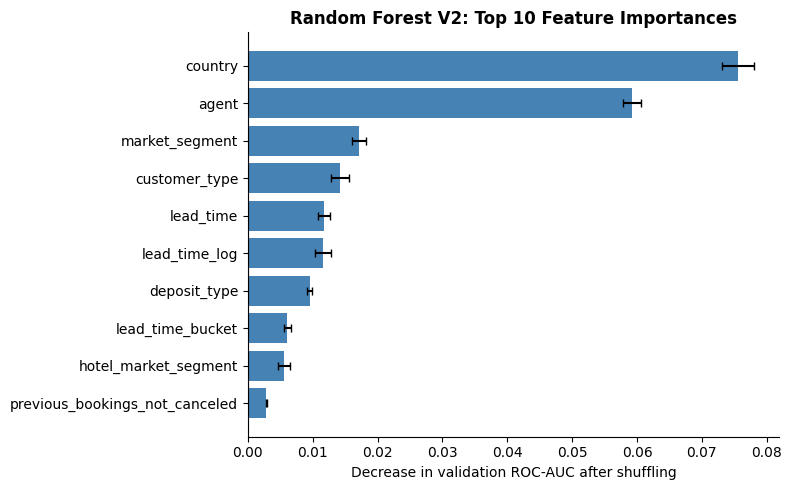

In [135]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance

# Prepare engineered features used by V2
rf_v2_prepare = rf_v2_analysis_model.named_steps["prepare"]
X_valid_rf_v2_features = rf_v2_prepare[0].transform(X_valid_raw).drop(columns=["is_domestic"])
rf_v2_feature_model = Pipeline([
    ("preprocessing", rf_v2_prepare[1]),
    ("model", rf_v2_analysis_model.named_steps["model"])
])

# Calculate permutation importance on the validation sample
print("Calculating V2 permutation importance...")
rf_v2_pi = permutation_importance(
    rf_v2_feature_model, X_valid_rf_v2_features, y_valid,
    scoring="roc_auc", n_repeats=5, random_state=67, n_jobs=1
)
rf_v2_importance = pd.DataFrame({
    "Feature": X_valid_rf_v2_features.columns,
    "AUC_drop": rf_v2_pi.importances_mean,
    "Shuffle_SD": rf_v2_pi.importances_std
}).sort_values("AUC_drop", ascending=False).reset_index(drop=True)
rf_v2_importance.index = range(1, len(rf_v2_importance) + 1)
rf_v2_importance.index.name = "Rank"
display(rf_v2_importance.head(15).round(5))

# Display the new feature even if it falls outside the top fifteen
print("\nImportance of the new feature:")
display(rf_v2_importance.loc[
    rf_v2_importance["Feature"] == "estimated_stay_value"
].round(5))

# Plot the ten most important V2 features
top = rf_v2_importance.head(10).sort_values("AUC_drop")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top["Feature"], top["AUC_drop"], xerr=top["Shuffle_SD"],
        color="steelblue", capsize=3)
ax.axvline(0, color="gray", linewidth=0.8)
ax.set(xlabel="Decrease in validation ROC-AUC after shuffling",
       title="Random Forest V2: Top 10 Feature Importances")
fig.tight_layout()
plt.show()

### 13.7.10 Random Forest — Comparison of V0, V1, and V2

Five-fold cross-validation: mean and standard deviation


V0_Baseline         V1_NoDomestic         V2_StayValue        
                 mean     std          mean     std         mean     std
ROC_AUC        0.7998  0.0846        0.8111  0.0782       0.8099  0.0815
Precision      0.7560  0.0605        0.7750  0.0539       0.7789  0.0506
Recall         0.2610  0.2212        0.2448  0.2116       0.2473  0.2204
F1             0.3578  0.2147        0.3428  0.2130       0.3434  0.2188
Brier          0.1427  0.0466        0.1410  0.0446       0.1401  0.0443


Fixed validation set: errors at threshold 0.5


,FP,FN,FP_rate_pct,FN_rate_pct,Total_errors
Version,,,,,
V0_Baseline,302,3091,3.02%,77.14%,3393
V1_NoDomestic,248,3222,2.48%,80.41%,3470
V2_StayValue,263,3193,2.63%,79.69%,3456


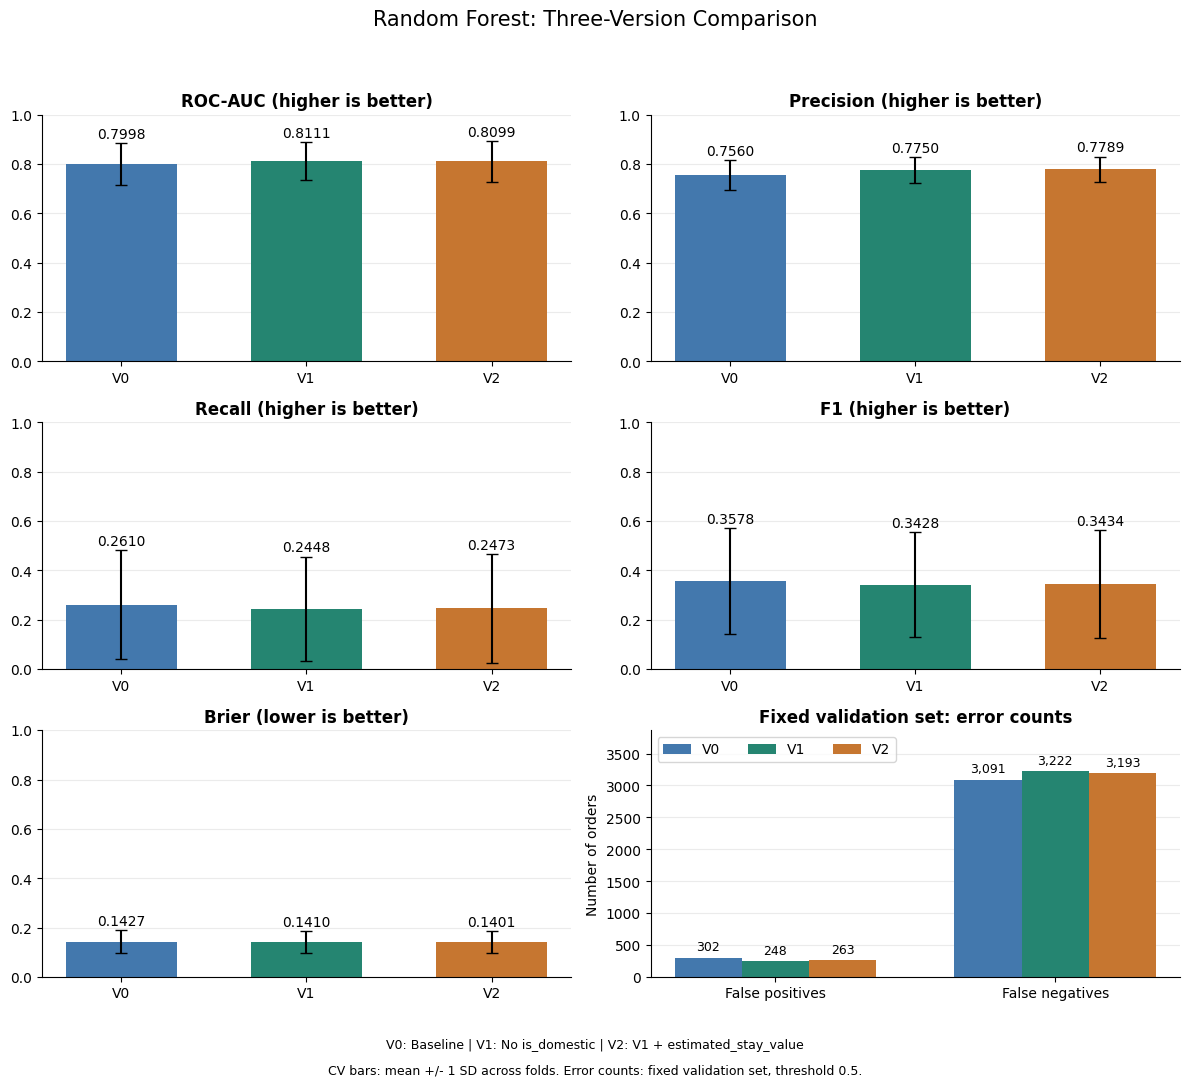

In [136]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Check that the three-version results are available
required = ["rf_three_versions", "rf_all_error_comparison"]
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError("Run the previous evaluation cells first. Missing: " + ", ".join(missing))

# Display cross-validation scores and fixed-validation errors
print("Five-fold cross-validation: mean and standard deviation")
display(rf_three_versions.round(4))
print("\nFixed validation set: errors at threshold 0.5")
rf_error_display = rf_all_error_comparison.copy()
for column in ["FP_rate_pct", "FN_rate_pct"]:
    rf_error_display[column] = rf_error_display[column].map(lambda value: f"{value:.2f}%")
display(rf_error_display)

# Plot the five cross-validation metrics
versions = ["V0_Baseline", "V1_NoDomestic", "V2_StayValue"]
labels = ["V0", "V1", "V2"]
colors = ["#4378ad", "#258571", "#c67630"]
metrics = ["ROC_AUC", "Precision", "Recall", "F1", "Brier"]
fig, axes = plt.subplots(3, 2, figsize=(12, 11))
for ax, metric in zip(axes.ravel(), metrics):
    means = np.array([rf_three_versions.loc[metric, (v, "mean")] for v in versions])
    stds = np.array([rf_three_versions.loc[metric, (v, "std")] for v in versions])
    ax.bar(labels, means, yerr=stds, color=colors, capsize=4, width=0.6)
    for i, (mean, std) in enumerate(zip(means, stds)):
        ax.text(i, min(mean + std + 0.02, 0.96), f"{mean:.4f}", ha="center", fontsize=10)
    direction = "lower is better" if metric == "Brier" else "higher is better"
    ax.set(title=f"{metric.replace('_', '-')} ({direction})", ylim=(0, 1))
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.25)

# Compare false positives and false negatives on the same validation sample
ax = axes.ravel()[5]
x, width = np.arange(2), 0.24
for i, version in enumerate(versions):
    counts = rf_all_error_comparison.loc[version, ["FP", "FN"]].to_numpy(dtype=float)
    bars = ax.bar(x + (i - 1) * width, counts, width, color=colors[i], label=labels[i])
    ax.bar_label(bars, labels=[f"{value:,.0f}" for value in counts], padding=3, fontsize=9)
ax.set(xticks=x, xticklabels=["False positives", "False negatives"],
       ylabel="Number of orders", title="Fixed validation set: error counts")
ax.set_ylim(0, max(1, rf_all_error_comparison[["FP", "FN"]].to_numpy().max() * 1.2))
ax.legend(ncol=3)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)

# Add version definitions and explain the error bars
fig.suptitle("Random Forest: Three-Version Comparison", fontsize=15)
fig.text(0.5, 0.035, "V0: Baseline | V1: No is_domestic | V2: V1 + estimated_stay_value",
         ha="center", fontsize=9)
fig.text(0.5, 0.012, "CV bars: mean +/- 1 SD across folds. Error counts: fixed validation set, threshold 0.5.",
         ha="center", fontsize=9)
fig.tight_layout(rect=[0, 0.065, 1, 0.95])
plt.show()

There is little difference

## 13.8 Gaussian Naive Bayes

### Gaussian Naive Bayes — Step 1: V0 Cross-Validation

In [137]:
from scipy import sparse
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.naive_bayes import GaussianNB

# Convert the encoded sparse matrix to a dense array
def gnb_to_dense(X):
    return X.toarray() if sparse.issparse(X) else X

# Build the Gaussian Naive Bayes baseline pipeline
gnb_pipeline = Pipeline([
    ("prepare", clone(prepare_pipeline)),
    ("to_dense", FunctionTransformer(gnb_to_dense, accept_sparse=True)),
    ("model", GaussianNB())
])

# Evaluate using the shared five chronological folds
gnb_cv_scores, gnb_cv_summary = evaluate_model(
    "Gaussian Naive Bayes", gnb_pipeline
)

Gaussian Naive Bayes: fold 1/5 completed
Gaussian Naive Bayes: fold 2/5 completed
Gaussian Naive Bayes: fold 3/5 completed
Gaussian Naive Bayes: fold 4/5 completed
Gaussian Naive Bayes: fold 5/5 completed


,ROC_AUC,Precision,Recall,F1,Brier
Fold,,,,,
1,0.8979,0.3709,0.9167,0.5282,0.2620
2,0.6145,0.2660,0.4517,0.3348,0.3677
3,0.6930,0.4020,0.6631,0.5006,0.3238
4,0.6754,0.3934,0.7512,0.5164,0.4058
5,0.7229,0.4065,0.8016,0.5394,0.3739


,mean,std
ROC_AUC,0.7207,0.1067
Precision,0.3678,0.0585
Recall,0.7169,0.1743
F1,0.4839,0.0846
Brier,0.3466,0.0556


Recall is high, but precision is low.

### Gaussian Naive Bayes — Step 2: V0 Feature Importance

Fitting the GNB analysis model...
Calculating permutation importance...


,Feature,AUC_drop,Shuffle_SD
0,agent,0.05513,0.00189
1,country,0.01953,0.00142
2,hotel_market_segment,0.01883,0.00059
3,deposit_type,0.01519,0.00084
4,lead_time_bucket,0.01500,0.00067
5,is_repeated_guest,0.00920,0.00100
6,market_segment,0.00893,0.00029
7,previous_bookings_not_canceled,0.00787,0.00174
8,customer_type,0.00611,0.00120
9,lead_time_log,0.00527,0.00023


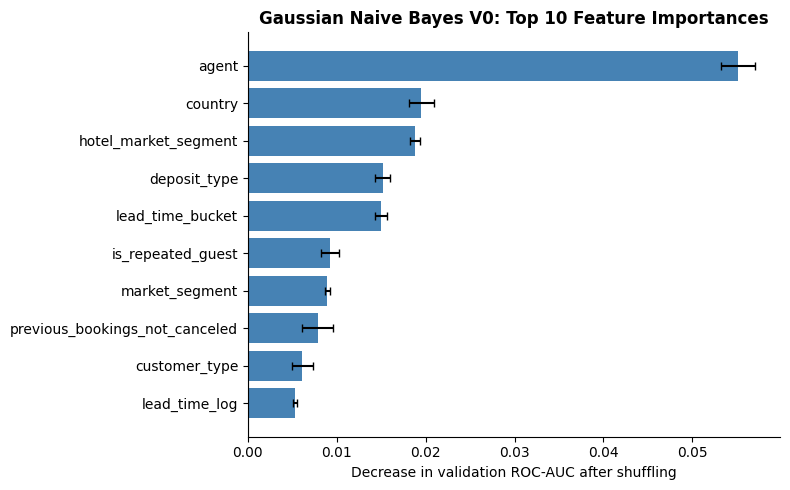

In [138]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance

# Fit an analysis model on the full training sample
print("Fitting the GNB analysis model...")
gnb_analysis_model = clone(gnb_pipeline).fit(X_train_raw, y_train)

# Prepare engineered features and retain the dense conversion
gnb_prepare = gnb_analysis_model.named_steps["prepare"]
X_valid_gnb_features = gnb_prepare[0].transform(X_valid_raw)
gnb_feature_model = Pipeline([
    ("preprocessing", gnb_prepare[1]),
    ("to_dense", gnb_analysis_model.named_steps["to_dense"]),
    ("model", gnb_analysis_model.named_steps["model"])
])

# Calculate permutation importance on the validation sample
print("Calculating permutation importance...")
gnb_pi = permutation_importance(
    gnb_feature_model, X_valid_gnb_features, y_valid,
    scoring="roc_auc", n_repeats=5, random_state=67, n_jobs=1
)
gnb_importance = pd.DataFrame({
    "Feature": X_valid_gnb_features.columns,
    "AUC_drop": gnb_pi.importances_mean,
    "Shuffle_SD": gnb_pi.importances_std
}).sort_values("AUC_drop", ascending=False).reset_index(drop=True)
display(gnb_importance.head(15).round(5))

# Plot the ten most important features
top = gnb_importance.head(10).sort_values("AUC_drop")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top["Feature"], top["AUC_drop"], xerr=top["Shuffle_SD"],
        color="steelblue", capsize=3)
ax.axvline(0, color="gray", linewidth=0.8)
ax.set(xlabel="Decrease in validation ROC-AUC after shuffling",
       title="Gaussian Naive Bayes V0: Top 10 Feature Importances")
fig.tight_layout()
plt.show()

### Gaussian Naive Bayes — Step 3: Feature Experiments

In [139]:
import numpy as np
import pandas as pd
from IPython.display import display
from IPython.utils.capture import capture_output
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix
from sklearn.inspection import permutation_importance

# Add the same stay-value feature used in the other models
class StayValueFeatureEngineer(BookingFeatureEngineer):
    def transform(self, X):
        d = super().transform(X)
        d["estimated_stay_value"] = d["adr"] * d["total_nights"]
        return d

def run_feature_experiments(base_pipeline, model_name, v0_scores=None,
                            v0_model=None, v0_importance=None):
    # Build V1 and V2 without modifying the baseline
    v1 = clone(base_pipeline)
    pre1 = v1.named_steps["prepare"][1]
    pre1.set_params(transformers=[
        (name, step, [c for c in cols if c != "is_domestic"])
        for name, step, cols in pre1.transformers
    ])
    v2 = clone(v1)
    prep2 = v2.named_steps["prepare"]
    prep2.set_params(feature_engineering=StayValueFeatureEngineer(
        drop_deposit_type=prep2[0].drop_deposit_type))
    pre2 = prep2[1]
    pre2.set_params(transformers=[
        (name, step, list(cols) + ["estimated_stay_value"] if name == "capped_num" else cols)
        for name, step, cols in pre2.transformers
    ])
    pipelines = {"V0_Baseline": base_pipeline, "V1_NoDomestic": v1, "V2_StayValue": v2}
    metrics = ["ROC_AUC", "Precision", "Recall", "F1", "Brier"]
    results = {}

    # Evaluate every version and reuse completed V0 calculations
    for version, pipeline in pipelines.items():
        print(f"\n{model_name} — {version}", flush=True)
        scores = v0_scores if version == "V0_Baseline" else None
        model = v0_model if version == "V0_Baseline" else None
        importance = v0_importance if version == "V0_Baseline" else None
        if scores is None:
            print("Running five-fold cross-validation...", flush=True)
            with capture_output() as captured:
                scores, _ = evaluate_model(f"{model_name} {version}", pipeline)
            if captured.stderr:
                print(captured.stderr)
        if model is None:
            print("Fitting the validation-analysis model...", flush=True)
            model = clone(pipeline).fit(X_train_raw, y_train)

        cases = X_valid_raw.reset_index(drop=True).copy()
        cases["Actual"] = np.asarray(y_valid, dtype=int)
        cases["Cancel_probability"] = model.predict_proba(X_valid_raw)[:, 1]
        cases["Predicted"] = (cases["Cancel_probability"] >= 0.5).astype(int)
        cm = confusion_matrix(cases["Actual"], cases["Predicted"], labels=[0, 1])
        tn, fp, fn, tp = cm.ravel()

        if importance is None:
            print("Calculating permutation importance...", flush=True)
            prep = model.named_steps["prepare"]
            features = prep[0].transform(X_valid_raw)
            if version != "V0_Baseline":
                features = features.drop(columns=["is_domestic"], errors="ignore")
            feature_model = Pipeline([("preprocessing", prep[1])] + model.steps[1:])
            pi = permutation_importance(
                feature_model, features, y_valid, scoring="roc_auc",
                n_repeats=5, random_state=67, n_jobs=1
            )
            importance = pd.DataFrame({
                "Feature": features.columns,
                "AUC_drop": pi.importances_mean,
                "Shuffle_SD": pi.importances_std
            }).sort_values("AUC_drop", ascending=False).reset_index(drop=True)

        results[version] = {
            "pipeline": pipeline, "cv_scores": scores,
            "cv_summary": scores[metrics].agg(["mean", "std"]).T,
            "analysis_model": model, "importance": importance, "cases": cases, "cm": cm,
            "errors": {
                "FP": fp, "FN": fn, "FP_rate_pct": 100 * fp / (tn + fp),
                "FN_rate_pct": 100 * fn / (fn + tp), "Total_errors": fp + fn
            }
        }
        print("Completed.", flush=True)
    return results

# Complete the remaining experiments and reuse existing V0 results
gnb_results = run_feature_experiments(
    gnb_pipeline, "Gaussian Naive Bayes", gnb_cv_scores,
    globals().get("gnb_analysis_model"), globals().get("gnb_importance")
)


Gaussian Naive Bayes — V0_Baseline
Completed.

Gaussian Naive Bayes — V1_NoDomestic
Running five-fold cross-validation...
Fitting the validation-analysis model...
Calculating permutation importance...
Completed.

Gaussian Naive Bayes — V2_StayValue
Running five-fold cross-validation...
Fitting the validation-analysis model...
Calculating permutation importance...
Completed.


### Gaussian Naive Bayes — Step 4: Summary Tables and Plots


Five-fold cross-validation: mean and standard deviation


V0_Baseline         V1_NoDomestic         V2_StayValue        
                 mean     std          mean     std         mean     std
ROC_AUC        0.7207  0.1067        0.7208  0.1059       0.7213  0.1056
Precision      0.3678  0.0585        0.3675  0.0559       0.3676  0.0557
Recall         0.7169  0.1743        0.7190  0.1720       0.7190  0.1717
F1             0.4839  0.0846        0.4847  0.0845       0.4848  0.0844
Brier          0.3466  0.0556        0.3468  0.0603       0.3469  0.0609


Fixed validation set: threshold 0.5


,FP,FN,FP_rate_pct,FN_rate_pct,Total_errors
Version,,,,,
V0_Baseline,3540,1169,35.39%,29.17%,4709
V1_NoDomestic,3576,1156,35.75%,28.85%,4732
V2_StayValue,3554,1162,35.53%,29.00%,4716



V2: importance of the new feature


,Feature,AUC_drop,Shuffle_SD
20,estimated_stay_value,0.00052,0.00009


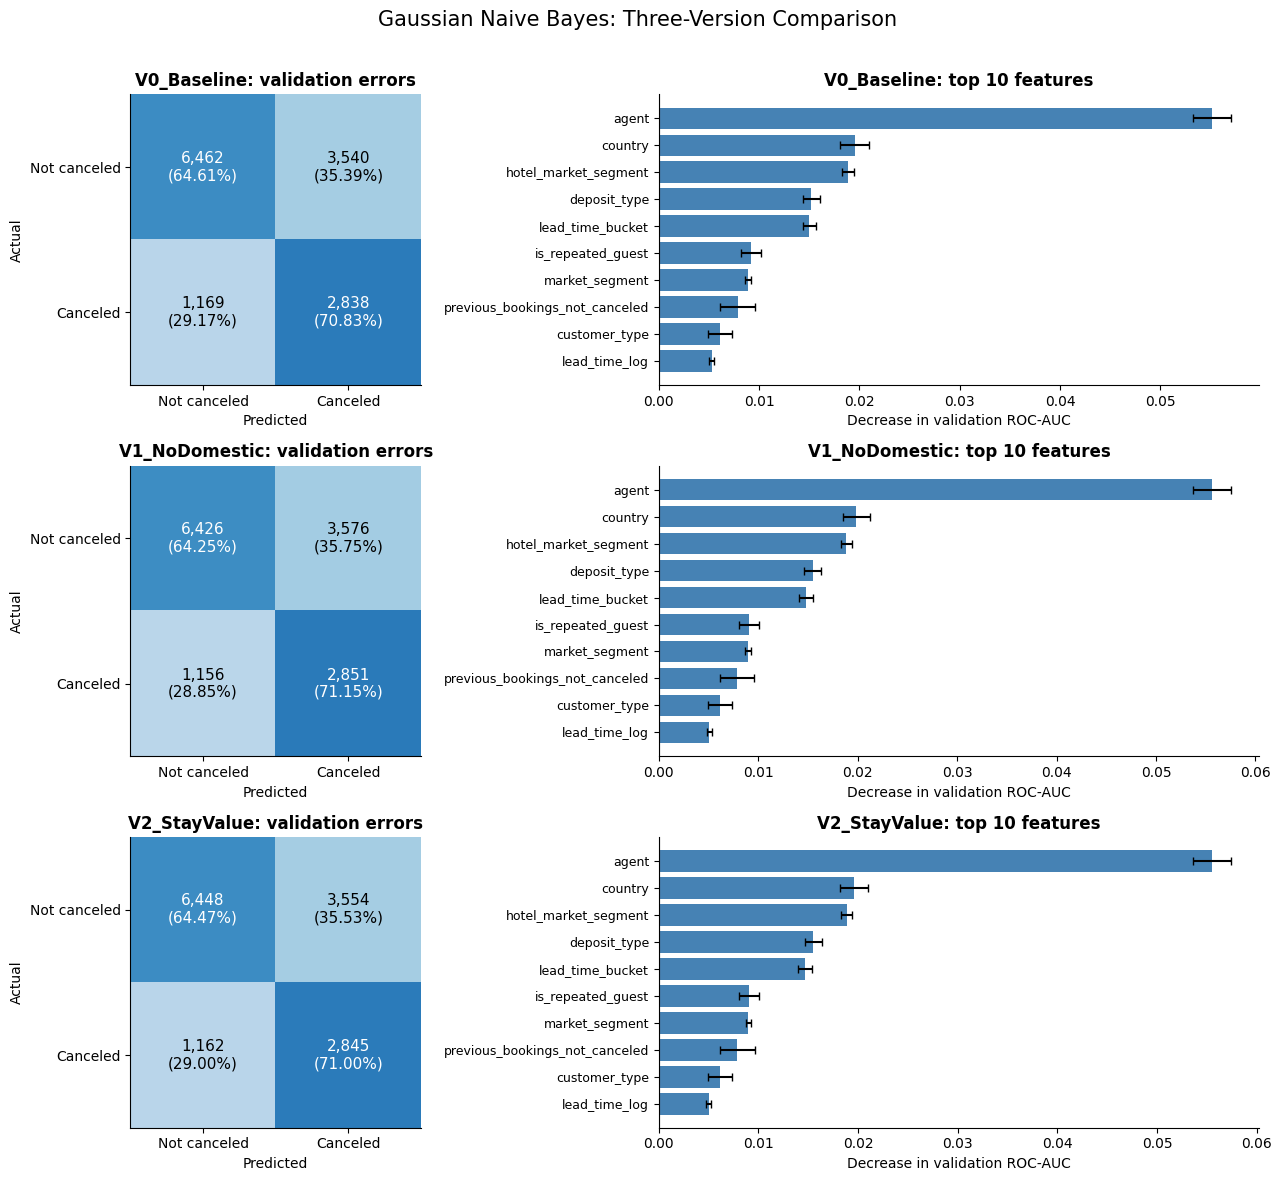

In [140]:
import matplotlib.pyplot as plt

def summarize_feature_experiments(results, model_name):
    # Display the three-version performance and error summaries
    comparison = pd.concat({v: r["cv_summary"] for v, r in results.items()}, axis=1)
    errors = pd.DataFrame([r["errors"] for r in results.values()], index=list(results))
    errors.index.name = "Version"
    print("\nFive-fold cross-validation: mean and standard deviation")
    display(comparison.round(4))
    error_display = errors.copy()
    for column in ["FP_rate_pct", "FN_rate_pct"]:
        error_display[column] = error_display[column].map(lambda value: f"{value:.2f}%")
    print("\nFixed validation set: threshold 0.5")
    display(error_display)
    print("\nV2: importance of the new feature")
    imp2 = results["V2_StayValue"]["importance"]
    display(imp2.loc[imp2["Feature"] == "estimated_stay_value"].round(5))

    # Compare confusion matrices and feature importance in one figure
    fig, axes = plt.subplots(3, 2, figsize=(13, 12),
                             gridspec_kw={"width_ratios": [1, 1.5]})
    for row, (version, record) in enumerate(results.items()):
        cm = record["cm"]
        pct = cm / cm.sum(axis=1, keepdims=True)
        ax = axes[row, 0]
        ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
        for (i, j), count in np.ndenumerate(cm):
            ax.text(j, i, f"{count:,}\n({pct[i, j]:.2%})",
                    ha="center", va="center", fontsize=11,
                    color="white" if pct[i, j] > 0.5 else "black")
        ax.set(xticks=[0, 1], yticks=[0, 1],
               xticklabels=["Not canceled", "Canceled"],
               yticklabels=["Not canceled", "Canceled"],
               xlabel="Predicted", ylabel="Actual", title=f"{version}: validation errors")
        top = record["importance"].head(10).sort_values("AUC_drop")
        ax = axes[row, 1]
        ax.barh(top["Feature"], top["AUC_drop"], xerr=top["Shuffle_SD"],
                color="steelblue", capsize=3)
        ax.axvline(0, color="gray", linewidth=0.8)
        ax.tick_params(axis="y", labelsize=9)
        ax.set(xlabel="Decrease in validation ROC-AUC", title=f"{version}: top 10 features")
    fig.suptitle(f"{model_name}: Three-Version Comparison", fontsize=15)
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()
    return comparison, errors

# Display all GNB comparisons in one call
gnb_three_versions, gnb_all_error_comparison = summarize_feature_experiments(
    gnb_results, "Gaussian Naive Bayes"
)

We compared three Gaussian Naive Bayes versions using the same five chronological folds. V0 used the baseline features, V1 removed is_domestic, and V2 added estimated_stay_value to V1. Their mean ROC-AUC scores were 0.7207, 0.7208, and 0.7213, respectively, with standard deviations of approximately 0.106. The feature changes produced very small performance differences, while variation across time periods remained substantial.

On the fixed validation set at a threshold of 0.5, false positive rates ranged from 35.39% to 35.75%, and false negative rates ranged from 28.85% to 29.17%. False positives were the main source of errors. Total errors were 4,709 for V0, 4,732 for V1, and 4,716 for V2. V0 also had the lowest mean Brier score, making it a reasonable default GNB candidate when considering total errors and probability prediction loss. V1 slightly reduced false negatives but increased false positives, while V2 provided no consistent overall improvement.

Permutation importance for V2 identified agent, country, and hotel_market_segment as influential features. The new estimated_stay_value feature ranked 21st, with an average AUC decrease of approximately 0.00052, suggesting limited additional contribution to this model. Payment status, detailed cancellation terms, and customer confirmation information available at prediction time could potentially help reduce false positives.

## 13.9 Neural Net (MLP) 

### Neural Net (MLP) — Step 1: V0 Cross-Validation

In [141]:
from scipy import sparse
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.neural_network import MLPClassifier

# Use a dense representation consistent with notebook 03
def mlp_to_dense(X):
    return X.toarray() if sparse.issparse(X) else X

# Build the MLP baseline pipeline
mlp_pipeline = Pipeline([
    ("prepare", clone(prepare_pipeline)),
    ("to_dense", FunctionTransformer(mlp_to_dense, accept_sparse=True)),
    ("model", MLPClassifier(
        hidden_layer_sizes=(48,), max_iter=90,
        early_stopping=True, random_state=67
    ))
])

# Evaluate using the shared five chronological folds
mlp_cv_scores, mlp_cv_summary = evaluate_model(
    "Neural Net (MLP)", mlp_pipeline
)

Neural Net (MLP): fold 1/5 completed
Neural Net (MLP): fold 2/5 completed
Neural Net (MLP): fold 3/5 completed
Neural Net (MLP): fold 4/5 completed
Neural Net (MLP): fold 5/5 completed


,ROC_AUC,Precision,Recall,F1,Brier
Fold,,,,,
1,0.9360,0.8761,0.5682,0.6894,0.0633
2,0.7683,0.6568,0.1733,0.2743,0.1565
3,0.7935,0.5989,0.3328,0.4278,0.1579
4,0.7466,0.7198,0.1444,0.2405,0.2030
5,0.8204,0.6963,0.2512,0.3692,0.1656


,mean,std
ROC_AUC,0.8130,0.0741
Precision,0.7096,0.1037
Recall,0.2940,0.1699
F1,0.4002,0.1780
Brier,0.1493,0.0516


### Neural Net (MLP) — Step 2: V0 Feature Importance and Error Analysis

Fitting the MLP analysis model...
Calculating permutation importance...


,Feature,AUC_drop,Shuffle_SD
0,agent,0.11429,0.00353
1,lead_time_log,0.05571,0.00205
2,is_domestic,0.05246,0.00241
3,country,0.01835,0.00193
4,customer_type,0.01602,0.00096
5,has_history,0.01159,0.00045
6,is_repeated_guest,0.01039,0.00100
7,market_segment,0.00794,0.00093
8,hotel_market_segment,0.00789,0.00065
9,lead_time_bucket,0.00665,0.00029


,FP,FN,FP_rate_pct,FN_rate_pct,Total_errors
V0_Baseline,1081,2235,10.81%,55.78%,3316


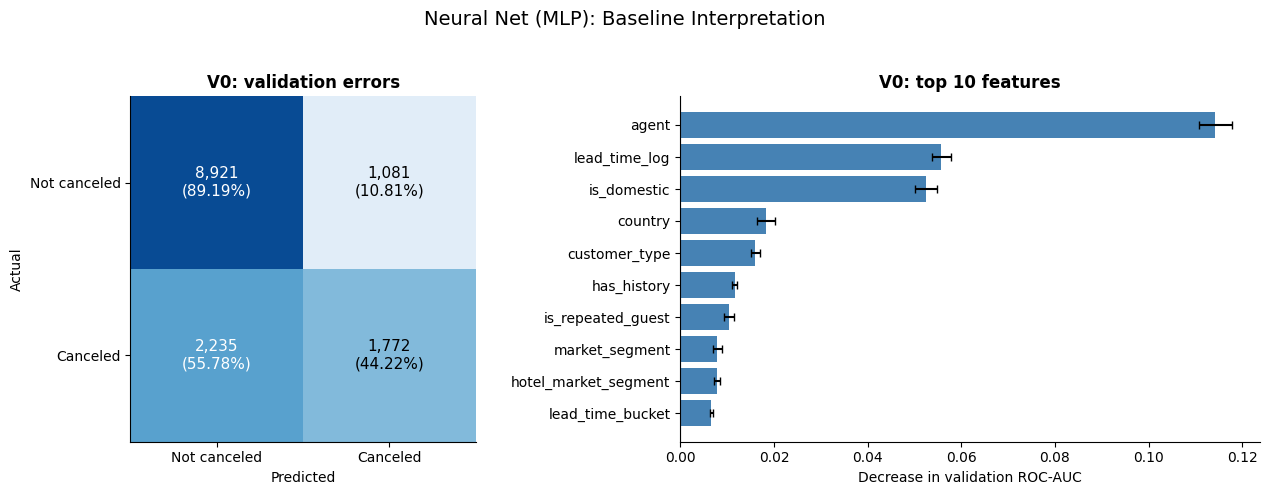

In [142]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import confusion_matrix

# Fit the V0 analysis model on the full training sample
print("Fitting the MLP analysis model...")
mlp_analysis_model = clone(mlp_pipeline).fit(X_train_raw, y_train)

# Calculate feature importance before one-hot encoding
mlp_prepare = mlp_analysis_model.named_steps["prepare"]
X_valid_mlp_features = mlp_prepare[0].transform(X_valid_raw)
mlp_feature_model = Pipeline(
    [("preprocessing", mlp_prepare[1])] + mlp_analysis_model.steps[1:]
)
print("Calculating permutation importance...")
mlp_pi = permutation_importance(
    mlp_feature_model, X_valid_mlp_features, y_valid,
    scoring="roc_auc", n_repeats=5, random_state=67, n_jobs=1
)
mlp_importance = pd.DataFrame({
    "Feature": X_valid_mlp_features.columns,
    "AUC_drop": mlp_pi.importances_mean,
    "Shuffle_SD": mlp_pi.importances_std
}).sort_values("AUC_drop", ascending=False).reset_index(drop=True)
display(mlp_importance.head(15).round(5))

# Calculate validation errors at threshold 0.5
mlp_cases = X_valid_raw.reset_index(drop=True).copy()
mlp_cases["Actual"] = np.asarray(y_valid, dtype=int)
mlp_cases["Cancel_probability"] = mlp_analysis_model.predict_proba(X_valid_raw)[:, 1]
mlp_cases["Predicted"] = (mlp_cases["Cancel_probability"] >= 0.5).astype(int)
mlp_cm = confusion_matrix(mlp_cases["Actual"], mlp_cases["Predicted"], labels=[0, 1])
mlp_cm_pct = mlp_cm / mlp_cm.sum(axis=1, keepdims=True)
tn, fp, fn, tp = mlp_cm.ravel()
mlp_error_summary = pd.DataFrame({
    "FP": [fp], "FN": [fn],
    "FP_rate_pct": [100 * fp / (tn + fp)],
    "FN_rate_pct": [100 * fn / (fn + tp)],
    "Total_errors": [fp + fn]
}, index=["V0_Baseline"])
error_display = mlp_error_summary.copy()
for column in ["FP_rate_pct", "FN_rate_pct"]:
    error_display[column] = error_display[column].map(lambda value: f"{value:.2f}%")
display(error_display)

# Plot validation errors and feature importance together
fig, axes = plt.subplots(1, 2, figsize=(13, 5),
                         gridspec_kw={"width_ratios": [1, 1.5]})
ax = axes[0]
ax.imshow(mlp_cm_pct, cmap="Blues", vmin=0, vmax=1)
for (i, j), count in np.ndenumerate(mlp_cm):
    ax.text(j, i, f"{count:,}\n({mlp_cm_pct[i, j]:.2%})",
            ha="center", va="center", fontsize=11,
            color="white" if mlp_cm_pct[i, j] > 0.5 else "black")
ax.set(xticks=[0, 1], yticks=[0, 1],
       xticklabels=["Not canceled", "Canceled"],
       yticklabels=["Not canceled", "Canceled"],
       xlabel="Predicted", ylabel="Actual", title="V0: validation errors")
top = mlp_importance.head(10).sort_values("AUC_drop")
axes[1].barh(top["Feature"], top["AUC_drop"], xerr=top["Shuffle_SD"],
             color="steelblue", capsize=3)
axes[1].axvline(0, color="gray", linewidth=0.8)
axes[1].set(xlabel="Decrease in validation ROC-AUC", title="V0: top 10 features")
fig.suptitle("Neural Net (MLP): Baseline Interpretation", fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

### Neural Net (MLP) — Step 3: V1 and V2 Feature Experiments

In [143]:
# Reuse completed V0 results and evaluate both feature experiments
mlp_results = run_feature_experiments(
    base_pipeline=mlp_pipeline,
    model_name="Neural Net (MLP)",
    v0_scores=mlp_cv_scores,
    v0_model=mlp_analysis_model,
    v0_importance=mlp_importance
)


Neural Net (MLP) — V0_Baseline
Completed.

Neural Net (MLP) — V1_NoDomestic
Running five-fold cross-validation...
Fitting the validation-analysis model...
Calculating permutation importance...
Completed.

Neural Net (MLP) — V2_StayValue
Running five-fold cross-validation...
Fitting the validation-analysis model...
Calculating permutation importance...
Completed.


### Neural Net (MLP) — Step 4: Summary Tables and Plots


Five-fold cross-validation: mean and standard deviation


V0_Baseline         V1_NoDomestic         V2_StayValue        
                 mean     std          mean     std         mean     std
ROC_AUC        0.8130  0.0741        0.8046  0.0824       0.8091  0.0787
Precision      0.7096  0.1037        0.6906  0.0843       0.6881  0.1097
Recall         0.2940  0.1699        0.3194  0.2209       0.3179  0.1674
F1             0.4002  0.1780        0.4089  0.2101       0.4242  0.1737
Brier          0.1493  0.0516        0.1520  0.0567       0.1483  0.0529


Fixed validation set: threshold 0.5


,FP,FN,FP_rate_pct,FN_rate_pct,Total_errors
Version,,,,,
V0_Baseline,1081,2235,10.81%,55.78%,3316
V1_NoDomestic,1042,2318,10.42%,57.85%,3360
V2_StayValue,1152,2161,11.52%,53.93%,3313



V2: importance of the new feature


,Feature,AUC_drop,Shuffle_SD
33,estimated_stay_value,-0.00022,0.0003


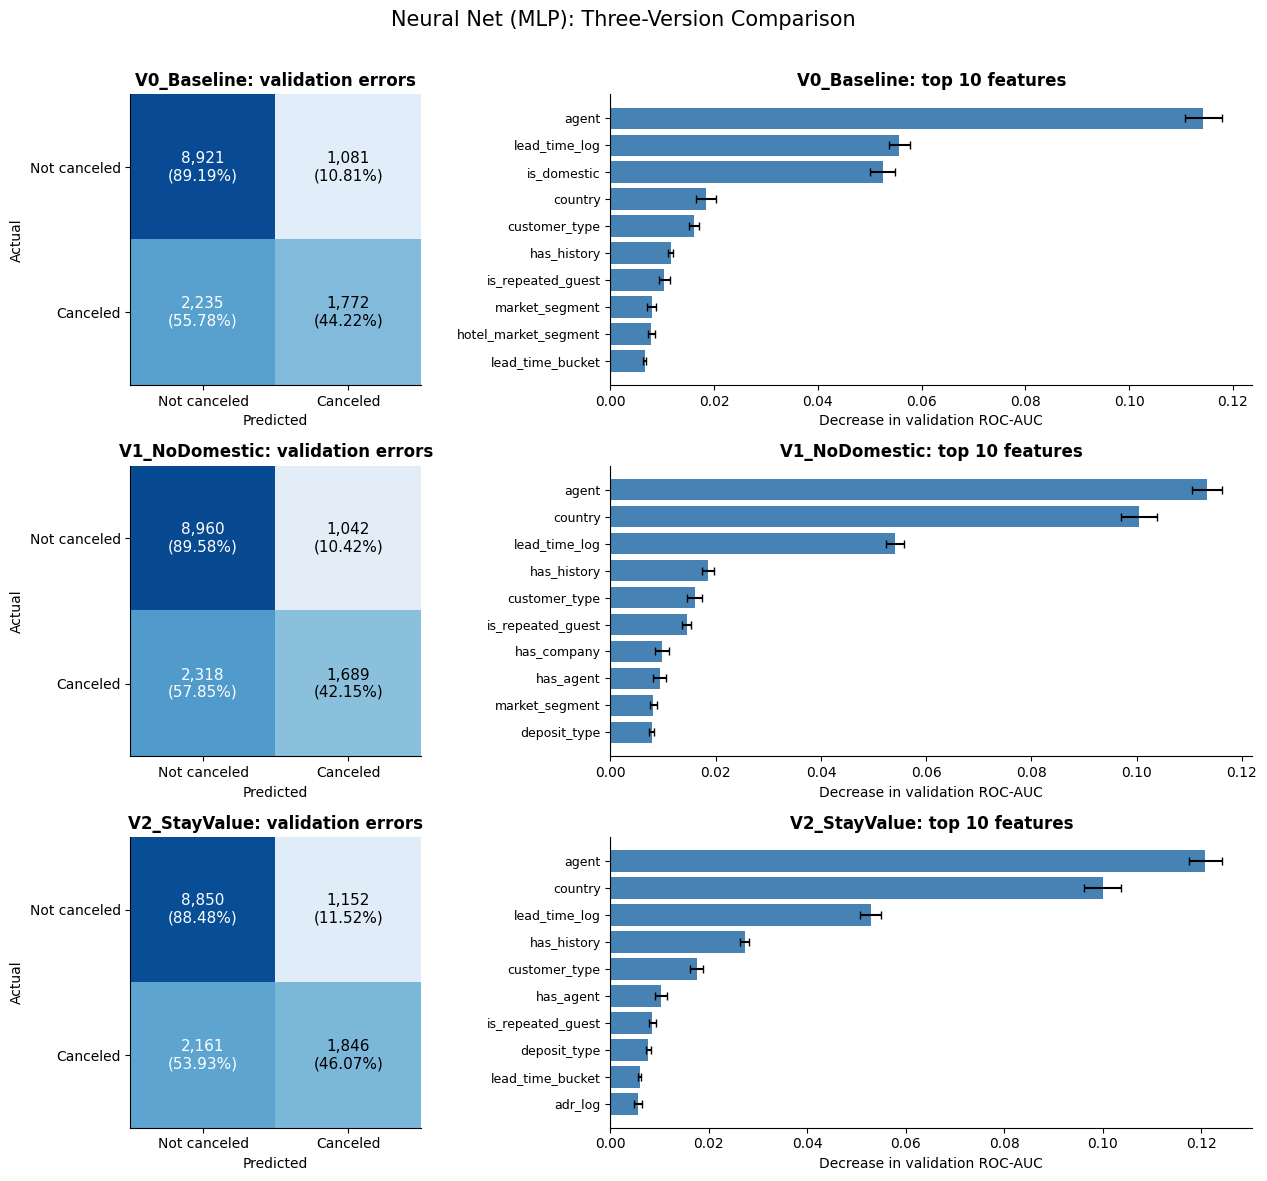

In [144]:
# Summarize the three MLP versions using the existing results
mlp_three_versions, mlp_all_error_comparison = summarize_feature_experiments(
    mlp_results, "Neural Net (MLP)"
)

We compared three MLP versions: the baseline V0, V1 without is_domestic, and V2 with the additional estimated_stay_value feature. On the same validation set at a classification threshold of 0.5, total errors were 3,316, 3,360, and 3,313, respectively. Removing is_domestic reduced false positives but increased false negatives, resulting in more total errors for V1.

V2 achieved the lowest false negative rate of 53.93%, but also the highest false positive rate of 11.52%. Compared with V0, it produced 74 fewer false negatives and 71 more false positives, reducing total errors by only three. V2 is therefore a reasonable candidate when identifying cancellations is the priority, but its overall improvement over V0 is marginal. All three versions still missed more than half of the actual cancellations.

Permutation importance identified agent, country, and lead_time_log as major predictors. The importance of country increased after removing is_domestic, consistent with their overlapping information. The new estimated_stay_value feature did not appear among V2’s ten most important features. 

# 14. Final Model Comparison and Shortlist
## 14.1 Consolidated Results for All Models

In [145]:
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import confusion_matrix

# Collect the existing results without fitting any models
all_model_results, missing_results = {}, []
namespace = globals()

def register_result(model, version, record):
    record = record if isinstance(record, dict) else {}
    absent = [key for key in ["cv_scores", "cases"]
              if not isinstance(record.get(key), pd.DataFrame)]
    if absent:
        missing_results.append(f"{model} / {version}: {', '.join(absent)}")
    else:
        all_model_results[(model, version)] = record

# Read the separately stored LR and Random Forest results
for model, prefix in [("Logistic Regression", "lr"), ("Random Forest", "rf")]:
    for version, suffix in [("V0", ""), ("V1", "_v1"), ("V2", "_v2")]:
        stem = prefix + suffix
        register_result(model, version, {
            key: namespace.get(f"{stem}_{key}")
            for key in ["cv_scores", "cases", "importance", "analysis_model"]
        })

# Read the GNB and MLP result dictionaries
version_keys = {"V0": "V0_Baseline", "V1": "V1_NoDomestic", "V2": "V2_StayValue"}
for model, source in [("Gaussian Naive Bayes", "gnb_results"),
                      ("Neural Net (MLP)", "mlp_results")]:
    saved = namespace.get(source, {})
    for version, key in version_keys.items():
        register_result(model, version, saved.get(key))

# Read the four models completed by the teammate
saved = namespace.get("member_results", {})
for model in ["SGD Logistic", "Extra Trees", "Linear SVM", "Histogram Gradient Boosting"]:
    for version in ["V0", "V1", "V2"]:
        register_result(model, version, saved.get((model, version)))

if missing_results:
    raise RuntimeError(
        "Run the matching CV and validation-analysis cells first:\n"
        + "\n".join(missing_results)
    )

# Calculate metrics from the actual fold scores and validation predictions
metrics = ["ROC_AUC", "Precision", "Recall", "F1", "Brier"]
reference = X_valid_raw.reset_index(drop=True)
expected_actual = np.asarray(y_valid, dtype=int)
rows = []
for (model, version), record in all_model_results.items():
    scores, cases = record["cv_scores"], record["cases"]
    if len(scores) != len(cv_splits):
        raise ValueError(f"{model} {version}: unexpected number of CV folds.")
    if not np.array_equal(cases["Actual"].to_numpy(dtype=int), expected_actual):
        raise ValueError(f"{model} {version}: validation labels or row order differ.")
    if not cases[reference.columns].reset_index(drop=True).equals(reference):
        raise ValueError(f"{model} {version}: validation bookings or row order differ.")
    summary = scores[metrics].agg(["mean", "std"])
    row = {"Model": model, "Version": version}
    for metric in metrics:
        row[f"{metric}_mean"] = summary.loc["mean", metric]
        row[f"{metric}_std"] = summary.loc["std", metric]
    tn, fp, fn, tp = confusion_matrix(
        expected_actual, cases["Predicted"], labels=[0, 1]
    ).ravel()
    row.update({
        "FP": int(fp), "FN": int(fn), "Total_errors": int(fp + fn),
        "Val_FPR_pct": 100 * fp / (tn + fp),
        "Val_FNR_pct": 100 * fn / (fn + tp)
    })
    rows.append(row)

all_model_comparison = pd.DataFrame(rows).sort_values(
    ["Model", "Version"]
).reset_index(drop=True)

# Display a compact table while retaining all numeric means and SDs
comparison_display = all_model_comparison[["Model", "Version"]].copy()
comparison_display["CV AUC ± SD"] = [
    f"{mean:.4f} ± {std:.4f}" for mean, std in zip(
        all_model_comparison["ROC_AUC_mean"], all_model_comparison["ROC_AUC_std"])
]
for metric in ["Precision", "Recall", "F1", "Brier"]:
    comparison_display[f"CV {metric}"] = all_model_comparison[f"{metric}_mean"].map(
        lambda value: f"{value:.4f}" if pd.notna(value) else "N/A")
for label, column in [("Val FPR", "Val_FPR_pct"), ("Val FNR", "Val_FNR_pct")]:
    comparison_display[label] = all_model_comparison[column].map(lambda value: f"{value:.2f}%")

print(f"Models: {all_model_comparison['Model'].nunique()} | Versions: {len(all_model_comparison)}")
display(comparison_display.set_index(["Model", "Version"]))

Models: 8 | Versions: 24


CV AUC ± SD CV Precision CV Recall  \
Model                       Version                                           
Extra Trees                 V0       0.8111 ± 0.0818       0.7507    0.2777   
                            V1       0.8125 ± 0.0830       0.7728    0.2632   
                            V2       0.8170 ± 0.0778       0.7634    0.2642   
Gaussian Naive Bayes        V0       0.7207 ± 0.1067       0.3678    0.7169   
                            V1       0.7208 ± 0.1059       0.3675    0.7190   
                            V2       0.7213 ± 0.1056       0.3676    0.7190   
Histogram Gradient Boosting V0       0.7925 ± 0.0931       0.6949    0.3224   
                            V1       0.7925 ± 0.0931       0.6949    0.3224   
                            V2       0.7928 ± 0.0919       0.7070    0.3040   
Linear SVM                  V0       0.8021 ± 0.0793       0.6615    0.2501   
                            V1       0.8021 ± 0.0793       0.6611    0.2501   
                            V2       0.8016 ± 0.0803       0.6660    0.2528   
Logistic Regression         V0       0.7982 ± 0.0875       0.6637    0.2742   
                            V1       0.7984 ± 0.0871       0.6636    0.2734   
                            V2       0.7982 ± 0.0882       0.6635    0.2744   
Neural Net (MLP)            V0       0.8130 ± 0.0741       0.7096    0.2940   
                            V1       0.8046 ± 0.0824       0.6906    0.3194   
                            V2       0.8091 ± 0.0787       0.6881    0.3179   
Random Forest               V0       0.7998 ± 0.0846       0.7560    0.2610   
                            V1       0.8111 ± 0.0782       0.7750    0.2448   
                            V2       0.8099 ± 0.0815       0.7789    0.2473   
SGD Logistic                V0       0.7950 ± 0.0820       0.6455    0.2504   
                            V1       0.7860 ± 0.0906       0.6478    0.2631   
                            V2       0.7959 ± 0.0860       0.6703    0.2665   

                                      CV F1 CV Brier Val FPR Val FNR  
Model                       Version                                   
Extra Trees                 V0       0.3768   0.1397   3.32%  75.24%  
                            V1       0.3629   0.1384   2.70%  77.64%  
                            V2       0.3625   0.1383   2.51%  78.79%  
Gaussian Naive Bayes        V0       0.4839   0.3466  35.39%  29.17%  
                            V1       0.4847   0.3468  35.75%  28.85%  
                            V2       0.4848   0.3469  35.53%  29.00%  
Histogram Gradient Boosting V0       0.4100   0.1523   8.85%  58.30%  
                            V1       0.4100   0.1523   8.85%  58.30%  
                            V2       0.3946   0.1525   9.27%  56.95%  
Linear SVM                  V0       0.3422      N/A   4.16%  75.39%  
                            V1       0.3422      N/A   4.15%  75.37%  
                            V2       0.3463      N/A   4.19%  75.34%  
Logistic Regression         V0       0.3699   0.1482   5.56%  71.28%  
                            V1       0.3693   0.1482   5.44%  71.35%  
                            V2       0.3708   0.1480   5.53%  71.10%  
Neural Net (MLP)            V0       0.4002   0.1493  10.81%  55.78%  
                            V1       0.4089   0.1520  10.42%  57.85%  
                            V2       0.4242   0.1483  11.52%  53.93%  
Random Forest               V0       0.3578   0.1427   3.02%  77.14%  
                            V1       0.3428   0.1410   2.48%  80.41%  
                            V2       0.3434   0.1401   2.63%  79.69%  
SGD Logistic                V0       0.3355   0.1561   5.16%  76.14%  
                            V1       0.3483   0.1570   5.26%  76.02%  
                            V2       0.3461   0.1556   5.46%  75.89%

## 14.2 Select One Representative Version per Algorithm & Compare Error Overlap Between Models

Selected representative versions: 8


,Model,Version,CV AUC ± SD,CV Precision,CV Recall,CV F1,CV Brier,Val FPR,Val FNR
CV AUC rank,,,,,,,,,
1,Extra Trees,V2,0.8170 ± 0.0778,0.7634,0.2642,0.3625,0.1383,2.51%,78.79%
2,Neural Net (MLP),V0,0.8130 ± 0.0741,0.7096,0.2940,0.4002,0.1493,10.81%,55.78%
3,Random Forest,V1,0.8111 ± 0.0782,0.7750,0.2448,0.3428,0.1410,2.48%,80.41%
4,Linear SVM,V0,0.8021 ± 0.0793,0.6615,0.2501,0.3422,N/A,4.16%,75.39%
5,Logistic Regression,V1,0.7984 ± 0.0871,0.6636,0.2734,0.3693,0.1482,5.44%,71.35%
6,SGD Logistic,V2,0.7959 ± 0.0860,0.6703,0.2665,0.3461,0.1556,5.46%,75.89%
7,Histogram Gradient Boosting,V2,0.7928 ± 0.0919,0.7070,0.3040,0.3946,0.1525,9.27%,56.95%
8,Gaussian Naive Bayes,V2,0.7213 ± 0.1056,0.3676,0.7190,0.4848,0.3469,35.53%,29.00%


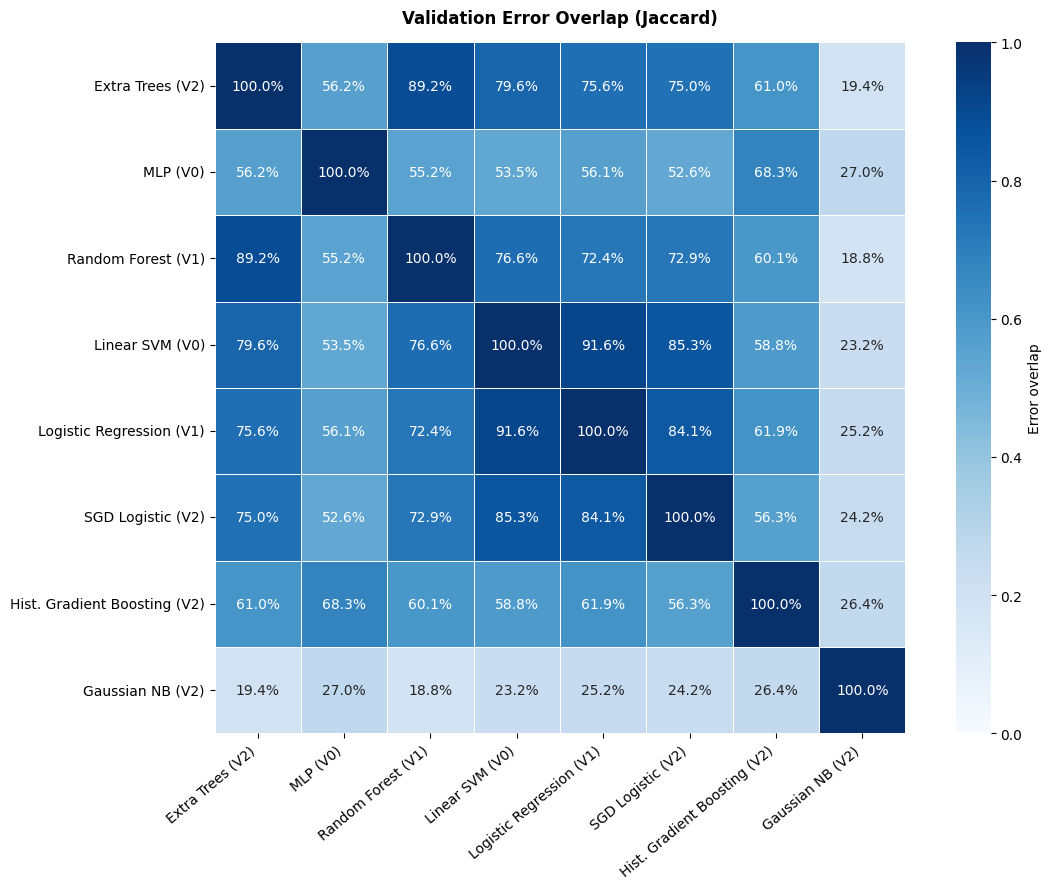

In [150]:
# Select the highest CV AUC version for each algorithm
# Prefer the earlier version when the unrounded AUC means are identical
representative_models = (
    all_model_comparison
    .sort_values(["Model", "ROC_AUC_mean", "Version"],
                 ascending=[True, False, True])
    .drop_duplicates("Model")
    .sort_values("ROC_AUC_mean", ascending=False)
    .reset_index(drop=True)
)

# Display the selected versions using the existing formatted metrics
representative_display = (
    representative_models[["Model", "Version"]]
    .merge(comparison_display, on=["Model", "Version"],
           how="left", validate="one_to_one", sort=False)
)
representative_display.index = range(1, len(representative_display) + 1)
representative_display.index.name = "CV AUC rank"

print(f"Selected representative versions: {len(representative_models)}")
display(representative_display)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Collect validation error flags for the eight selected versions
actual = np.asarray(y_valid, dtype=int)
error_flags = pd.DataFrame(index=range(len(actual)))
short_names = {
    "Neural Net (MLP)": "MLP",
    "Gaussian Naive Bayes": "Gaussian NB",
    "Histogram Gradient Boosting": "Hist. Gradient Boosting"
}

for row in representative_models.itertuples(index=False):
    cases = all_model_results[(row.Model, row.Version)]["cases"]
    if not np.array_equal(cases["Actual"].to_numpy(dtype=int), actual):
        raise ValueError(f"Validation labels or row order differ: {row.Model}")
    label = f"{short_names.get(row.Model, row.Model)} ({row.Version})"
    error_flags[label] = cases["Predicted"].to_numpy(dtype=int) != actual

# Calculate Jaccard overlap between each pair of error sets
error_overlap = pd.DataFrame(
    np.nan, index=error_flags.columns, columns=error_flags.columns
)
for left in error_flags:
    for right in error_flags:
        both = (error_flags[left] & error_flags[right]).sum()
        either = (error_flags[left] | error_flags[right]).sum()
        error_overlap.loc[left, right] = both / either if either else np.nan

# Visualize error overlap at the current classification thresholds
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(
    error_overlap, annot=True, fmt=".1%", cmap="Blues",
    vmin=0, vmax=1, square=True, linewidths=0.5,
    cbar_kws={"label": "Error overlap"}, ax=ax
)
ax.set_title("Validation Error Overlap (Jaccard)", pad=14)
plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
plt.setp(ax.get_yticklabels(), rotation=0)
fig.tight_layout()
plt.show()

The closer this is to 100%, the more often the two models get the same bookings wrong. A lower value means they make errors on different bookings, so they may provide complementary information.

Shortlisted models: <br>
**Extra Trees V2:**  Has the highest mean CV AUC at **0.8170**, making it the main candidate <br>
**MLP V0:**  Has an AUC of **0.8130** and an error overlap of **56.2%** with Extra Trees, offering good performance and a different error pattern <br>
**Logistic Regression V1:**  Is simple, easy to interpret, and provides cancellation probabilities, so it is included as a representative linear model <br>
**Histogram Gradient Boosting V2:**  Has an error overlap of **61.0%** with Extra Trees and a lower false negative rate at the current threshold, offering a different trade-off between false positives and false negatives <br>

Models not selected: <br>
**Random Forest:** Has an error overlap of 89.2% with **Extra Trees** and a slightly lower mean AUC, so Extra Trees is preferred.<br>
**Linear SVM:** Has an error overlap of 91.6% with LR, so LR is preferred because it is easier to interpret and directly outputs probabilities.<br>
**SGD Logistic:** Has a high error overlap with the other linear models and currently shows no clear performance advantage.<br>
**Gaussian NB:** Has a different error pattern, but its AUC is only 0.7213 and its false positive rate is 35.53%, so it is left off this shortlist for now.<br>